# ARLP clustering & TOU tariff design — autonomous computation-proof notebook

**A from-raw, self-contained reproduction of every table and figure of the article.** Unlike a demonstration notebook, this one **computes
the full flow from the raw inputs** and renders the figures from those freshly-computed objects —
it is intended as the *underlying-computation proof / source of truth* for the reported results.

- **Autonomous:** it builds every CSV/NPZ/PNG of `outputs/` from `inputs/` alone; no earlier output
  is read back as a computation input.
- **1:1 verified:** each stage asserts the article's key numbers (hard `assert`s).
- **Helpers** imported are pure computation (`_common`, `arlp_families`, `k_selection`) or
  house-style plotting (`manuscript_style` + the `make_*` renderers); no result loaders.

> **ESH classification.** The 5-class map is derived inline: the 8 non-ESH families are clustered
> at k=3 (→ A/B/C by HH-descending canonicalisation, propagated to member ARLPs) and the 3 ESH
> ARLPs at k=2 on seasonal-TOU features (→ E1/E2). This yields the article's taxonomy
> **ESH-1={ARLP-01}, ESH-2={ARLP-02,03}** (the 7.2-MWh split of Fig. 7 and of the ESH validity sweep) with
> **no manual override**. This split is used **consistently everywhere, including §4.5**.
>
> **Currency.** Every monetary value is in Ukrainian hryvnia (₴), excluding VAT. See the currency
> note in §3.5.

> **Numbering.** The section, table and figure numbers in this notebook follow the article. The correspondence of every notebook cell with the tables and figures of the article is given in the repository README.

## 0 · Setup — imports, paths, house style, verification helpers

In [1]:
import sys, os, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import warnings as _warnings
_fmtw = _warnings.formatwarning   # printed warnings name the file only, not its absolute path
_warnings.formatwarning = lambda m, c, f, ln, line=None: _fmtw(m, c, os.path.basename(f), ln, line)


def find_vault(start=None):
    start = (start or Path.cwd()).resolve()
    for c in [start, *start.parents]:
        if (c / "inputs" / "ARLPs(Segments)_Hourly_Load.csv").exists():
            return c
    raise FileNotFoundError("root folder not found")


VAULT = find_vault()
INP   = VAULT / "inputs"
OUT   = VAULT / "outputs" / "ARLP_Clustering"
DIAG  = OUT / "_unchecked"   # money tables and exports of a run with a failed check (never canonical)
CODE  = VAULT / "code"
if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))
os.chdir(str(CODE))   # the house-style make_* renderers locate the root folder by walking up from cwd

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.spatial.distance import pdist, squareform, jensenshannon
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn_extra.cluster import KMedoids
from scipy.optimize import curve_fit

import manuscript_style as ms
import _common as common
from _common import (build_repday_matrix, build_tou_feature_matrix, NON_ESH_ARLPS, ESH_ARLPS,
                     ARLP_NAMES_ALL, CLUSTER_LABELS_ALL19, ESH_CLUSTERS, WINTER_MONTHS,
                     NON_ESH_BASE_PRICE_UAH, ESH_BASE_PRICE_LOW_UAH, ESH_BASE_PRICE_HIGH_UAH, TOU_PERIODS_0BASED)
from arlp_families import build_families, compute_family_merge_diagnostics
from k_selection import gap_statistic, gap_decision, deduplicate
ms.apply_house_rcparams()

RANDOM_STATE = 42
NON = sorted(NON_ESH_ARLPS)
ESH = sorted(ESH_ARLPS)
OK = []
FAILED = []


def check(name, cond):
    # Hard 1:1 assertion against a manuscript anchor. A failure is recorded before it is raised, so that
    # later cells write their money tables to DIAG instead of the canonical folders.
    if not cond:
        FAILED.append(name)
    assert cond, f"FAIL: {name}"
    OK.append(name); print(f"  [OK] {name}")


SEGMENT_META_ALL = pd.DataFrame({
    "ARLP": ARLP_NAMES_ALL,
    "Location": ["any","any","any","city","city","city","city","city","city","city",
                 "city","rural","rural","rural","rural","rural","rural","rural","rural"],
    "Consumption_band": ["<=7.2","7.2-14.4",">14.4","<=6","<=6","<=6","<=6",">6",">6",
                         ">6",">6","<=6","<=6","<=6","<=6",">6",">6",">6",">6"],
    "Dwelling": ["any","any","any","MFH","MFH","MFH","SFH","MFH","MFH","MFH","SFH",
                 "MFH","MFH","MFH","SFH","MFH","MFH","MFH","SFH"],
    "Bedrooms": ["-","-","-","1","2",">=3","-","1","2",">=3","-","1","2",">=3","-","1","2",">=3","-"],
    "Heating_fuel": ["elec","elec","elec","any","any","any","any","any","any","any",
                     "any","any","any","any","any","any","any","any","any"],
})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
print(f"VAULT = <repository>\n{len(NON)} non-ESH + {len(ESH)} ESH ARLP | house style + KMedoids OK | RANDOM_STATE={RANDOM_STATE}")

VAULT = <repository>
16 non-ESH + 3 ESH ARLP | house style + KMedoids OK | RANDOM_STATE=42


# §3 · Method

**Fig. 1.** Study flow (hand-drawn schematic; embedded as in the manuscript).

*Fig. 1 is a diagram drawn outside the code (see the article); its image is not part of the computation.*

## §3.1 · Data sources

In [2]:
# Raw inputs, cleaned: hyphens in column names -> underscores; weights numeric, missing = 0.
load_df = pd.read_csv(INP / "ARLPs(Segments)_Hourly_Load.csv")
load_df.columns = [c.replace("-", "_") for c in load_df.columns]
load_df["timestamp"] = pd.to_datetime(load_df["timestamp"])
TS = load_df["timestamp"]

wdf = pd.read_csv(INP / "ARLPs_EULPs weight matrix.csv")
wdf.columns = [c.replace("-", "_") for c in wdf.columns]
wdf = wdf.loc[:, ~wdf.columns.str.startswith("Unnamed")]
for c in ARLP_NAMES_ALL:
    wdf[c] = pd.to_numeric(wdf[c], errors="coerce").fillna(0)

HH = pd.read_csv(INP / "arlp_household_counts.csv").set_index("ARLP")["H_kHH"].to_dict()


def cohort_matrices(names):
    return load_df[names].to_numpy().T, wdf[names].to_numpy().T


print("load    :", load_df.shape, " (8760 h x 19 ARLP + timestamp)")
print("weights :", wdf[ARLP_NAMES_ALL].shape)
print("HH total:", round(sum(HH.values())), "kHH")

load    : (8760, 20)  (8760 h x 19 ARLP + timestamp)
weights : (3145, 19)
HH total: 17259 kHH


**Table 1.** ARLP segment metadata (Monakov 2026). Raw AnnGWh/HHths equal the recomputed totals; the ARLP-implied columns are transcribed. `implGWh` sums exactly to 38,169; the manuscript's other total-row values round independently of the rounded rows (±2).

In [3]:
_T2 = [(4281,765,4281,742),(665,64,665,62),(661,35,661,34),(3287,1857,3385,1801),
       (6215,3512,6384,3407),(6075,3433,6417,3330),(3021,1707,3140,1656),(292,26,292,25),
       (551,49,551,47),(539,48,539,46),(268,24,268,23),(22,14,23,13),(149,90,164,88),
       (303,184,330,178),(8808,5340,9781,5180),(3,0,3,0),(21,2,21,2),(42,4,42,4),(1222,105,1222,102)]
TABLE2 = SEGMENT_META_ALL.copy()
TABLE2[["AnnGWh","HHths","implGWh","implHHths"]] = _T2
check("Table1 implGWh total == 38169", int(TABLE2.implGWh.sum()) == 38169)
check("Table1 implHHths ~ 16739", abs(int(TABLE2.implHHths.sum()) - 16739) <= 2)
check("Table1 HHths == HH-CSV total 17259", int(TABLE2.HHths.sum()) == 17259 == round(sum(HH.values())))
TABLE2

  [OK] Table1 implGWh total == 38169
  [OK] Table1 implHHths ~ 16739
  [OK] Table1 HHths == HH-CSV total 17259


,ARLP,Location,Consumption_band,Dwelling,Bedrooms,Heating_fuel,AnnGWh,HHths,implGWh,implHHths
0,ARLP_01,any,<=7.2,any,-,elec,4281,765,4281,742
1,ARLP_02,any,7.2-14.4,any,-,elec,665,64,665,62
2,ARLP_03,any,>14.4,any,-,elec,661,35,661,34
3,ARLP_04,city,<=6,MFH,1,any,3287,1857,3385,1801
4,ARLP_05,city,<=6,MFH,2,any,6215,3512,6384,3407
5,ARLP_06,city,<=6,MFH,>=3,any,6075,3433,6417,3330
6,ARLP_07,city,<=6,SFH,-,any,3021,1707,3140,1656
7,ARLP_08,city,>6,MFH,1,any,292,26,292,25
8,ARLP_09,city,>6,MFH,2,any,551,49,551,47
9,ARLP_10,city,>6,MFH,>=3,any,539,48,539,46


## §3.2 · Stratification and consolidation

The 16 non-ESH ARLPs form 8 city/rural counterpart pairs; each is merged into one HH-weighted **family** (convex combination of the two members' per-HH profiles and EULP weights). The 3 ESH ARLPs form their own stratum.

In [4]:
L_non, W_non = cohort_matrices(NON)
seg_non = SEGMENT_META_ALL[SEGMENT_META_ALL.ARLP.isin(NON)].reset_index(drop=True)
fam = build_families(L_non, W_non, seg_non, NON, HH)
check("8 non-ESH families", len(fam.family_ids) == 8)
pd.DataFrame({"family_id": fam.family_ids,
              "members": [", ".join(fam.family_membership[f]) for f in fam.family_ids],
              "H_kHH": np.round(fam.family_household_counts, 1)})

  [OK] 8 non-ESH families


,family_id,members,H_kHH
0,FAM_04_12,"ARLP_04, ARLP_12",1871.0
1,FAM_05_13,"ARLP_05, ARLP_13",3602.0
2,FAM_06_14,"ARLP_06, ARLP_14",3617.0
3,FAM_07_15,"ARLP_07, ARLP_15",7047.0
4,FAM_08_16,"ARLP_08, ARLP_16",26.0
5,FAM_09_17,"ARLP_09, ARLP_17",51.0
6,FAM_10_18,"ARLP_10, ARLP_18",52.0
7,FAM_11_19,"ARLP_11, ARLP_19",129.0


## §3.3 · Representative load clustering

**Lens 1 (compositional):** Jensen–Shannon distance on the 16 EULP-weight vectors → feeds Fig 2.
**Lens 2 (shape):** a 6-D seasonal 3-zone TOU feature vector per family (3 zone means × 2 seasons),
z-scored within the cohort, then PAM (k-medoids).

In [5]:
def lens1_distances(Wmat):
    rs = Wmat.sum(1, keepdims=True)
    Wn = Wmat / np.where(rs > 0, rs, 1)
    Wn = (Wn + 1e-12); Wn = Wn / Wn.sum(1, keepdims=True)
    return squareform(pdist(Wn, jensenshannon)), squareform(pdist(Wn, "cosine"))


jsd, cosd = lens1_distances(W_non)
JSD  = pd.DataFrame(jsd,  index=NON, columns=NON)
COSD = pd.DataFrame(cosd, index=NON, columns=NON)
print(f"no-overlap JSD reference max = {jsd.max():.3f}")


def lens2_features(cohort_load, names):
    rep = build_repday_matrix(cohort_load, TS, names)
    Xdf = build_tou_feature_matrix(rep, arlp_names=names)
    X = Xdf.to_numpy(float)
    sd = X.std(0, ddof=0, keepdims=True)
    return Xdf, X, (X - X.mean(0, keepdims=True)) / np.where(sd > 0, sd, 1.0)


def pam_validity(Xz, names, ks):
    rows = []
    for k in ks:
        pam = KMedoids(n_clusters=k, metric="euclidean", method="pam", random_state=RANDOM_STATE).fit(Xz)
        rows.append({"k": k, "silhouette": silhouette_score(Xz, pam.labels_),
                     "davies_bouldin": davies_bouldin_score(Xz, pam.labels_),
                     "calinski_harabasz": calinski_harabasz_score(Xz, pam.labels_),
                     "medoids": ", ".join(names[i] for i in pam.medoid_indices_)})
    return pd.DataFrame(rows)


FEAT_fam_df, X_fam, Xz_fam = lens2_features(fam.family_load_matrix, fam.family_ids)
VALID_fam = pam_validity(Xz_fam, fam.family_ids, range(2, min(8, len(fam.family_ids))))
VALID_fam.round(3)

no-overlap JSD reference max = 0.833


,k,silhouette,davies_bouldin,calinski_harabasz,medoids
0,2,0.393,0.825,7.101,"FAM_09_17, FAM_05_13"
1,3,0.383,0.556,9.912,"FAM_07_15, FAM_06_14, FAM_09_17"
2,4,0.274,0.526,8.726,"FAM_06_14, FAM_07_15, FAM_09_17, FAM_10_18"
3,5,0.200,0.412,8.026,"FAM_09_17, FAM_07_15, FAM_10_18, FAM_05_13, FA..."
4,6,0.255,0.248,18.947,"FAM_09_17, FAM_07_15, FAM_10_18, FAM_05_13, FA..."
5,7,0.155,0.145,26.647,"FAM_07_15, FAM_11_19, FAM_06_14, FAM_05_13, FA..."


## §3.4 · Cluster validation

Non-ESH families: silhouette near-ties at k=2 (0.393) / k=3 (0.383); DBI 0.83→0.56, CHI 9.91 at k=3;
the gap statistic's 1-SE rule selects **k=3**. The 3-ARLP ESH cohort admits only **k=2** → the ESH validity sweep.

In [6]:
_vf = VALID_fam.set_index("k")
check("non-ESH sil k2~0.393", abs(_vf.loc[2,"silhouette"] - 0.393) < 2e-3)
check("non-ESH sil k3~0.383", abs(_vf.loc[3,"silhouette"] - 0.383) < 2e-3)
check("non-ESH DBI k3~0.556", abs(_vf.loc[3,"davies_bouldin"] - 0.556) < 3e-3)
check("non-ESH CHI k3~9.912", abs(_vf.loc[3,"calinski_harabasz"] - 9.912) < 0.05)

Xz_D, names_D, _ = deduplicate(Xz_fam, list(fam.family_ids), eps=1e-6)
GAP = gap_statistic(Xz_D, list(range(1, min(7, len(names_D)-1)+1)), B=100, ref="uniform_aabb", random_state=RANDOM_STATE)
kstar, rule = gap_decision(GAP, rule="1se", candidate_min_k=2)
check("gap 1-SE selects k=3", kstar == 3 and rule == "1se")

L_esh, _ = cohort_matrices(ESH)
FEAT_esh_df, X_esh, Xz_esh = lens2_features(L_esh, ESH)
TABLE5 = pam_validity(Xz_esh, ESH, [2]); _t5 = TABLE5.iloc[0]
check("ESH sweep sil~0.094", abs(_t5.silhouette - 0.094) < 5e-3)
check("ESH sweep DBI~0.470", abs(_t5.davies_bouldin - 0.470) < 5e-3)
check("ESH sweep CHI~1.51", abs(_t5.calinski_harabasz - 1.51) < 0.02)
check("ESH sweep medoids {01,03}", set(_t5.medoids.replace(' ','').split(',')) == {"ARLP_01","ARLP_03"})
display(TABLE5.round(3))

  [OK] non-ESH sil k2~0.393
  [OK] non-ESH sil k3~0.383
  [OK] non-ESH DBI k3~0.556
  [OK] non-ESH CHI k3~9.912
  [OK] gap 1-SE selects k=3
  [OK] ESH sweep sil~0.094
  [OK] ESH sweep DBI~0.470
  [OK] ESH sweep CHI~1.51
  [OK] ESH sweep medoids {01,03}


,k,silhouette,davies_bouldin,calinski_harabasz,medoids
0,2,0.094,0.47,1.507,"ARLP_01, ARLP_03"


## §3.3 / §4.3 · The five tariff classes (derived inline)

**Non-ESH → A/B/C:** PAM(k=3) on the 8-family z-scored 6-D TOU features; clusters relabelled by
HH-weighted size descending (rank 0/1/2 = A/B/C); each of the 16 member ARLPs inherits its family's
class. **ESH → E1/E2:** PAM(k=2) on the seasonal-TOU features (the source of the ESH validity sweep), HH-descending
(765 kHH → E1={01}; 99 kHH → E2={02,03}). No stored cluster CSV, no manual override.

In [7]:
_pam_fam = KMedoids(3, metric="euclidean", method="pam", random_state=RANDOM_STATE).fit(Xz_fam)
_fam_raw = {fam.family_ids[i]: int(_pam_fam.labels_[i]) for i in range(len(fam.family_ids))}
_fam_H = {f: float(np.asarray(fam.family_household_counts)[i]) for i, f in enumerate(fam.family_ids)}
_ne_sizes = pd.Series(_fam_H).groupby(_fam_raw).sum().sort_values(ascending=False)
_ne_canon = {raw: rank for rank, raw in enumerate(_ne_sizes.index.tolist())}
CLUSTER_OF = {}
for f in fam.family_ids:
    for member in fam.family_membership[f]:
        CLUSTER_OF[member] = _ne_canon[_fam_raw[f]]

_pam_esh = KMedoids(2, metric="euclidean", method="pam", random_state=RANDOM_STATE).fit(Xz_esh)
_esh_raw = {ESH[i]: int(_pam_esh.labels_[i]) for i in range(len(ESH))}
_esh_sizes = pd.Series({n: HH[n] for n in ESH}).groupby(_esh_raw).sum().sort_values(ascending=False)
_esh_canon = {raw: 3 + rank for rank, raw in enumerate(_esh_sizes.index.tolist())}
for n in ESH:
    CLUSTER_OF[n] = _esh_canon[_esh_raw[n]]
H_all = dict(HH)

_DEF = {**{n: 0 for n in ["ARLP_04","ARLP_05","ARLP_06","ARLP_12","ARLP_13","ARLP_14"]},
        **{n: 1 for n in ["ARLP_07","ARLP_15"]},
        **{n: 2 for n in ["ARLP_08","ARLP_09","ARLP_10","ARLP_11","ARLP_16","ARLP_17","ARLP_18","ARLP_19"]},
        "ARLP_01": 3, "ARLP_02": 4, "ARLP_03": 4}
check("5-class map: A={04,05,06,12,13,14} B={07,15} C={08..19} E1={01} E2={02,03}", CLUSTER_OF == _DEF)
_NAME6 = {0:"A",1:"B",2:"C",3:"ESH-1",4:"ESH-2"}
pd.Series({n: _NAME6[CLUSTER_OF[n]] for n in ARLP_NAMES_ALL}, name="class").to_frame().T

  [OK] 5-class map: A={04,05,06,12,13,14} B={07,15} C={08..19} E1={01} E2={02,03}


,ARLP_01,ARLP_02,ARLP_03,ARLP_04,ARLP_05,ARLP_06,ARLP_07,ARLP_08,ARLP_09,ARLP_10,ARLP_11,ARLP_12,ARLP_13,ARLP_14,ARLP_15,ARLP_16,ARLP_17,ARLP_18,ARLP_19
class,ESH-1,ESH-2,ESH-2,A,A,A,B,C,C,C,C,A,A,A,B,C,C,C,C


## §3.5 · Tariff design (inline, revenue-neutral block rule)

Per (class, season): HH-weighted class load `C[c][s]`; block contribution coefficients
`cpeak, coff`; multipliers `α_peak=1+cpeak`, `α_off=1-coff`; the shoulder `λ` is the closed-form
value enforcing exact revenue neutrality (clipped to `[α_off, α_peak]`). Non-ESH rates = α × ₴3.60/kWh;
ESH rates are bands over the two NEURC regimes (₴2.20/kWh in October–April up to 2,000 kWh per month /
₴3.60/kWh otherwise), excluding VAT. The ESH bills (Table 6) use a fixed effective winter base per class and TOU zone:
the 2,000-kWh rule (whole monthly volume; the wording before 1 February 2025 kept as a modelling assumption) applied to
each source ARLP's per-household consumption of each October–April month, weighted by households × consumption. The
rates, Table 4 and the PEED price signals stay statutory.

**Currency and VAT.**
All monetary values are in Ukrainian hryvnia (₴) and exclude VAT. Retail rates are the fixed
household prices set under Cabinet of Ministers Resolution No. 483 of 5 June 2019 (as amended) and
published by NEURC for 1 June 2024 – 31 October 2026 [4]: ₴3.60/kWh, and ₴2.20/kWh for ESH
households in October–April up to 2,000 kWh per month (₴4.32 and ₴2.64 including 20 % VAT). Hourly
DAM prices are OREE clearing prices [26] for 29 September 2024 – 29 September 2025, mapped to the
2018 load calendar by calendar date and hour. DAM-based savings are valued at a retail-equivalent
price: the DAM price plus the transmission and distribution tariffs in force on each delivery day.
DAM prices and network tariffs exclude VAT. The 25 hours missing from the DAM record
(including 27 July 2025) are filled from the converted USD series at the exchange rate of the same
or nearest day. No other exchange rate is used.

In this notebook: the constants `NON_ESH_BASE_PRICE_UAH`, `ESH_BASE_PRICE_LOW_UAH` and
`ESH_BASE_PRICE_HIGH_UAH` of `_common.py` (checked against `inputs/neurc_household_tariffs_uah.csv`),
and `inputs/hourly_dam_prices_uah.csv`, built by
`build_dam_prices_uah.py`.

In [8]:
load_all19 = load_df[ARLP_NAMES_ALL].to_numpy().T
rep2_all19 = build_repday_matrix(load_all19, TS, ARLP_NAMES_ALL)
seasons = ["winter", "summer"]
clusters_all = sorted(set(CLUSTER_OF.values()))
FLAT_RATE, _ESH_LO, _ESH_HI = NON_ESH_BASE_PRICE_UAH, ESH_BASE_PRICE_LOW_UAH, ESH_BASE_PRICE_HIGH_UAH   # ₴/kWh excl. VAT


def _block_all(name, seg):
    return rep2_all19.loc[name, [f"{seg}_h{h:02d}" for h in range(24)]].to_numpy(float)


C_season_all = {c: {s: np.zeros(24) for s in seasons} for c in clusters_all}
for n in ARLP_NAMES_ALL:
    for s in seasons:
        C_season_all[CLUSTER_OF[n]][s] += H_all[n] * _block_all(n, s)
Ctot_season_all = {s: sum(C_season_all[c][s] for c in clusters_all) for s in seasons}

PEAK_H, OFF_H = [9,10,11,21,22], [0,1,2,3,4,5,6,7]
SHO_H = [h for h in range(24) if h not in PEAK_H and h not in OFF_H]
_final = []
ALPHA_FULL = {}   # full-precision alpha for display only (Table 4); the model uses final_df's 4 decimals
for c in clusters_all:
    for s in seasons:
        Ck, Ctot = C_season_all[c][s], Ctot_season_all[s]
        cpeak = Ck[PEAK_H].sum()/Ctot[PEAK_H].sum(); coff = Ck[OFF_H].sum()/Ctot[OFF_H].sum()
        a_peak, a_off = 1 + cpeak, 1 - coff
        E_P, E_O, E_S = Ck[PEAK_H].sum(), Ck[OFF_H].sum(), Ck[SHO_H].sum()
        lam = float(np.clip(1 - (cpeak*E_P - coff*E_O)/E_S, a_off, a_peak))
        _final.append({"cluster": c, "label": CLUSTER_LABELS_ALL19[c],
                       "stratum": "esh" if c in ESH_CLUSTERS else "non_esh", "season": s,
                       "alpha_off": round(a_off,4), "alpha_shoulder": round(lam,4), "alpha_peak": round(a_peak,4)})
        ALPHA_FULL[(CLUSTER_LABELS_ALL19[c], s)] = (a_off, lam, a_peak)
final_df = pd.DataFrame(_final)

_ANCH = {("Class A","winter"):(0.596,1.006,1.419),("Class A","summer"):(0.499,1.039,1.490),
         ("Class B","winter"):(0.701,0.994,1.322),("Class C","summer"):(0.945,0.996,1.063),
         ("Class E1 (ESH)","winter"):(0.846,1.039,1.128),("Class E2 (ESH)","winter"):(0.950,1.009,1.044)}
for (lab,s),exp in _ANCH.items():
    r = final_df[(final_df.label==lab)&(final_df.season==s)].iloc[0]
    check(f"Table4 alpha {lab} {s}", np.allclose([r.alpha_off,r.alpha_shoulder,r.alpha_peak], exp, atol=1.5e-3))
final_df.round(4)

  [OK] Table4 alpha Class A winter
  [OK] Table4 alpha Class A summer
  [OK] Table4 alpha Class B winter
  [OK] Table4 alpha Class C summer
  [OK] Table4 alpha Class E1 (ESH) winter
  [OK] Table4 alpha Class E2 (ESH) winter


,cluster,label,stratum,season,alpha_off,alpha_shoulder,alpha_peak
0,0,Class A,non_esh,winter,0.5960,1.0064,1.4191
1,0,Class A,non_esh,summer,0.4987,1.0391,1.4900
2,1,Class B,non_esh,winter,0.7013,0.9942,1.3215
3,1,Class B,non_esh,summer,0.6507,1.0220,1.3447
4,2,Class C,non_esh,winter,0.9062,1.0112,1.0879
5,2,Class C,non_esh,summer,0.9449,0.9961,1.0627
6,3,Class E1 (ESH),esh,winter,0.8461,1.0389,1.1276
7,3,Class E1 (ESH),esh,summer,0.9269,0.9933,1.0851
8,4,Class E2 (ESH),esh,winter,0.9504,1.0091,1.0438
9,4,Class E2 (ESH),esh,summer,0.9788,1.0051,1.0175


## §3.6 · Demand-response model (PEED)

Four published residential 2×2 peak/off-peak elasticity matrices; their unweighted mean is the
headline (**Table 2**), extended to a 3×3 with a shoulder-inert rule for the load-shift maths.

In [9]:
_PEED_DIR = INP / "peed_matrices_residential_avg"
SOURCES = ["auray2019","filippini1995a","massimo2011_short","massimo2011_long"]
PEED_SRC = {s: pd.read_csv(_PEED_DIR / f"source_{s}.csv", index_col=0) for s in SOURCES}
PEED_AVG = sum(PEED_SRC[s] for s in SOURCES) / len(SOURCES)
_eps = lambda m: [m.loc["peak","peak"], m.loc["peak","off-peak"], m.loc["off-peak","peak"], m.loc["off-peak","off-peak"]]
check("PEED mean == the averaged input file", np.allclose(_eps(PEED_AVG), _eps(pd.read_csv(_PEED_DIR/"peed_avg_2x2.csv", index_col=0)), atol=1e-9))
check("PEED mean == manuscript -1.41/0.94/0.90/-1.65", np.allclose(_eps(PEED_AVG), [-1.41,0.94,0.90,-1.65], atol=6e-3))

ZONES_3 = ["peak","shoulder","off-peak"]
def build_3x3(M2):
    epp,eoo = M2.loc["peak","peak"], M2.loc["off-peak","off-peak"]
    epo,eop = M2.loc["peak","off-peak"], M2.loc["off-peak","peak"]
    M3 = pd.DataFrame(0.0, index=ZONES_3, columns=ZONES_3)
    M3.loc["peak","peak"]=epp; M3.loc["peak","off-peak"]=epo
    M3.loc["off-peak","peak"]=eop; M3.loc["off-peak","off-peak"]=eoo
    M3.loc["shoulder","shoulder"]=0.5*(epp+eoo)
    return M3
PEED_3 = build_3x3(PEED_AVG)
display(pd.DataFrame([dict(Source=s, **dict(zip(["eps_PP","eps_PO","eps_OP","eps_OO"], _eps(PEED_SRC[s])))) for s in SOURCES]
                     + [dict(Source="Mean", **dict(zip(["eps_PP","eps_PO","eps_OP","eps_OO"], _eps(PEED_AVG))))]).round(2))

  [OK] PEED mean == the averaged input file
  [OK] PEED mean == manuscript -1.41/0.94/0.90/-1.65


,Source,eps_PP,eps_PO,eps_OP,eps_OO
0,auray2019,-1.47,0.46,0.85,-1.87
1,filippini1995a,-1.41,0.41,1.57,-2.57
2,massimo2011_short,-0.81,0.86,0.38,-0.70
3,massimo2011_long,-1.94,2.04,0.80,-1.46
4,Mean,-1.41,0.94,0.90,-1.65


# §4 · Results

## §4.1 · Consolidated representative loads

In [10]:
FEAT_arlp_df = lens2_features(L_non, NON)[0]
diag = compute_family_merge_diagnostics(fam, load_matrix=L_non, weight_matrix=W_non, arlp_names=NON,
                                        household_counts=HH, jsd_matrix=JSD, cosine_matrix=COSD,
                                        tou_feature_matrix=FEAT_arlp_df)
TABLE4 = diag[["family_id","jsd_eulp","cosine_eulp","pearson_corr_8760h"]].reset_index(drop=True)
TABLE4.round(3)

,family_id,jsd_eulp,cosine_eulp,pearson_corr_8760h
0,FAM_04_12,0.157,0.003,0.989
1,FAM_05_13,0.000,0.000,1.000
2,FAM_06_14,0.234,0.012,0.952
3,FAM_07_15,0.234,0.012,0.987
4,FAM_08_16,0.111,0.002,1.000
5,FAM_09_17,0.041,0.001,1.000
6,FAM_10_18,0.047,0.000,1.000
7,FAM_11_19,0.013,0.001,0.999


**Fig. 2.** Jensen–Shannon distance heatmap of the 16 non-ESH ARLP EULP-weight vectors (Ward-ordered). Rendered by the house-style generator from the **freshly-computed** `JSD` matrix written just above — not from any pre-existing artifact.

wrote outputs\ARLP_Clustering\non_esh\lens1_compositional\jsd_heatmap_recolored.png  (162 KB)
informative vmax=0.25  plateau=0.833  hatched=224 cells
clustered order: ['ARLP_05', 'ARLP_13', 'ARLP_11', 'ARLP_19', 'ARLP_09', 'ARLP_17', 'ARLP_10', 'ARLP_18', 'ARLP_08', 'ARLP_16', 'ARLP_04', 'ARLP_12', 'ARLP_06', 'ARLP_14', 'ARLP_07', 'ARLP_15']


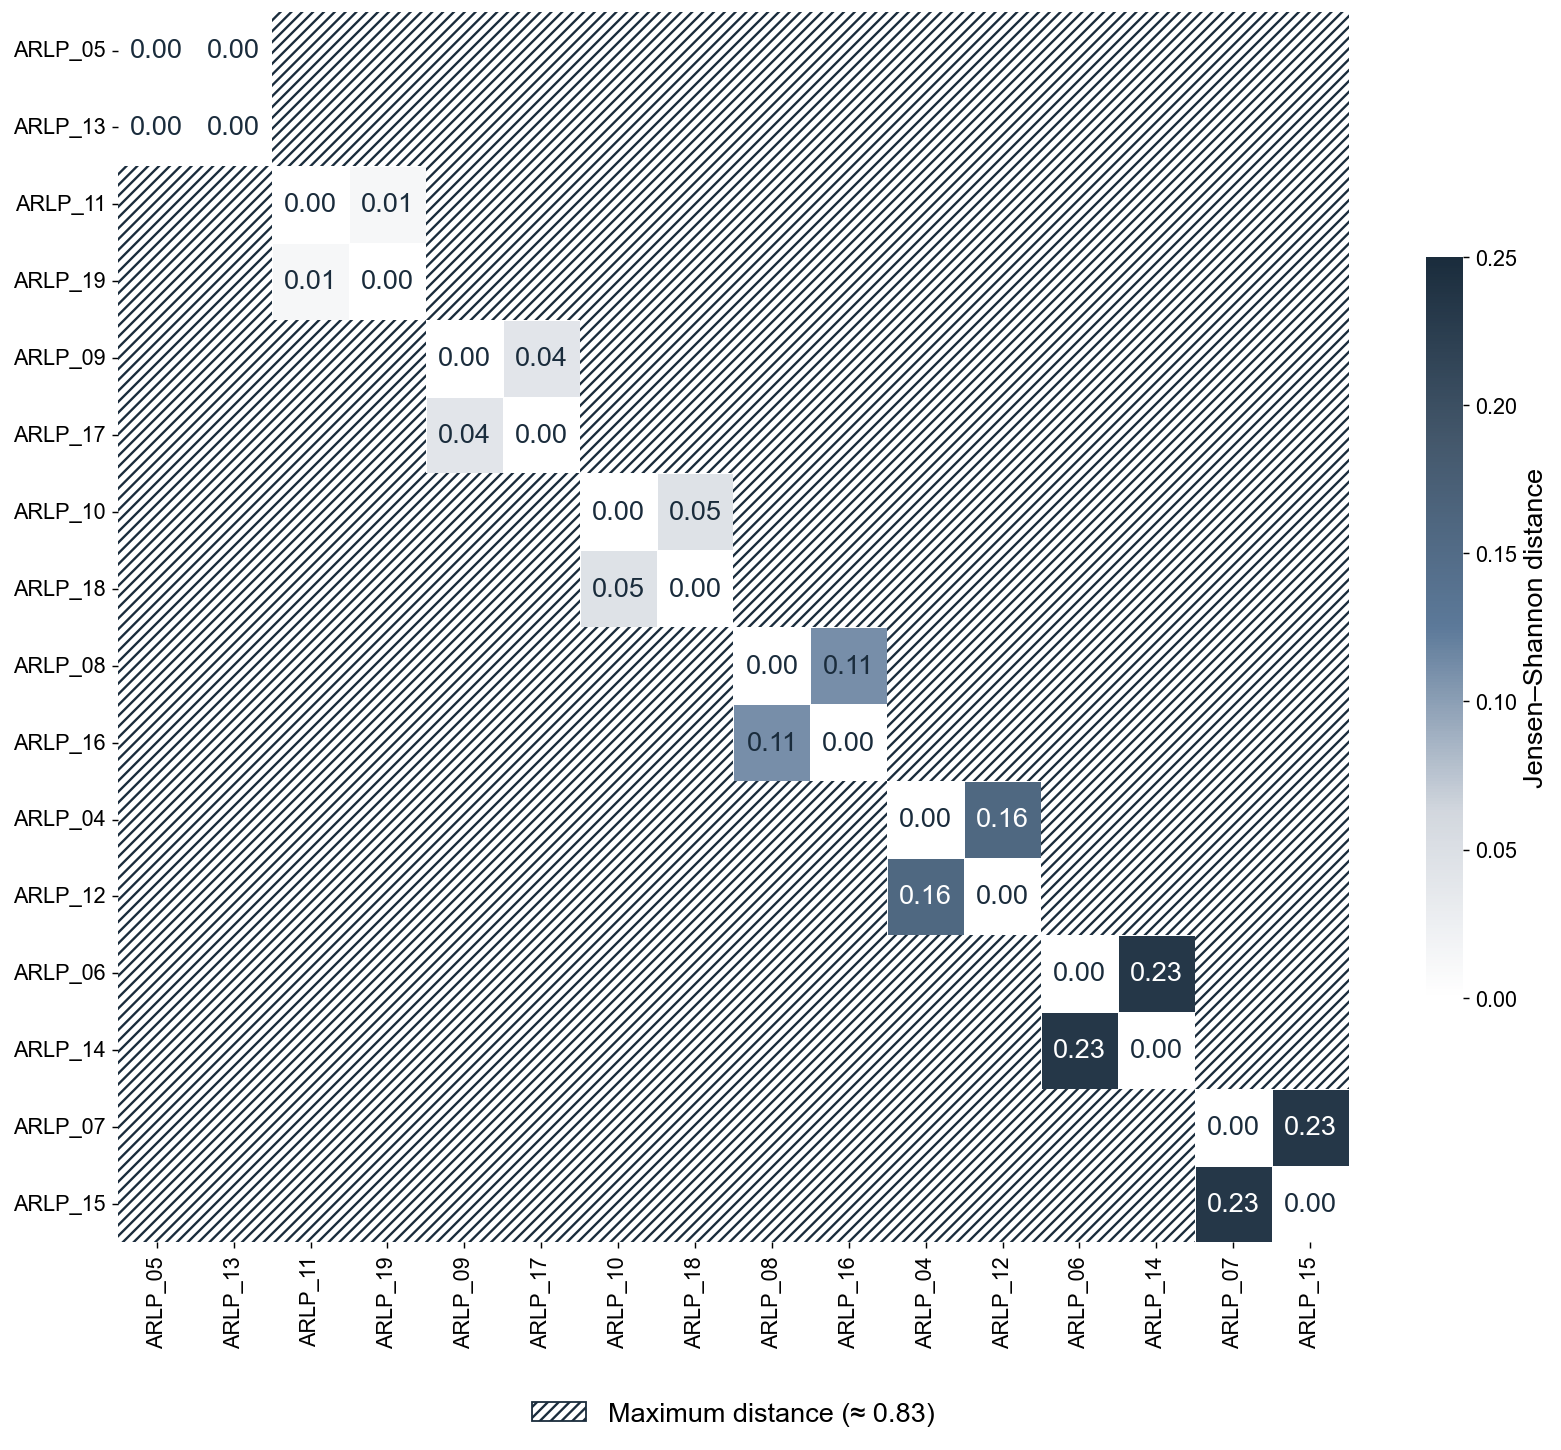

In [11]:
(OUT/"non_esh"/"lens1_compositional").mkdir(parents=True, exist_ok=True)
JSD.to_csv(OUT/"non_esh"/"lens1_compositional"/"jsd_distance_matrix.csv")     # this run's JSD
import make_jsd_heatmap; importlib.reload(make_jsd_heatmap); make_jsd_heatmap.main()
Image(str(OUT/"non_esh"/"lens1_compositional"/"jsd_heatmap_recolored.png"))

**Fig. 3.** Representative load shapes — 8 non-ESH families, 3 ESH ARLPs, and DAM 2021–2024 (load and retail-equivalent price in nominal ₴/kWh excluding VAT: the DAM workbook's gross price, DAM price + network tariffs). The generator recomputes the family/ESH rep-days and DAM series directly from the raw `ARLPs(Segments)_Hourly_Load.csv`, `arlp_household_counts.csv`, and `DAM_*.xlsx`.

wrote outputs\ARLP_Clustering\tou_annotation\representative_load_shapes_grid.png  (823 KB)


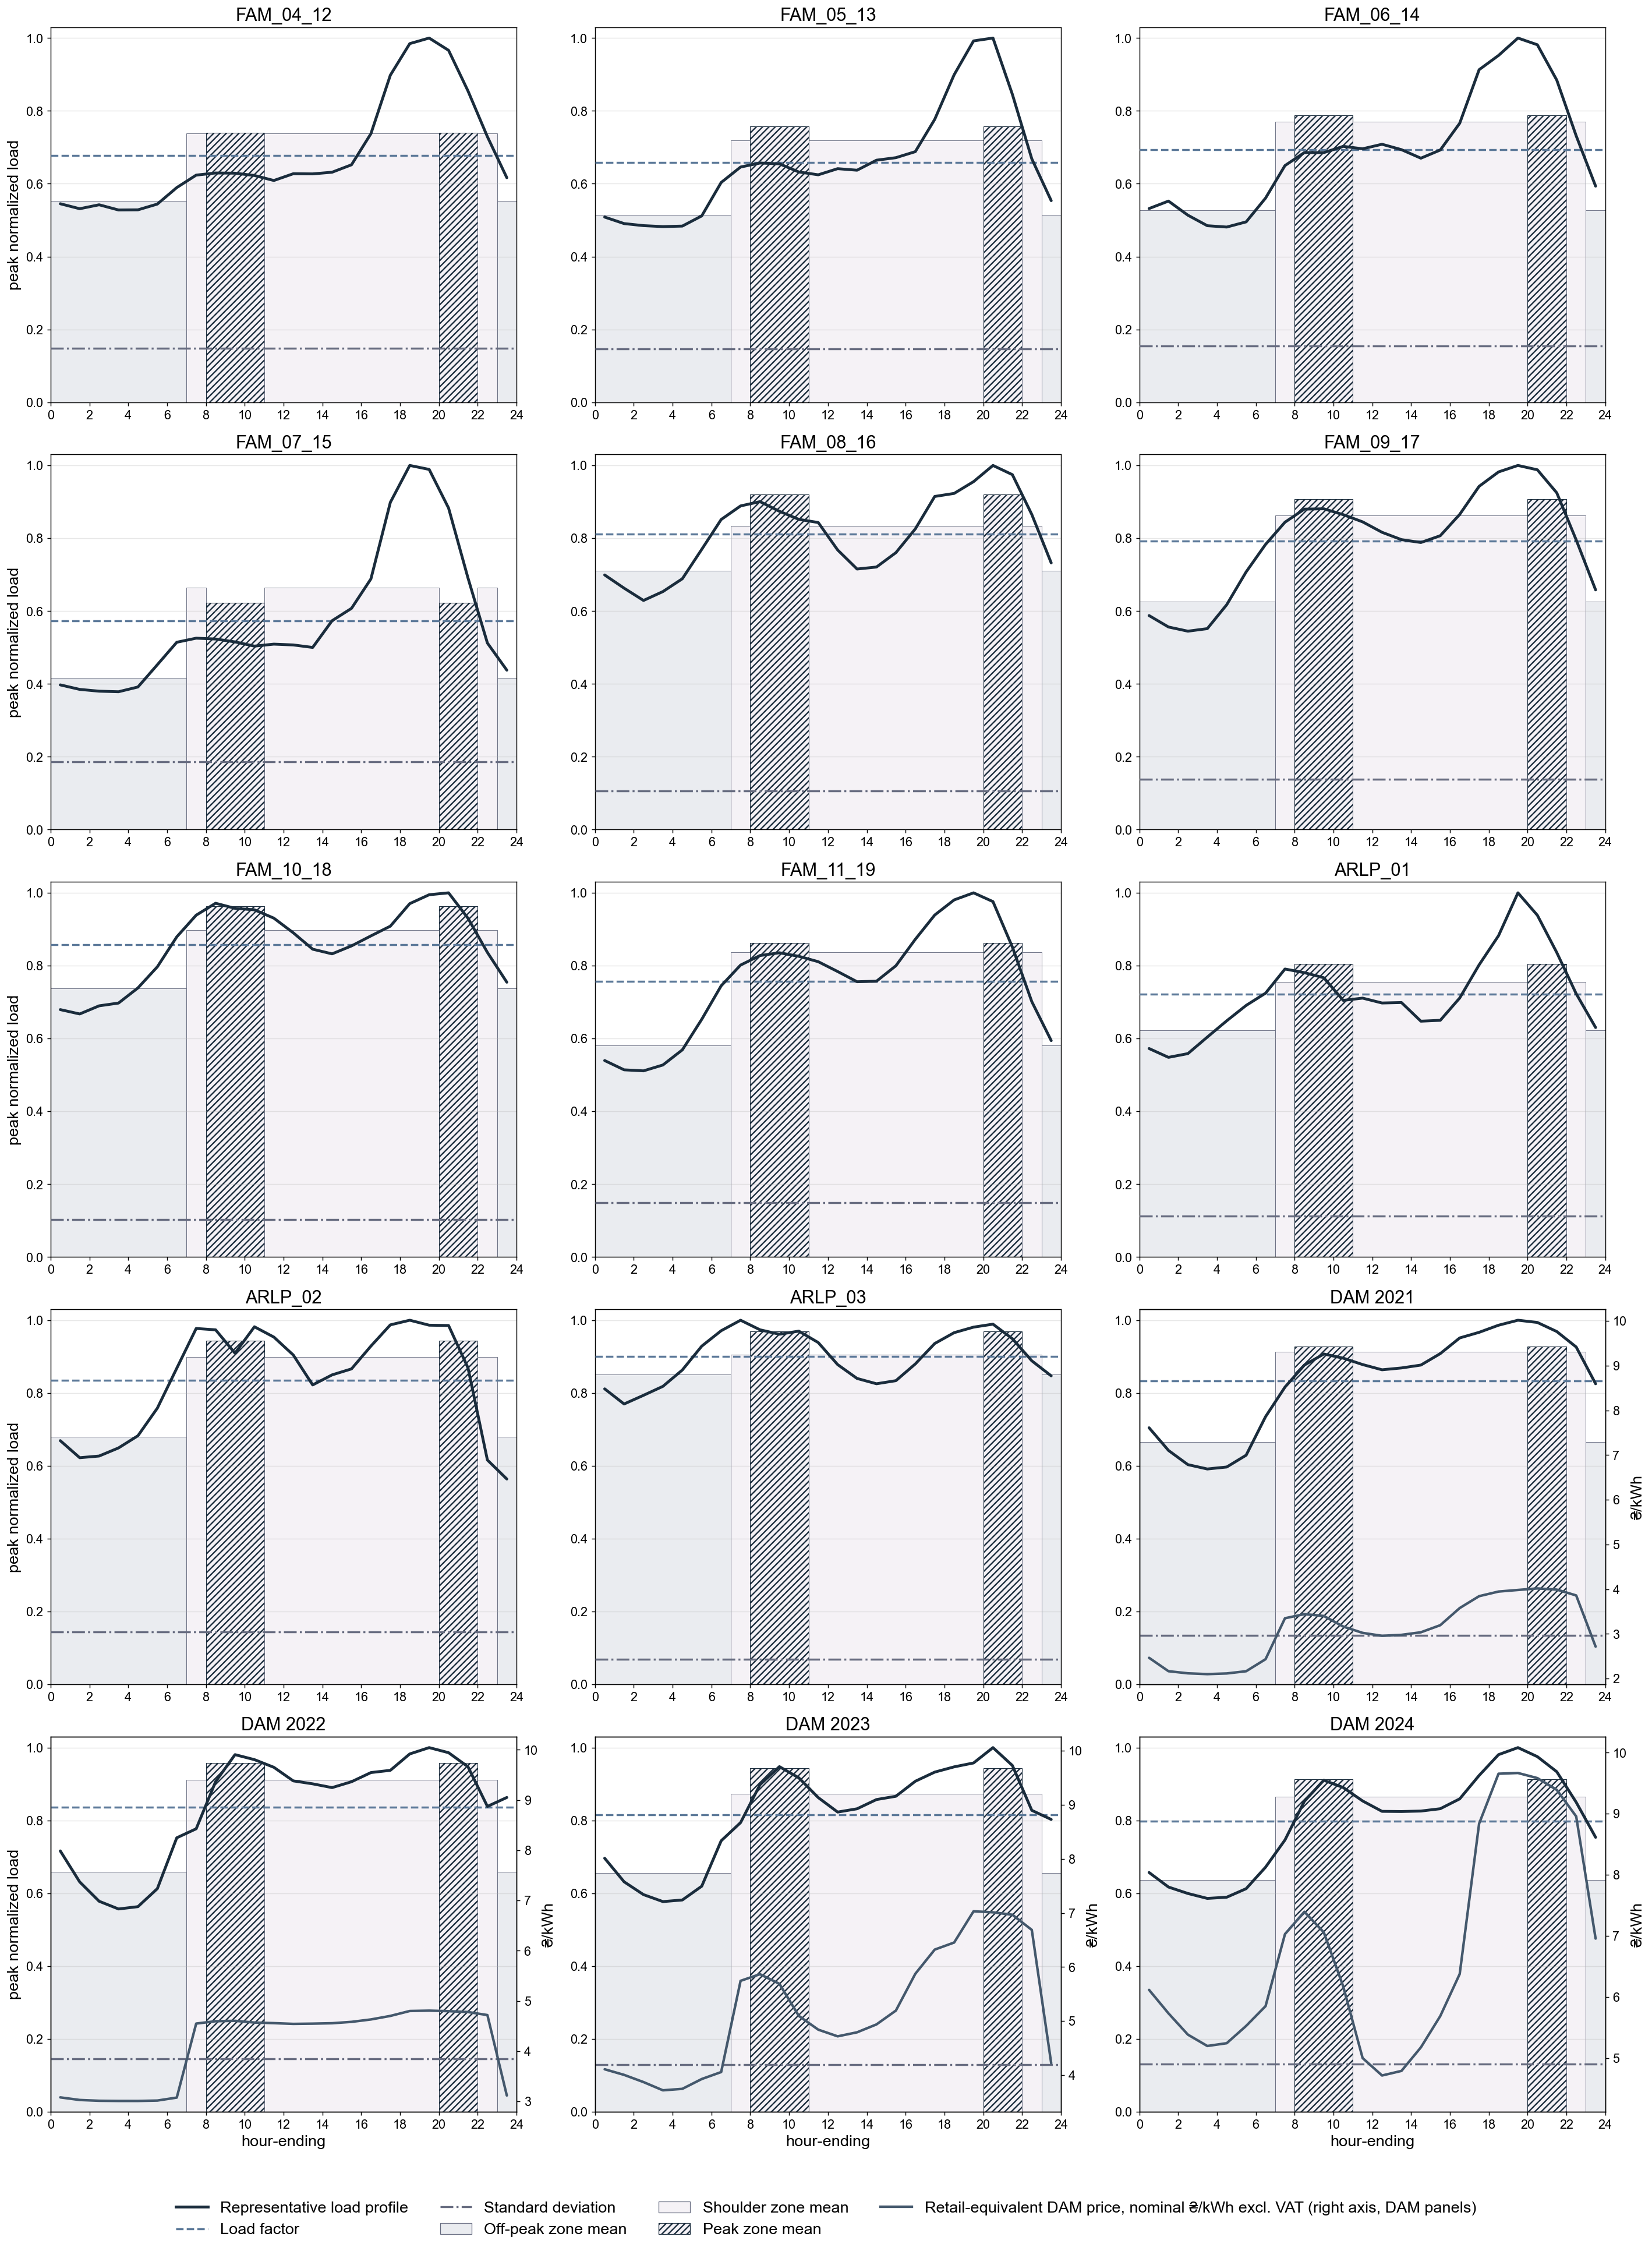

In [12]:
import make_representative_load_shapes as _m3; importlib.reload(_m3); _m3.main()
Image(str(OUT/"tou_annotation"/"representative_load_shapes_grid.png"))

## §4.2 · Partition into classes

**Fig. 5.** PCA maps on the seasonal 3-zone TOU feature space: (a) non-ESH families, (b) ESH ARLPs. Scores are the **inline** `PCA(2)` fit of the same z-scored matrices used for clustering.

wrote outputs\ARLP_Clustering\tou_annotation\pca_maps_combined.png  (163 KB)
  cluster [FAM_06_14]: ['FAM_04_12', 'FAM_05_13', 'FAM_06_14']
  cluster [FAM_09_17]: ['FAM_08_16', 'FAM_09_17', 'FAM_10_18', 'FAM_11_19']
  cluster [FAM_07_15]: ['FAM_07_15']


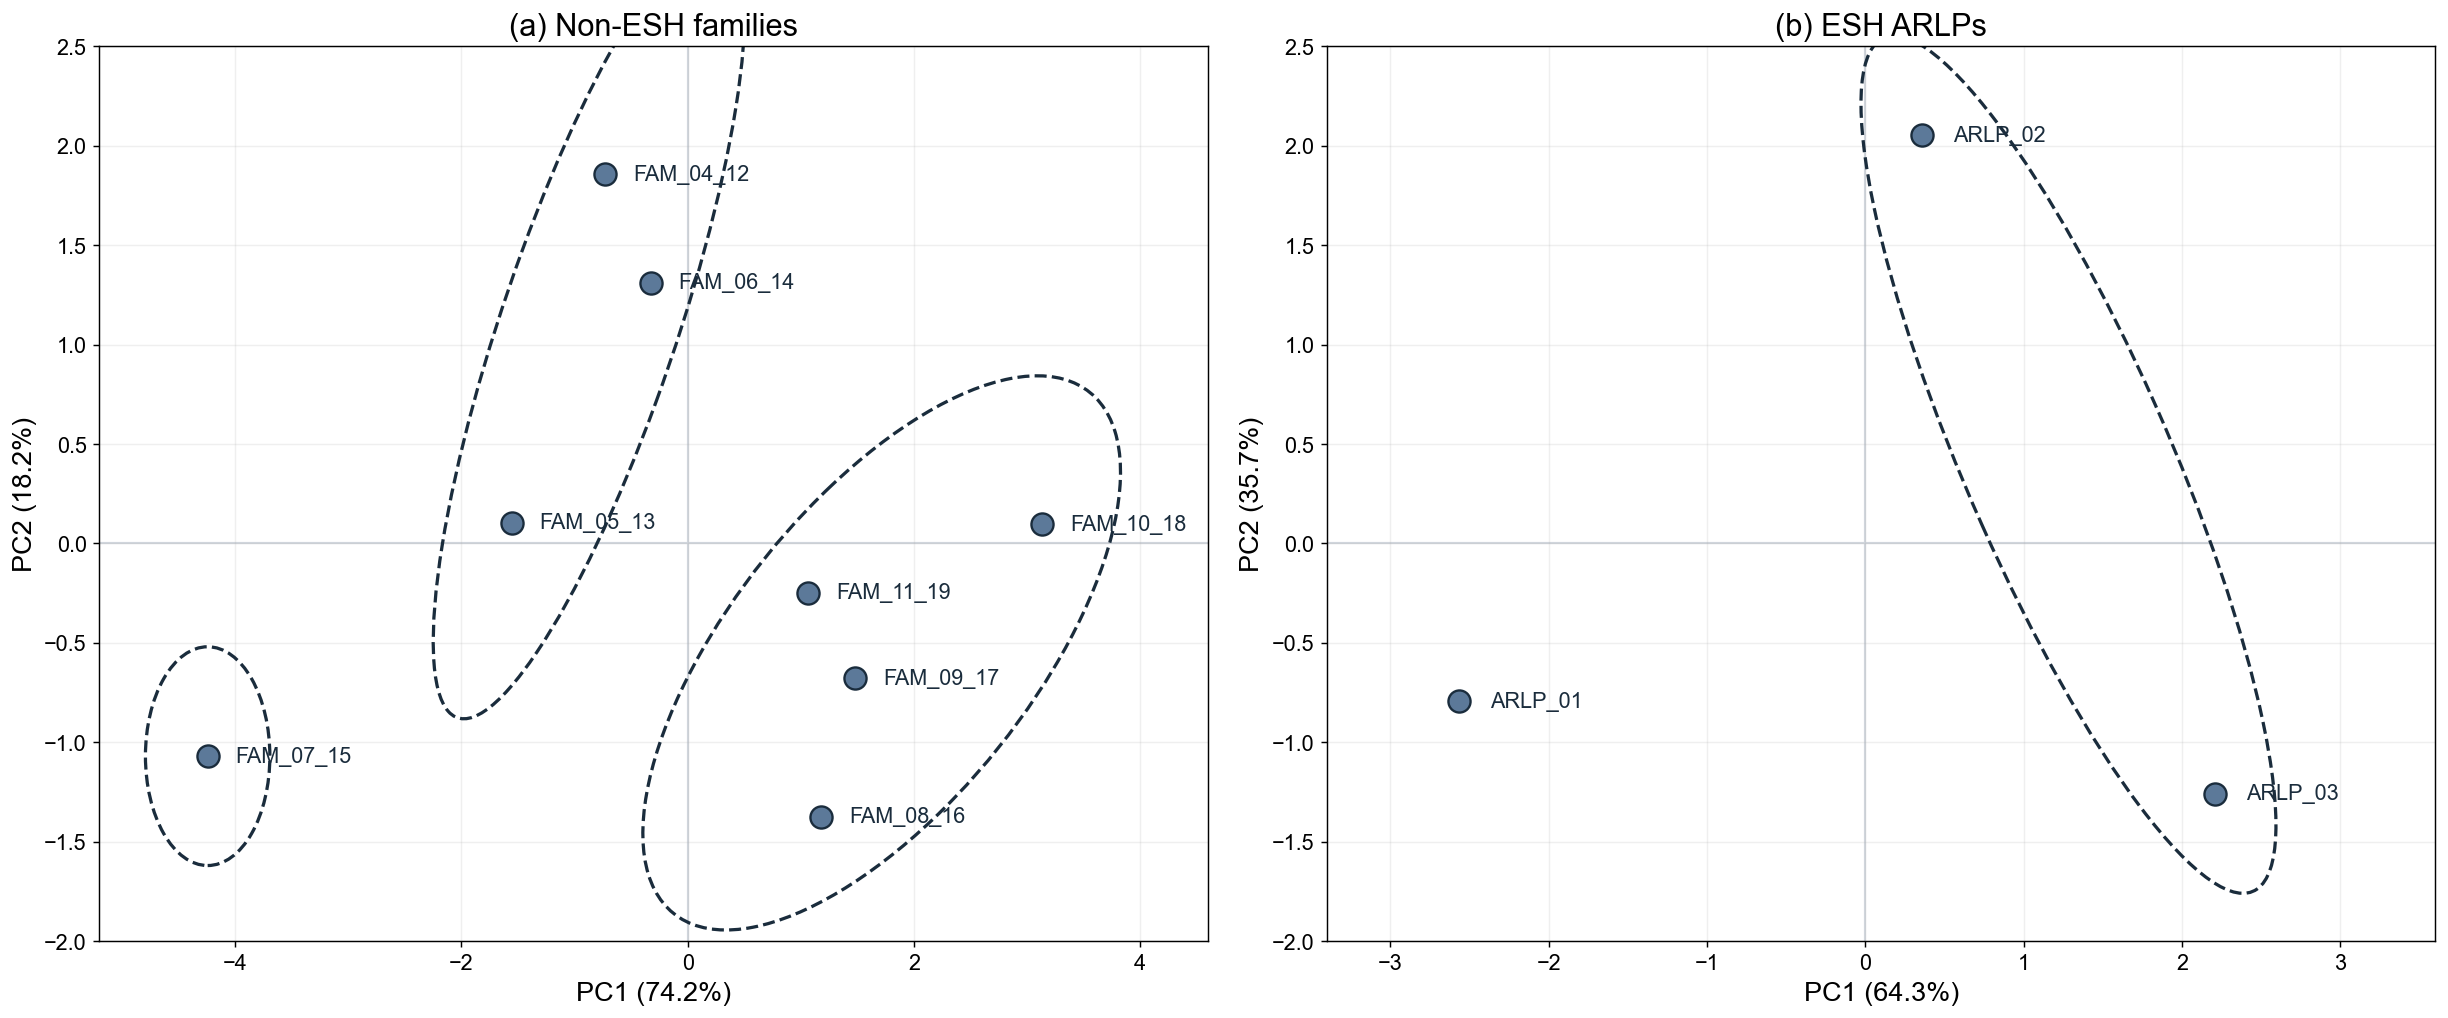

In [13]:
def _write(df, rel, **kw):
    p = OUT/rel; p.parent.mkdir(parents=True, exist_ok=True); df.to_csv(p, **kw); return p


_pf = PCA(2, random_state=RANDOM_STATE).fit(Xz_fam); _sf = _pf.transform(Xz_fam)
_write(pd.DataFrame({"family_id": list(fam.family_ids), "PC1": _sf[:,0], "PC2": _sf[:,1]}),
       "non_esh/lens2_families/pca_family_scores_6d.csv", index=False)
_write(pd.DataFrame({"component": ["PC1","PC2"], "explained_variance_ratio": _pf.explained_variance_ratio_}),
       "non_esh/lens2_families/pca_explained_variance_6d.csv", index=False)
_pe = PCA(2, random_state=RANDOM_STATE).fit(Xz_esh); _se = _pe.transform(Xz_esh)
_write(pd.DataFrame({"ARLP": ESH, "PC1": _se[:,0], "PC2": _se[:,1]}),
       "esh/lens2_tou_features/pca_arlp_scores_6d.csv", index=False)
_write(pd.DataFrame({"component": ["PC1","PC2"], "explained_variance_ratio": _pe.explained_variance_ratio_}),
       "esh/lens2_tou_features/pca_arlp_explained_variance_6d.csv", index=False)
import make_pca_maps_combined as _m4; importlib.reload(_m4); _m4.main()
Image(str(OUT/"tou_annotation"/"pca_maps_combined.png"))

**Fig. 4.** Cluster-validity indices (a–c) and the gap statistic (d, ±1 SE) vs $k$ for the 8-family non-ESH cohort; the 1-SE rule selects **k=3**. Drawn from the inline `VALID_fam` and `GAP` tables.

wrote outputs\ARLP_Clustering\non_esh\lens2_families_kselection\kselection_grid.png  (195 KB)
kstar = 3


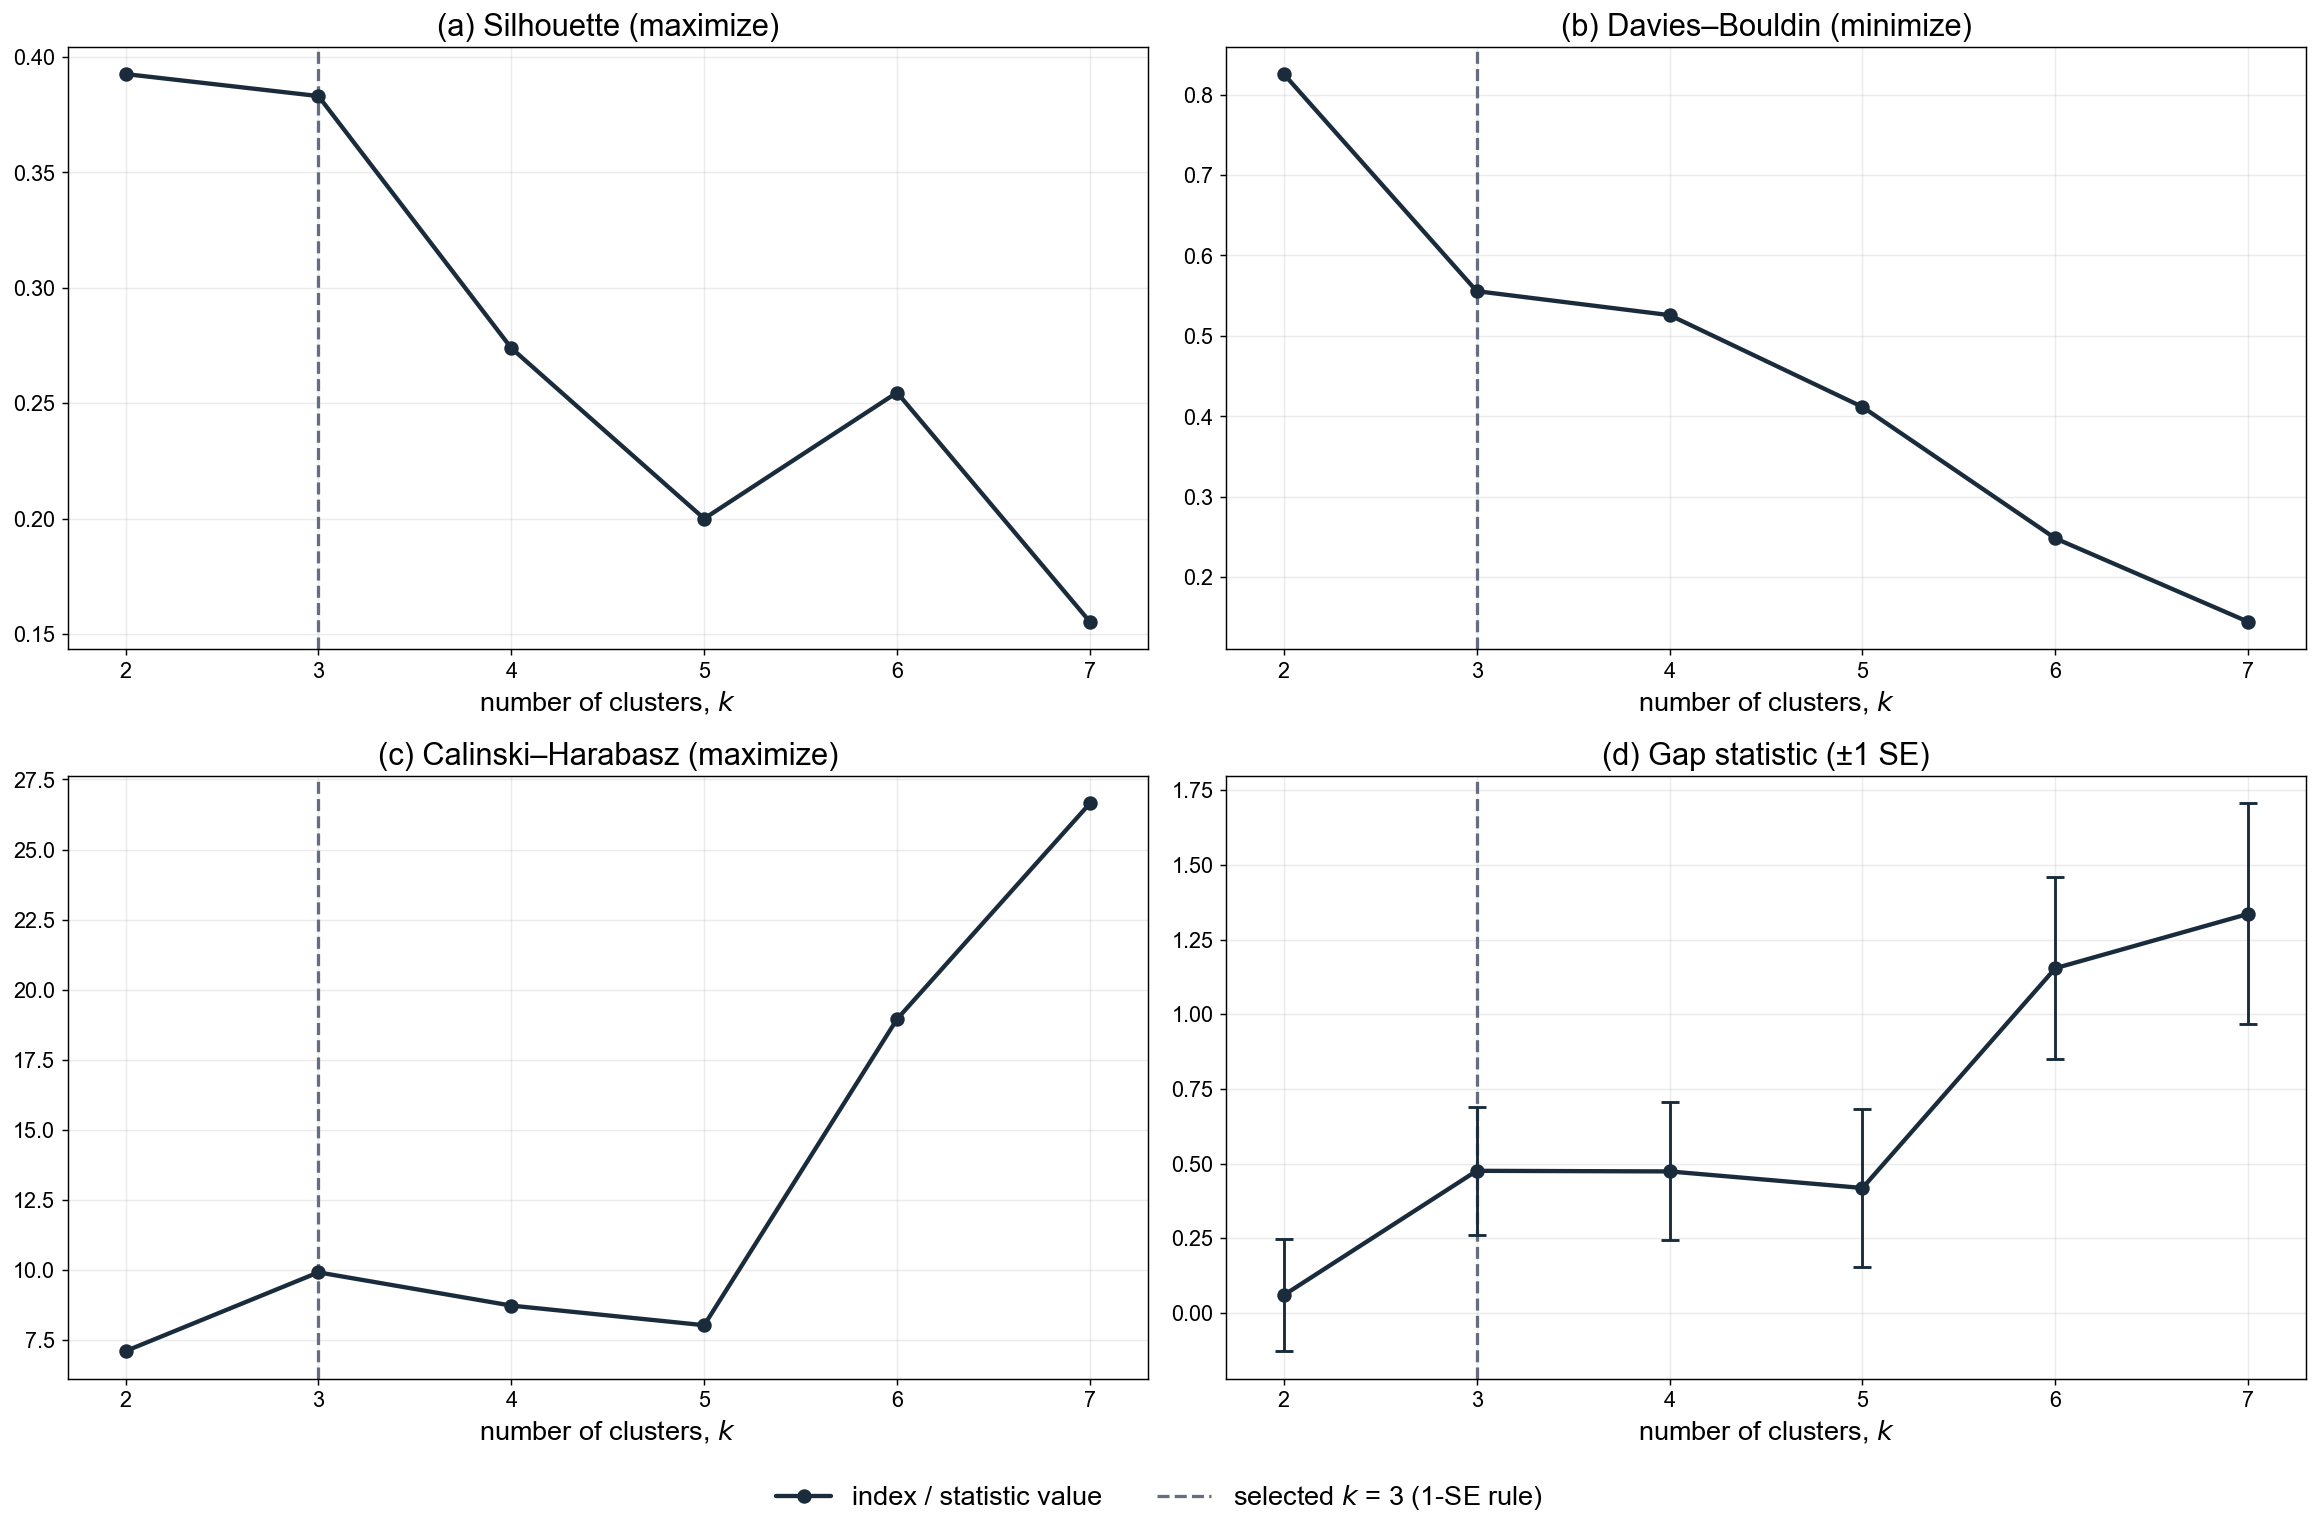

In [14]:
_write(VALID_fam[["k","silhouette","davies_bouldin","calinski_harabasz"]],
       "non_esh/lens2_families/validity_indices.csv", index=False)
_g = GAP.reset_index()[["k","gap_k","s_k"]].copy()
_g["decision_flag"] = np.where(_g["k"] == kstar, "k_star_1se", "")
_write(_g, "non_esh/lens2_families_kselection/gap_statistic.csv", index=False)
import make_kselection_grid as _m5; importlib.reload(_m5); _m5.main()
Image(str(OUT/"non_esh"/"lens2_families_kselection"/"kselection_grid.png"))

**ESH validity sweep** (not a table of the article). Validity index sweep on the ESH cohort (k=2 is the only non-trivial split).

In [15]:
TABLE5.round(3)

,k,silhouette,davies_bouldin,calinski_harabasz,medoids
0,2,0.094,0.47,1.507,"ARLP_01, ARLP_03"


## §4.3 · Resulting classes

In [16]:
_t = TABLE2.assign(cls=TABLE2.ARLP.map(CLUSTER_OF))
g = _t.groupby("cls").agg(ARLPs=("ARLP","count"), AnnGWh=("AnnGWh","sum"), implGWh=("implGWh","sum"),
                          HHths=("HHths","sum"), implHHths=("implHHths","sum"))
g["impl_GWh_share"] = (100*g.implGWh/g.implGWh.sum()).round(1)
g["impl_HH_share"]  = (100*g.implHHths/g.implHHths.sum()).round(1)
g.index = [_NAME6[i] for i in g.index]
_MAN6 = {"A":(43.8,52.7),"B":(33.9,40.8),"C":(7.7,1.5),"ESH-1":(11.2,4.4),"ESH-2":(3.5,0.6)}
for cls,(gs,hs) in _MAN6.items():
    check(f"Fig6 shares {cls}", abs(g.loc[cls,"impl_GWh_share"]-gs)<0.15 and abs(g.loc[cls,"impl_HH_share"]-hs)<0.15)
TABLE6 = g.reset_index().rename(columns={"index":"Class"}); TABLE6

  [OK] Fig6 shares A
  [OK] Fig6 shares B
  [OK] Fig6 shares C
  [OK] Fig6 shares ESH-1
  [OK] Fig6 shares ESH-2


,Class,ARLPs,AnnGWh,implGWh,HHths,implHHths,impl_GWh_share,impl_HH_share
0,A,6,16051,16703,9090,8817,43.8,52.7
1,B,2,11829,12921,7047,6836,33.9,40.8
2,C,8,2938,2938,258,249,7.7,1.5
3,ESH-1,1,4281,4281,765,742,11.2,4.4
4,ESH-2,2,1326,1326,99,96,3.5,0.6


**Fig. 6.** Resulting tariff classes (hand-drawn schematic; embedded as in the manuscript).

*Fig. 6 is a diagram drawn outside the code (see the article). Its household and energy shares are computed and checked above (`TABLE6`, checks `Fig6 shares …`).*

**Fig. 7.** Tariff-class assignment tree over HH attributes (ESH split at 7.2 MWh/y, then consumption + dwelling). Hand-coded schematic — no data input.

wrote <repository>\outputs\ARLP_Clustering\notebook_figures\assignment_tree_full.png


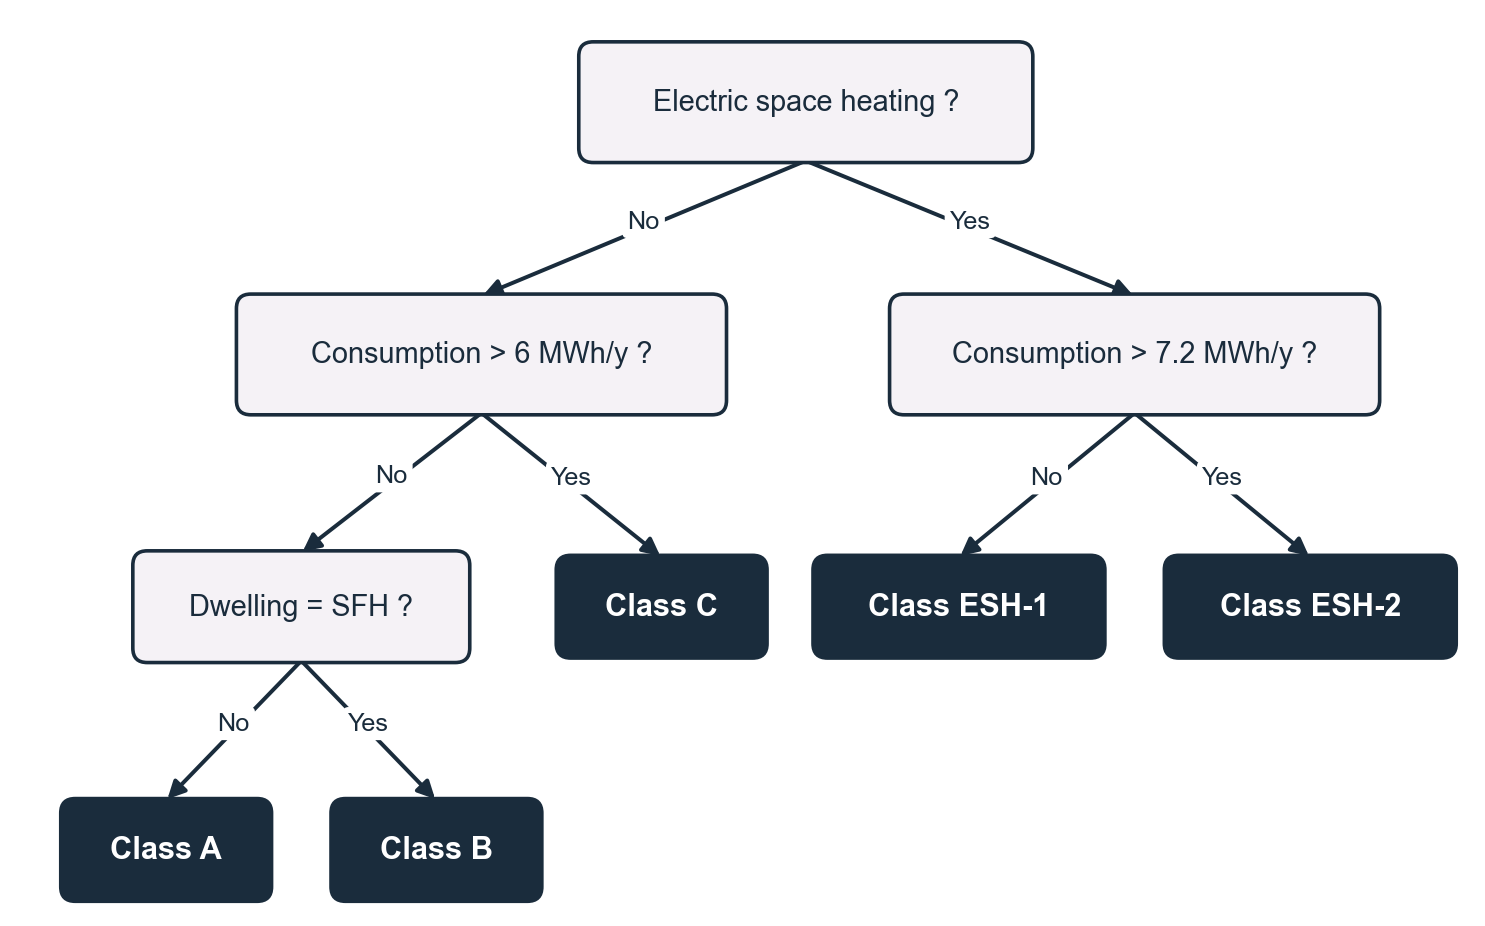

In [17]:
import contextlib, io
import make_assignment_tree_full as _m7; importlib.reload(_m7)
with contextlib.redirect_stdout(io.StringIO()) as _log:   # no absolute path in the output
    _m7.main()
print(_log.getvalue().replace(str(VAULT), "<repository>"), end="")
Image(str(OUT/"notebook_figures"/"assignment_tree_full.png"))

## Validation of the TOU reduction

The tariff-oriented reduction of the full profiles to the 6 TOU-zone means does not change the
non-ESH partition: PAM(k=3) on the seasonal representative-day (48-h peak-normalised) profiles and
on the 6-D TOU means give **ARI = 1.000**.

In [18]:
P_rep = KMedoids(3, metric="euclidean", method="pam", random_state=RANDOM_STATE).fit(Xz_fam).labels_
_rep48 = build_repday_matrix(fam.family_load_matrix, TS, fam.family_ids).to_numpy(float)
_rep48 = _rep48 / _rep48.max(1, keepdims=True)
P_full = KMedoids(3, metric="euclidean", method="pam", random_state=RANDOM_STATE).fit(_rep48).labels_
ari = adjusted_rand_score(P_full, P_rep)
check("ARI(8760-h rep-day, 6-D TOU means) k=3 == 1.000", np.isclose(ari, 1.0))
print(f"ARI = {ari:.3f}")

  [OK] ARI(8760-h rep-day, 6-D TOU means) k=3 == 1.000
ARI = 1.000


**Seasonal load profiles** (not in the article) — 8 non-ESH families + 3 ESH ARLPs + DAM 2023/2024. Generator recomputes all series from the raw load + DAM workbook.

wrote outputs\ARLP_Clustering\non_esh\notebook_figures\repday_overlay_2season_house.png  (431 KB)


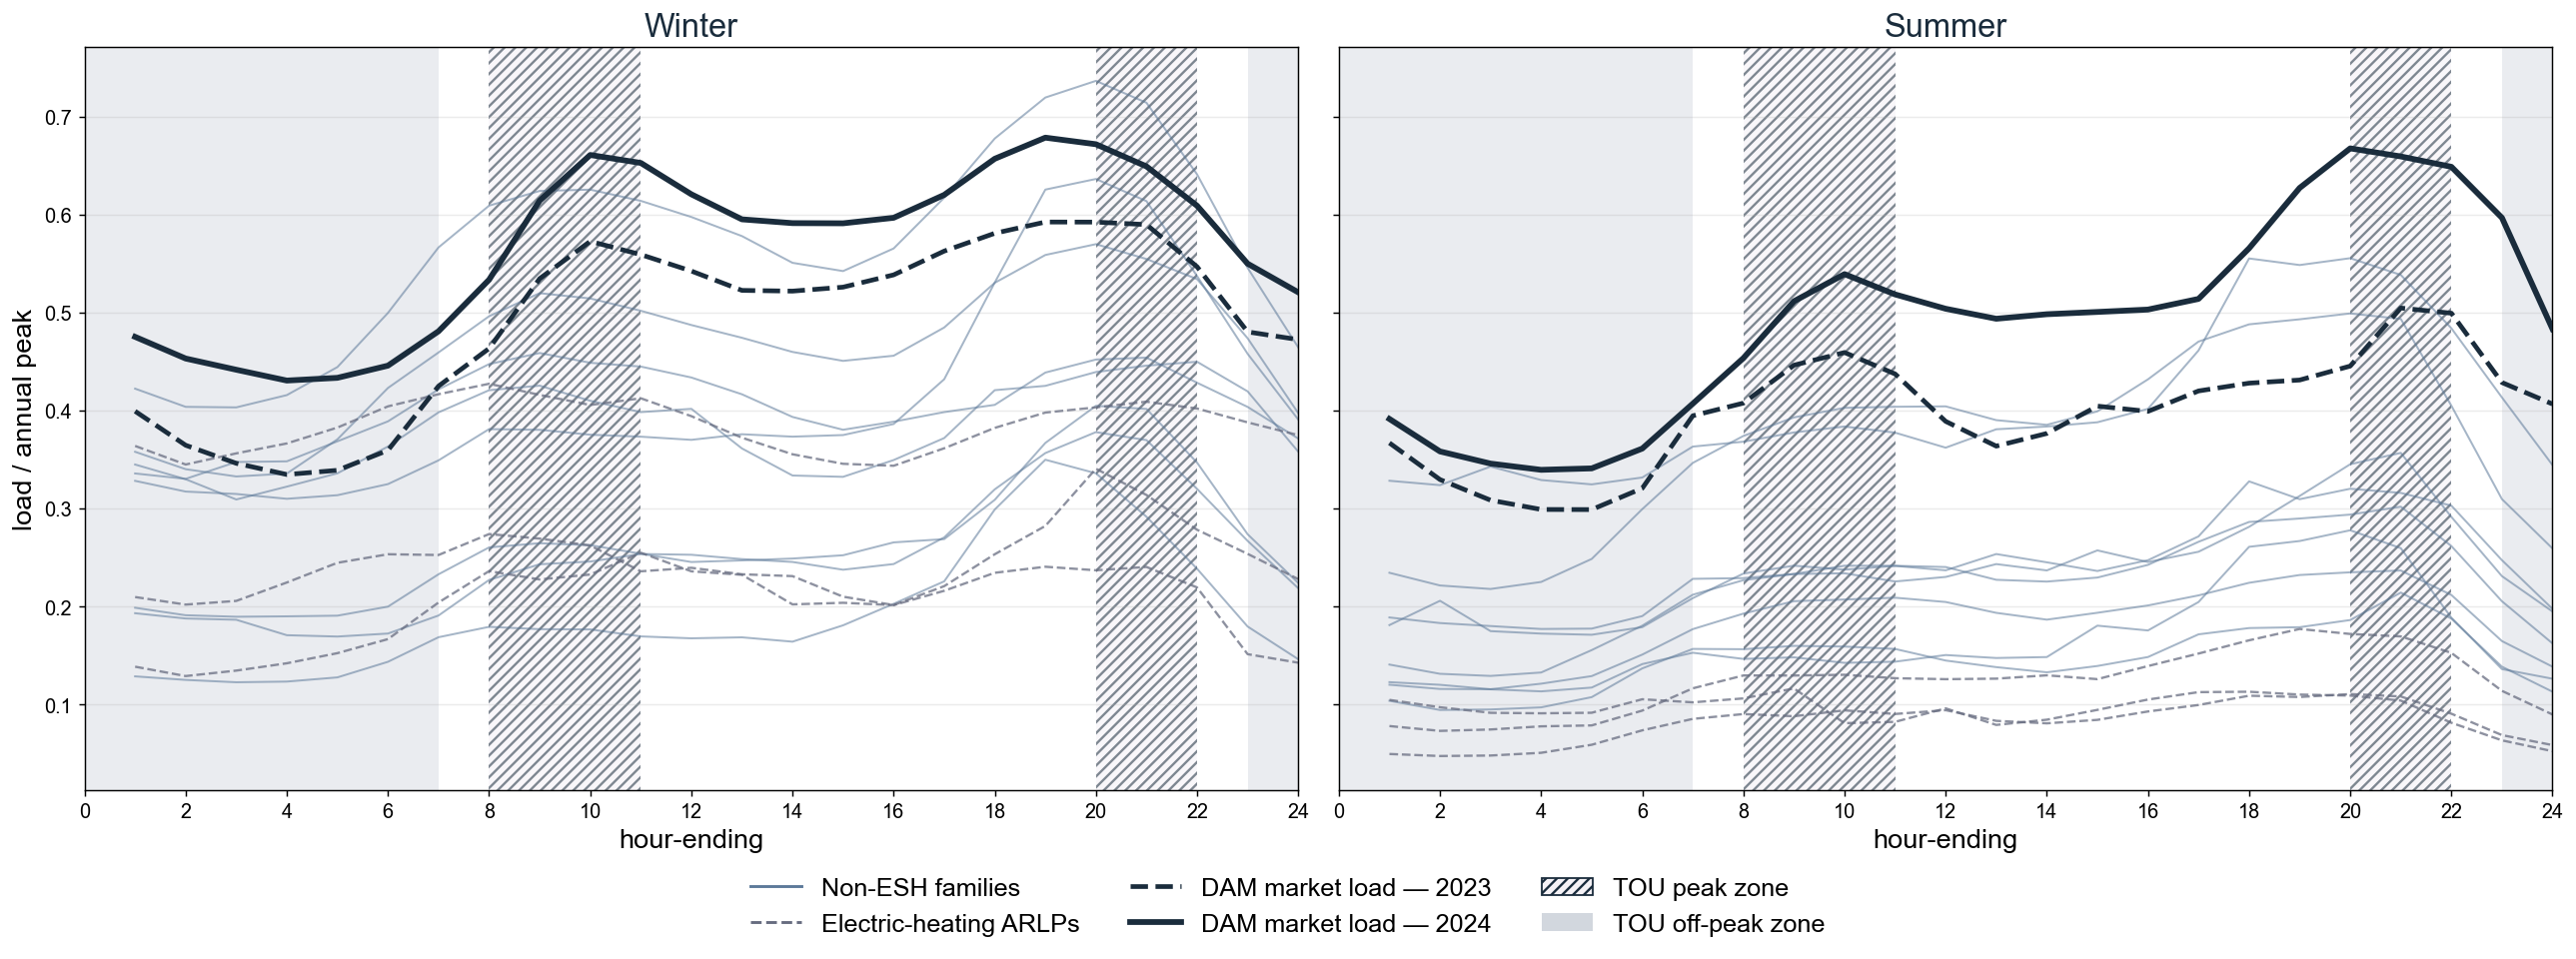

In [19]:
import make_seasonal_overlay as _m8; importlib.reload(_m8); _m8.main()
Image(str(OUT/"non_esh"/"notebook_figures"/"repday_overlay_2season_house.png"))

**Class fingerprints** (not in the article) — the 5 classes across 8 shape metrics computed inline from the full 8760-h profiles, HH-weighted per class.

,load_factor,base_load_share,peak_width_80pct,modal_peak_hour,ramp_p95_norm,cv_daily_energy,energy_share_winter,tou_peak_share
A,0.281,0.199,3.430,20.393,0.153,0.104,0.594,0.236
B,0.181,0.115,2.677,19.000,0.157,0.157,0.615,0.226
C,0.404,0.197,8.560,19.930,0.099,0.394,0.719,0.237
ESH-1,0.195,0.078,3.121,20.000,0.140,0.489,0.736,0.233
ESH-2,0.192,0.055,4.825,9.939,0.098,0.749,0.787,0.231


wrote outputs\ARLP_Clustering\notebook_figures\class_fingerprints_5class_preferred_house.png  (289 KB)


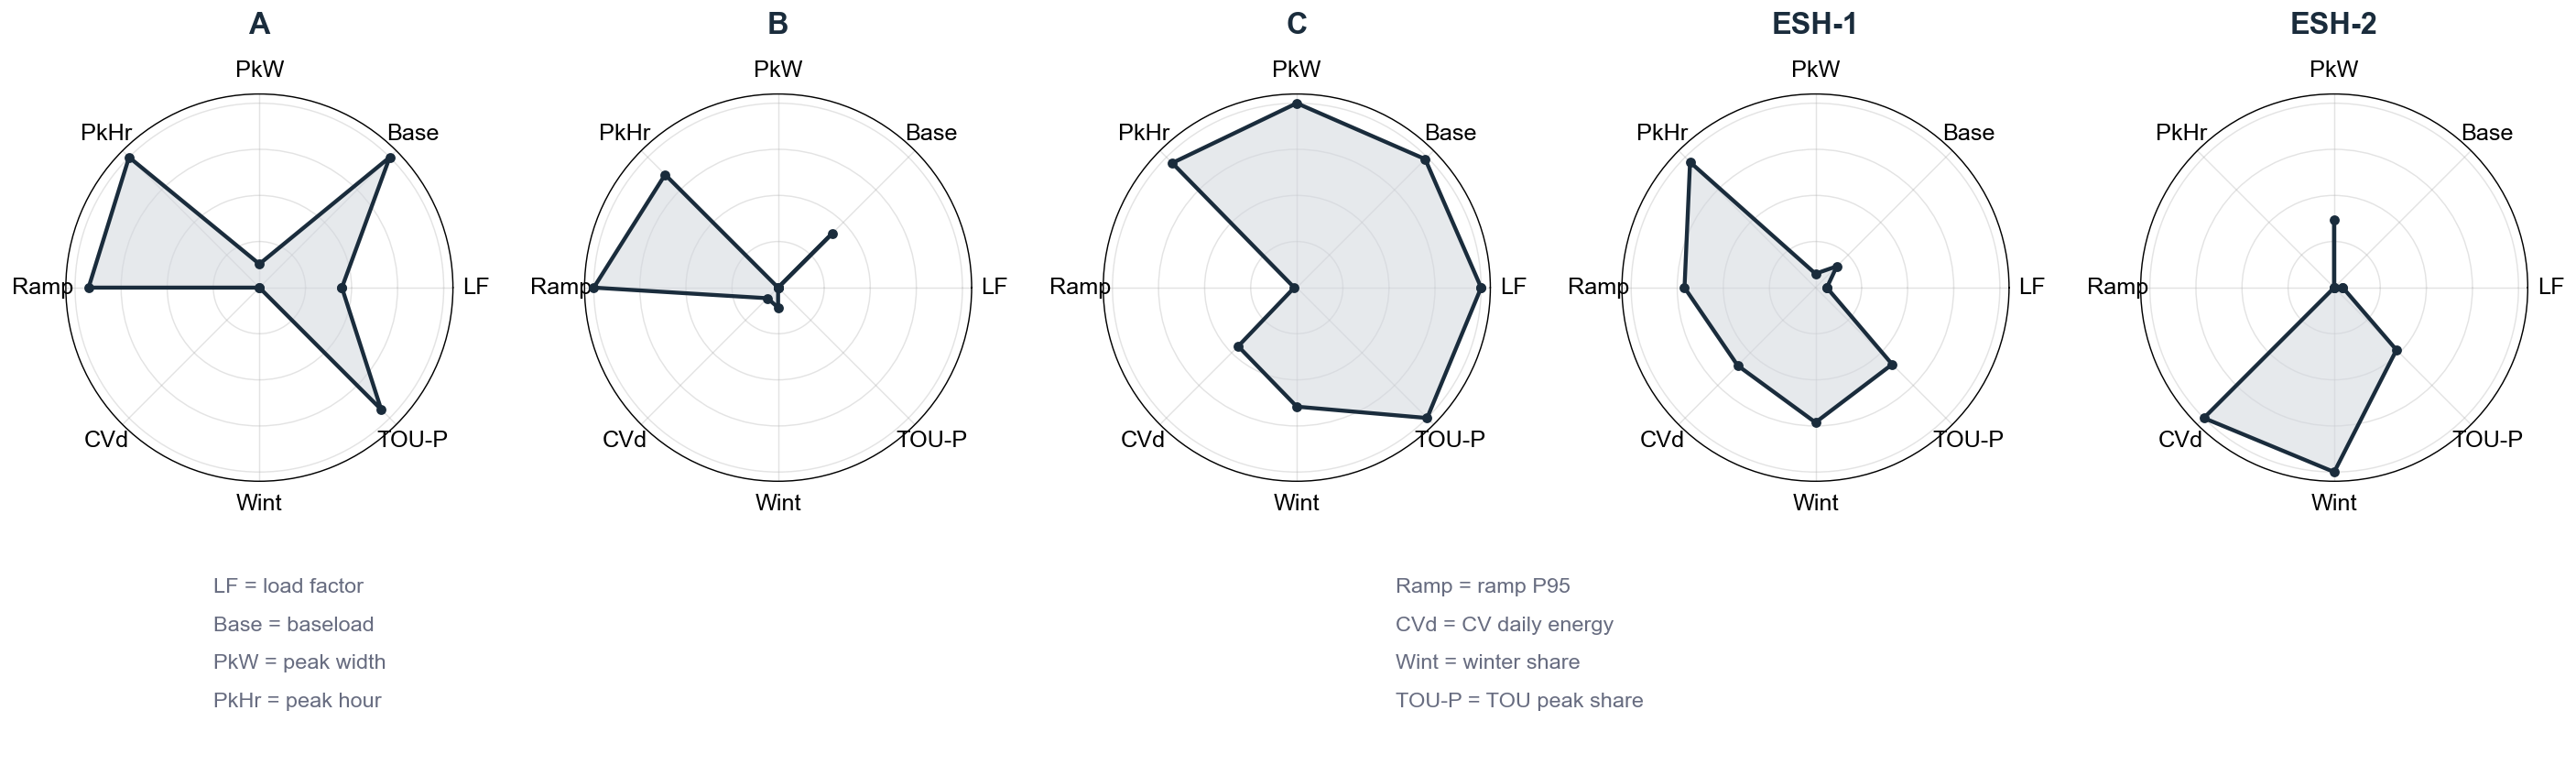

In [20]:
FP_METRICS = ["load_factor","base_load_share","peak_width_80pct","modal_peak_hour",
              "ramp_p95_norm","cv_daily_energy","energy_share_winter","tou_peak_share"]
_mm = TS.dt.month.to_numpy(); _hh = TS.dt.hour.to_numpy()
_win = np.isin(_mm, list(WINTER_MONTHS)); _pk = np.isin(_hh, [9,10,11,21,22])


def _fp(p):
    p = np.asarray(p, float); peak = p.max()
    daily = p.reshape(365, 24); dmax = daily.max(1); de = daily.sum(1)
    return {"load_factor": p.mean()/peak, "base_load_share": np.percentile(p,10)/peak,
            "peak_width_80pct": float((daily >= 0.8*dmax[:,None]).sum(1).mean()),
            "modal_peak_hour": int(np.bincount(daily.argmax(1)).argmax())+1,
            "ramp_p95_norm": np.percentile(np.abs(np.diff(p)),95)/peak,
            "cv_daily_energy": de.std()/de.mean(),
            "energy_share_winter": p[_win].sum()/p.sum(), "tou_peak_share": p[_pk].sum()/p.sum()}


_fp_all = pd.DataFrame({n: _fp(load_df[n].to_numpy()) for n in ARLP_NAMES_ALL}).T.loc[:, FP_METRICS]
_ORDER = ["A","B","C","ESH-1","ESH-2"]
_fp_rows = {}
for cid, cname in _NAME6.items():
    members = [n for n in ARLP_NAMES_ALL if CLUSTER_OF[n] == cid]
    w = np.array([HH[n] for n in members], float)
    _fp_rows[cname] = (_fp_all.loc[members].to_numpy(float) * w[:,None]).sum(0) / w.sum()
FP_CLASS = pd.DataFrame(_fp_rows, index=FP_METRICS).T.loc[_ORDER]
(OUT/"notebook_figures").mkdir(parents=True, exist_ok=True)
FP_CLASS.to_csv(OUT/"notebook_figures"/"class_fingerprints_5class_preferred_features.csv")
display(FP_CLASS.round(3))
import make_class_fingerprints as _m9; importlib.reload(_m9); _m9.main()
Image(str(OUT/"notebook_figures"/"class_fingerprints_5class_preferred_house.png"))

## §4.4 · Proposed 3-zone tariff

**Table 4** — per-class, per-season α coefficients (computed in §3.5). Non-ESH rates = α × ₴3.60/kWh;
ESH winter rows show the rate band across the ₴2.20 / ₴3.60 per kWh base regimes (excluding VAT, 2 decimals); ESH
summer rows show α × ₴3.60/kWh, because the discount applies in October–April only. The table is
the statutory menu; the bills use the effective ESH winter base of Table 6.

In [21]:
_LAB = {"Class A":"A","Class B":"B","Class C":"C","Class E1 (ESH)":"ESH-1","Class E2 (ESH)":"ESH-2"}
_band = lambda a, lo=_ESH_LO, hi=_ESH_HI: f"{round(a*lo,2):.2f}-{round(a*hi,2):.2f}"   # ₴/kWh, 2 decimals
_rows = []
for _, r in final_df.iterrows():
    esh = "ESH" in r.label
    esh_w = esh and r.season == "winter"   # the ESH discount applies in October-April only
    _base7 = _ESH_HI if esh else FLAT_RATE   # summer ESH rows: alpha x ₴3.60
    off, sho, pk = ALPHA_FULL[(r.label, r.season)]   # full precision, rounded once for display
    _rows.append({"Class": _LAB[r.label], "Season": r.season[0], "a_off": round(off,3), "a_sho": round(sho,3), "a_peak": round(pk,3),
                  "ratio": round(pk/off,2),
                  "off_rate": _band(off) if esh_w else round(off*_base7,2),
                  "sho_rate": _band(sho) if esh_w else round(sho*_base7,2),
                  "peak_rate": _band(pk) if esh_w else round(pk*_base7,2)})
for tag, base in [("E3", FLAT_RATE), ("E3, discounted", _ESH_LO)]:   # display labels
    _rows.append({"Class": tag, "Season": "a", "a_off": 0.40, "a_sho": 1.00, "a_peak": 1.50, "ratio": 3.75,
                  "off_rate": round(0.40*base,2), "sho_rate": round(1.00*base,2), "peak_rate": round(1.50*base,2)})
TABLE7 = pd.DataFrame(_rows); TABLE7

,Class,Season,a_off,a_sho,a_peak,ratio,off_rate,sho_rate,peak_rate
0,A,w,0.596,1.006,1.419,2.38,2.15,3.62,5.11
1,A,s,0.499,1.039,1.490,2.99,1.8,3.74,5.36
2,B,w,0.701,0.994,1.322,1.88,2.52,3.58,4.76
3,B,s,0.651,1.022,1.345,2.07,2.34,3.68,4.84
4,C,w,0.906,1.011,1.088,1.20,3.26,3.64,3.92
5,C,s,0.945,0.996,1.063,1.12,3.4,3.59,3.83
6,ESH-1,w,0.846,1.039,1.128,1.33,1.86-3.05,2.29-3.74,2.48-4.06
7,ESH-1,s,0.927,0.993,1.085,1.17,3.34,3.58,3.91
8,ESH-2,w,0.950,1.009,1.044,1.10,2.09-3.42,2.22-3.63,2.30-3.76
9,ESH-2,s,0.979,1.005,1.017,1.04,3.52,3.62,3.66


## §4.5 · Demand-response implications (recomputed from raw)

The whole PEED demand-response layer is re-derived here from the raw DAM prices, the PEED matrix,
the proposed tariff `final_df`, and the per-class loads `C_season_all` — **no stored
intermediate is loaded**.

> **ESH-split consistency.** Every quantity below uses the article's taxonomy
> **ESH-1={01}, ESH-2={02,03}** (as §4.3). Class-uniform quantities (the current-3z DAM saving) and
> all non-ESH physical results are split-invariant.
>
> **Money in ₴.** Bills and revenue are in ₴ million, excluding VAT. DAM-based savings are valued at
> the retail-equivalent price `DAM_gross_price_uah_mwh` of `inputs/hourly_dam_prices_uah.csv` (DAM price +
> the transmission and distribution tariffs of the delivery day). Under R the network parts practically
> offset in these computations (daily energy preserved, tariffs constant within each delivery day; residual
> at most ₴0.47 M from hour-ending 24), so the savings are close to a valuation at the DAM
> price alone.

In [22]:
# --- per-class loads L0, zones, proposed rates built inline from final_df ---
CLASSES13 = sorted(clusters_all)
PRETTY_LAB = {c: CLUSTER_LABELS_ALL19[c] for c in CLASSES13}
PLOT_LAB_029 = {0:"A",1:"B",2:"C",3:"ESH-1",4:"ESH-2"}
L0 = {c: {sn: np.asarray(C_season_all[c][sn], float) for sn in seasons} for c in CLASSES13}
L0_total = {sn: sum(L0[c][sn] for c in CLASSES13) for sn in seasons}
PERIOD_OF_HOUR = {h: ("peak" if h in TOU_PERIODS_0BASED["peak"]
                      else "off-peak" if h in TOU_PERIODS_0BASED["off"] else "shoulder") for h in range(24)}
PEAK_HOURS_13 = [h for h in range(24) if PERIOD_OF_HOUR[h] == "peak"]
NIGHT_MULT = 0.5
CUR3Z_COEFF = {"off-peak":0.40, "shoulder":1.00, "peak":1.50}
_PCZ = {"peak":"peak","shoulder":"shoulder","off":"off-peak"}

_PER = {"peak":"alpha_peak","shoulder":"alpha_shoulder","off":"alpha_off"}
_pr = []
for _, r in final_df.iterrows():
    c, sn = int(r.cluster), r.season
    tags = [("lo",_ESH_LO),("hi",_ESH_HI)] if c in ESH_CLUSTERS else [("flat",FLAT_RATE)]
    for per, acol in _PER.items():
        for tag, base in tags:
            _pr.append({"cluster":c,"season":sn,"period":per,"base_tag":tag,"rate_UAH_per_kWh": round(float(r[acol])*base,4)})
_PROPOSED = pd.DataFrame(_pr)


def _base_for(cls, sn, esh_baseline="deployed"):
    if cls in ESH_CLUSTERS and esh_baseline == "deployed":
        return (_ESH_LO,"lo") if sn == "winter" else (_ESH_HI,"hi")
    if cls in ESH_CLUSTERS and esh_baseline == "flat":
        return _ESH_HI,"hi"
    return FLAT_RATE,"flat"


def _prop_rate_zone(c, sn):
    _, bt = _base_for(c, sn); sub = _PROPOSED[(_PROPOSED.cluster==c)&(_PROPOSED.season==sn)&(_PROPOSED.base_tag==bt)]
    return {_PCZ[row.period]: float(row.rate_UAH_per_kWh) for _, row in sub.iterrows()}


def make_du_zones(cls, sn, baseline_kind="flat"):
    base, bt = _base_for(cls, sn); sub = _PROPOSED[(_PROPOSED.cluster==cls)&(_PROPOSED.season==sn)&(_PROPOSED.base_tag==bt)]
    by = {row.period: float(row.rate_UAH_per_kWh) for _, row in sub.iterrows()}
    du = {}
    for cp, z in _PCZ.items():
        ref = NIGHT_MULT*base if (baseline_kind=="2z" and z=="off-peak") else base
        du[z] = (by[cp]-ref)/ref
    return du


DU_FLAT = {c: {sn: make_du_zones(c, sn, "flat") for sn in seasons} for c in CLASSES13}
DU_2Z   = {c: {sn: make_du_zones(c, sn, "2z")   for sn in seasons} for c in CLASSES13}


def apply_peed_zonal(L0v, du, E):
    L1 = np.array([L0v[h]*(1.0 + sum(E.loc[PERIOD_OF_HOUR[h], zh]*du[zh] for zh in ZONES_3)) for h in range(24)])
    return np.maximum(L1, 0.0)


def rescale_energy(L1v, L0v):
    e0, e1 = float(L0v.sum()), float(L1v.sum()); return L1v.copy() if e1<=0 else L1v*(e0/e1)


L1c_FLAT = {c: {sn: rescale_energy(apply_peed_zonal(L0[c][sn], DU_FLAT[c][sn], PEED_3), L0[c][sn]) for sn in seasons} for c in CLASSES13}
L1c_2Z   = {c: {sn: rescale_energy(apply_peed_zonal(L0[c][sn], DU_2Z[c][sn],   PEED_3), L0[c][sn]) for sn in seasons} for c in CLASSES13}
dL_FLAT_total = {sn: sum(L1c_FLAT[c][sn]-L0[c][sn] for c in CLASSES13) for sn in seasons}
dL_2Z_total   = {sn: sum(L1c_2Z[c][sn]  -L0[c][sn] for c in CLASSES13) for sn in seasons}
PENETRATIONS = [0.10,0.25,0.50,0.75,1.00]
Lp_FLAT = {p:{c:{sn:(1-p)*L0[c][sn]+p*L1c_FLAT[c][sn] for sn in seasons} for c in CLASSES13} for p in PENETRATIONS}
Lp_2Z   = {p:{c:{sn:(1-p)*L0[c][sn]+p*L1c_2Z[c][sn]   for sn in seasons} for c in CLASSES13} for p in PENETRATIONS}
Lp_FLAT_total = {p:{sn:sum(Lp_FLAT[p][c][sn] for c in CLASSES13) for sn in seasons} for p in PENETRATIONS}
Lp_2Z_total   = {p:{sn:sum(Lp_2Z[p][c][sn]   for c in CLASSES13) for sn in seasons} for p in PENETRATIONS}

decomp_df = pd.DataFrame([{"cluster":c,"label":PRETTY_LAB[c],"season":sn,
    "du_peak":round(DU_FLAT[c][sn]["peak"],4),"du_shoulder":round(DU_FLAT[c][sn]["shoulder"],4),
    "du_offpeak_flat3z":round(DU_FLAT[c][sn]["off-peak"],4),"du_offpeak_2z3z":round(DU_2Z[c][sn]["off-peak"],4),
    "peakzone_mean_red_flat3z_pct":round(100*(1-float(L1c_FLAT[c][sn][PEAK_HOURS_13].mean())/float(L0[c][sn][PEAK_HOURS_13].mean())),2),
    "peakzone_mean_red_2z3z_pct":round(100*(1-float(L1c_2Z[c][sn][PEAK_HOURS_13].mean())/float(L0[c][sn][PEAK_HOURS_13].mean())),2)}
    for c in CLASSES13 for sn in seasons])
print("PEED core built: L0, DU (two baselines), PEED-applied energy-conserving loads, sweep, decomposition.")

PEED core built: L0, DU (two baselines), PEED-applied energy-conserving loads, sweep, decomposition.


In [23]:
# --- DAM prices (raw) + penetration S-curve + system DAM savings ---
price_df = pd.read_csv(INP/"hourly_dam_prices_uah.csv", parse_dates=["timestamp"])   # ₴/MWh excl. VAT, model calendar
_d = price_df.copy(); _d["season"]=np.where(_d["timestamp"].dt.month.isin(set(WINTER_MONTHS)),"winter","summer"); _d["hour"]=_d["timestamp"].dt.hour
dam_by_h = _d.groupby(["season","hour"])["DAM_gross_price_uah_mwh"].mean().unstack(0).reindex(range(24))/1000   # ₴/kWh at the gross price E + O + P
DAYS = {"winter":212, "summer":153}
_annual_cost = lambda Lt: sum((Lt[sn]*1000*dam_by_h[sn].to_numpy()).sum()*DAYS[sn] for sn in seasons)

SMART_METER_DEVICES_2024 = 3.29e6
S0 = SMART_METER_DEVICES_2024 / (float(sum(HH.values()))*1000.0)
_dn = S0/0.23
ANCHORS = pd.DataFrame({"year":[2022,2023,2024,2030,2035],
                        "smart_meter_share":[round(0.155*_dn,4),round(0.205*_dn,4),round(S0,4),0.75,0.95]})
_logi = lambda t,S,g,t0: S/(1+np.exp(-g*(t-t0)))
popt,_ = curve_fit(_logi, ANCHORS.year, ANCHORS.smart_meter_share, p0=[0.95,0.5,2030], maxfev=5000)
YEARS = np.arange(2025,2041)
SMART = np.clip(_logi(YEARS,*popt),0,1)
BETA  = np.clip((YEARS-2024)/(2040-2024),0,1)
P_2Z, P_FLAT = BETA*S0, np.maximum(SMART-S0,0.0); P_TOTAL = P_2Z+P_FLAT
pen_df = pd.DataFrame({"year":YEARS,"smart_meter_share_S":SMART,"S0":S0,"beta":BETA,
                       "p_2z_to_3z":P_2Z,"p_flat_to_3z":P_FLAT,"p_total":P_TOTAL})
check("penetration S0~0.19", abs(S0-0.1906)<2e-3)
check("penetration p_total 2030~0.625", abs(float(pen_df.loc[pen_df.year==2030,"p_total"].iloc[0])-0.625)<0.02)
check("penetration p_total 2040~0.991", abs(float(pen_df.loc[pen_df.year==2040,"p_total"].iloc[0])-0.991)<0.01)

_cost0 = _annual_cost(L0_total)
_duf_cur = {z: CUR3Z_COEFF[z]-1.0 for z in ZONES_3}; _du2_cur = dict(_duf_cur); _du2_cur["off-peak"]=(CUR3Z_COEFF["off-peak"]-NIGHT_MULT)/NIGHT_MULT
_dLf_cur = {sn: sum(rescale_energy(apply_peed_zonal(L0[c][sn],_duf_cur,PEED_3),L0[c][sn])-L0[c][sn] for c in CLASSES13) for sn in seasons}
_dLz_cur = {sn: sum(rescale_energy(apply_peed_zonal(L0[c][sn],_du2_cur,PEED_3),L0[c][sn])-L0[c][sn] for c in CLASSES13) for sn in seasons}
def _comb_saving(dLf,dLz,pf,p2): return _cost0 - _annual_cost({sn:L0_total[sn]+pf*dLf[sn]+p2*dLz[sn] for sn in seasons})
sav_prop = [_comb_saving(dL_FLAT_total,dL_2Z_total,(1-S0)*p,S0*p)/1e6 for p in PENETRATIONS]
sav_cur  = [_comb_saving(_dLf_cur,_dLz_cur,(1-S0)*p,S0*p)/1e6 for p in PENETRATIONS]
display(pd.DataFrame({"p_t":PENETRATIONS,"proposed_MUAH":np.round(sav_prop,1),"current3z_MUAH":np.round(sav_cur,1)}))   # shown before the anchors
# ₴ anchors: tolerances scaled from the reference-run anchors by the ratio of the savings (42.258 / 42.296), rounded down
check("DAM proposed combined (consistent split) ~ 1420/3551/7101/10652/14202 M UAH", np.allclose(sav_prop,[1420.2,3550.6,7101.2,10651.8,14202.4],atol=25.3))
check("DAM current-3z combined ~ 2571/6428/12857/19285/25713 M UAH", np.allclose(sav_cur,[2571.3,6428.3,12856.6,19284.9,25713.2],atol=50.7))
pen_df.round(3)

  [OK] penetration S0~0.19
  [OK] penetration p_total 2030~0.625
  [OK] penetration p_total 2040~0.991


,p_t,proposed_MUAH,current3z_MUAH
0,0.10,1420.2,2571.3
1,0.25,3550.6,6428.3
2,0.50,7101.2,12856.6
3,0.75,10651.8,19284.9
4,1.00,14202.4,25713.2


  [OK] DAM proposed combined (consistent split) ~ 1420/3551/7101/10652/14202 M UAH
  [OK] DAM current-3z combined ~ 2571/6428/12857/19285/25713 M UAH


,year,smart_meter_share_S,S0,beta,p_2z_to_3z,p_flat_to_3z,p_total
0,2025,0.290,0.191,0.062,0.012,0.100,0.111
1,2026,0.377,0.191,0.125,0.024,0.187,0.210
2,2027,0.473,0.191,0.188,0.036,0.282,0.318
3,2028,0.571,0.191,0.250,0.048,0.380,0.428
4,2029,0.663,0.191,0.312,0.060,0.472,0.532
5,2030,0.744,0.191,0.375,0.071,0.554,0.625
6,2031,0.812,0.191,0.438,0.083,0.621,0.704
7,2032,0.864,0.191,0.500,0.095,0.673,0.769
8,2033,0.904,0.191,0.562,0.107,0.713,0.820
9,2034,0.932,0.191,0.625,0.119,0.742,0.861


**Fig. 8.** Class-level relative price change by TOU zone and season (F → P3 vs E2 → P3). From the inline `decomp_df`.

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\price_signals_grid.png  (97 KB)


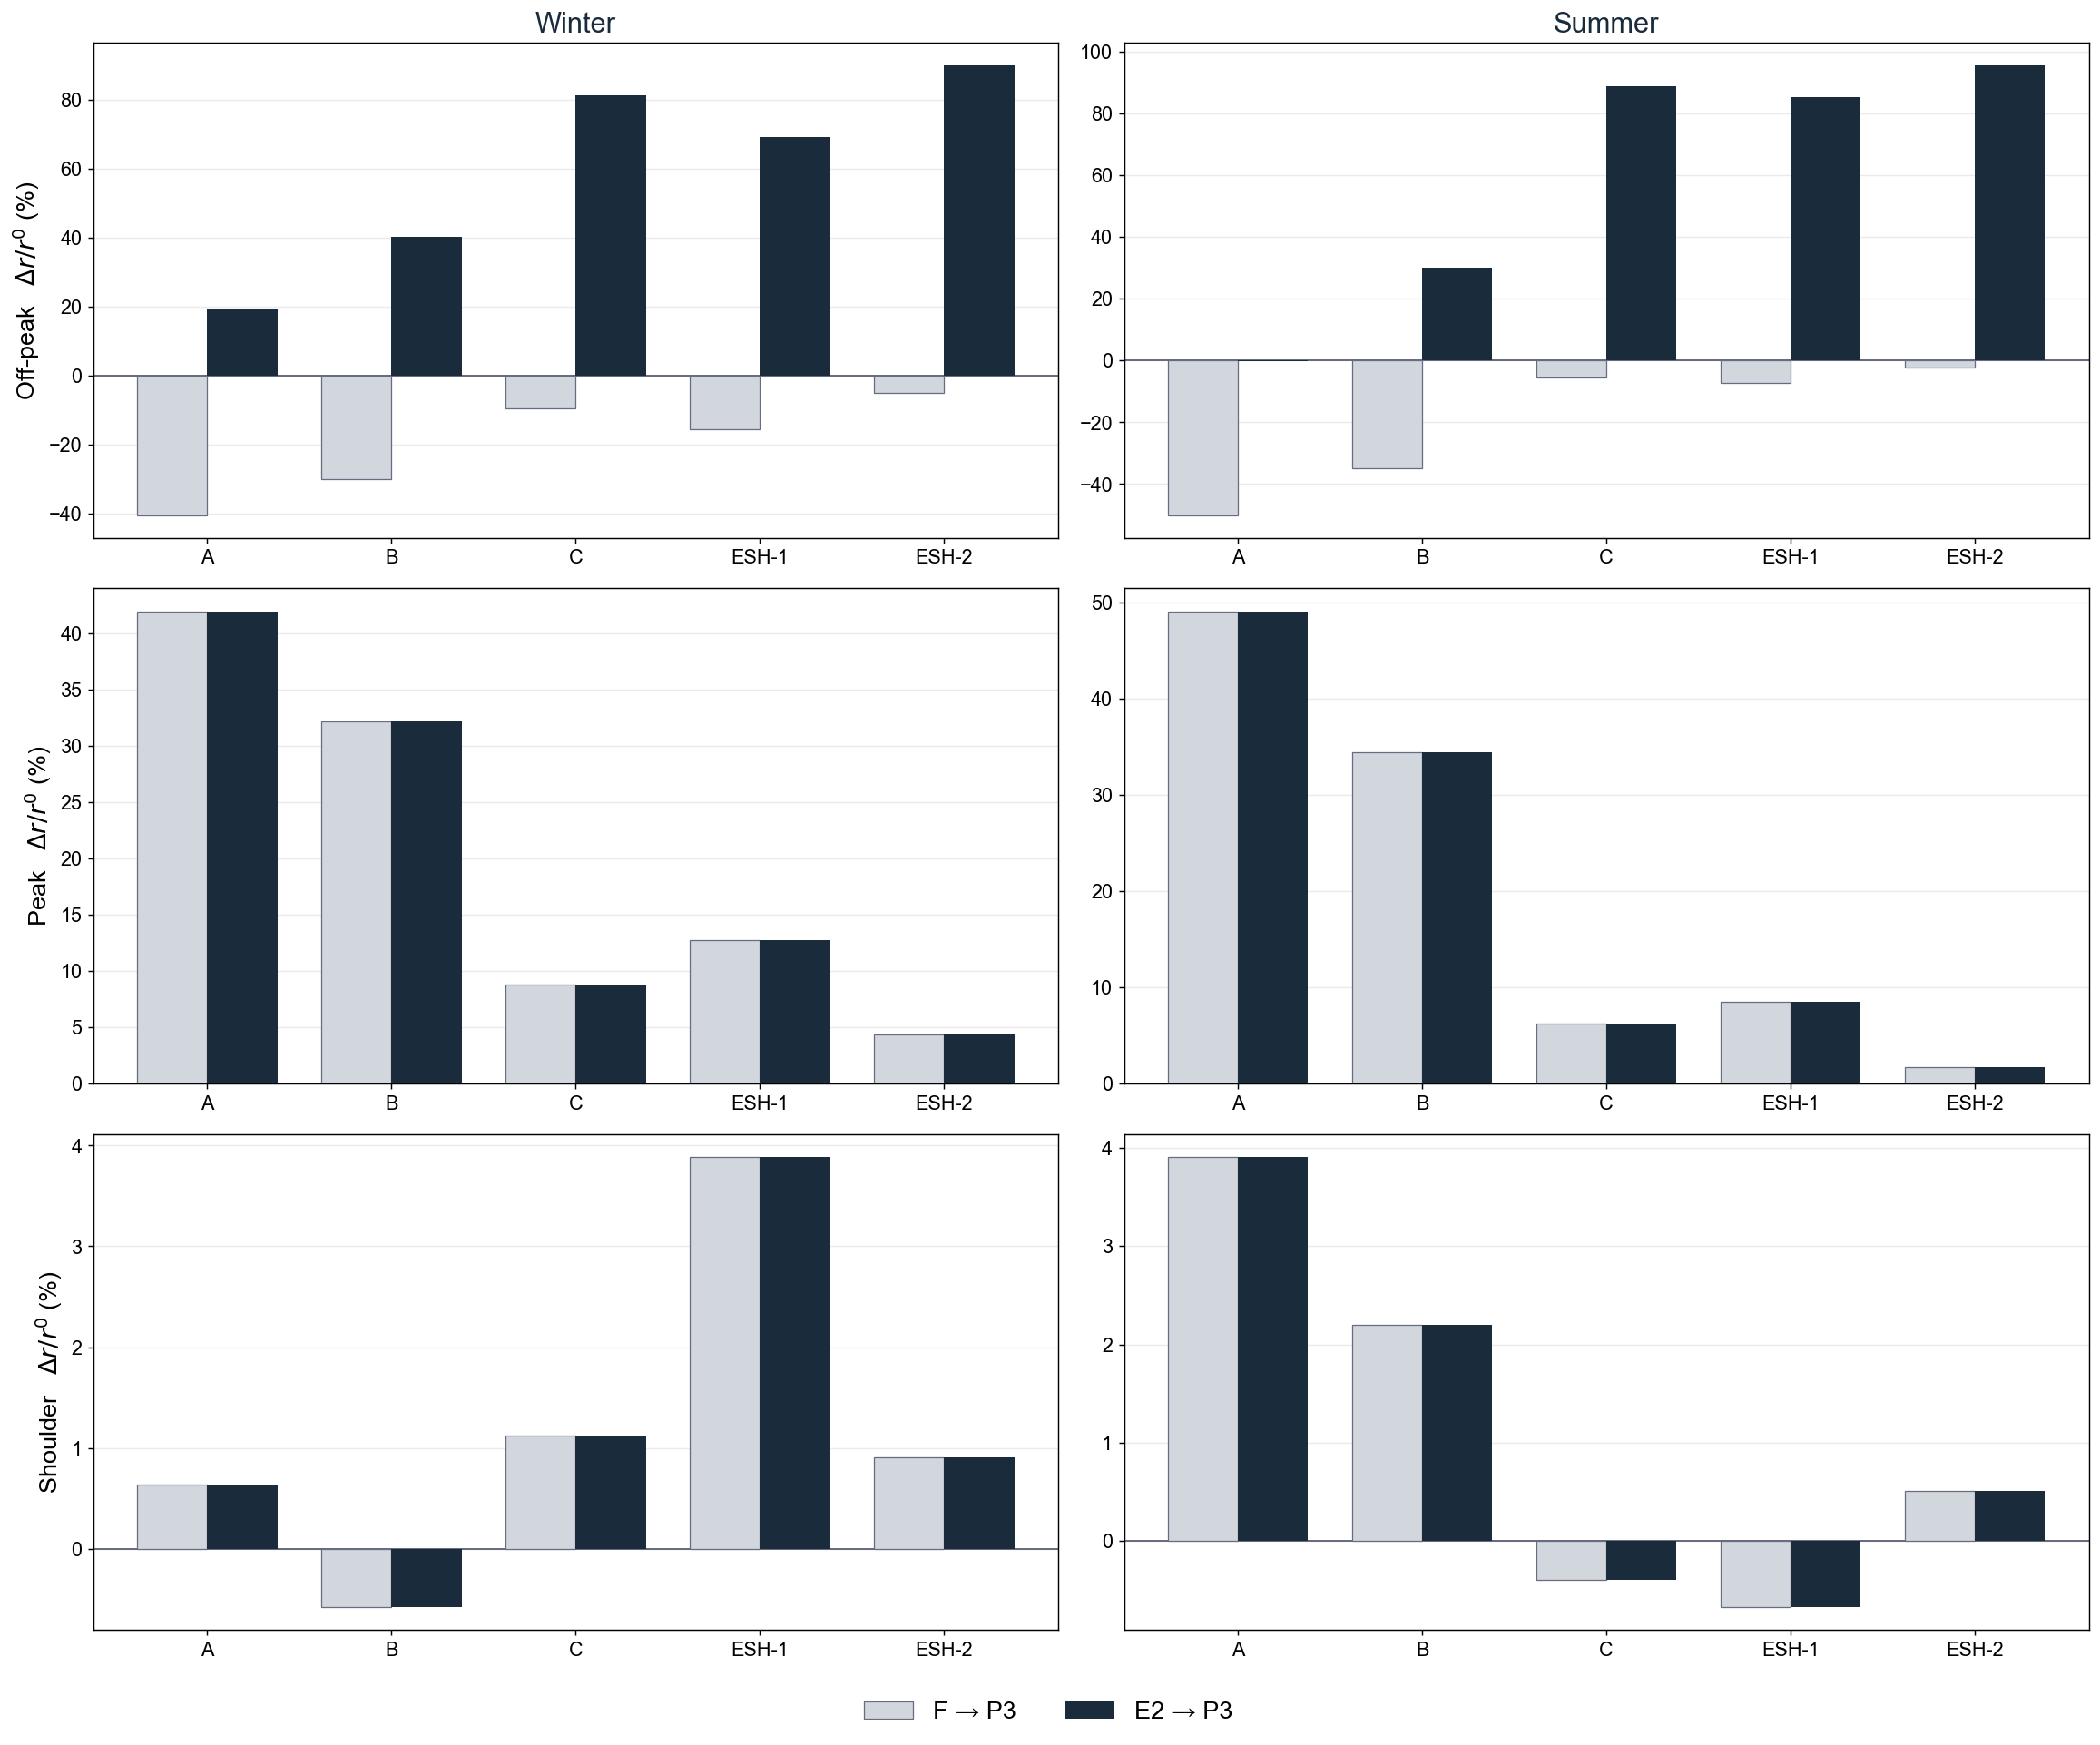

In [24]:
OUT13 = OUT/"notebook_only"/"layer13_peed_dr"; OUT13.mkdir(parents=True, exist_ok=True)
decomp_df.to_csv(OUT13/"two_stage_decomposition.csv", index=False)
import make_price_signals_grid as _m10; importlib.reload(_m10); _m10.main()
Image(str(OUT13/"price_signals_grid.png"))

**Whole-system aggregate load-shift scenarios** by channel and season (not in the article). From the inline system-sweep arrays.

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\loadshift_grid.png  (757 KB)


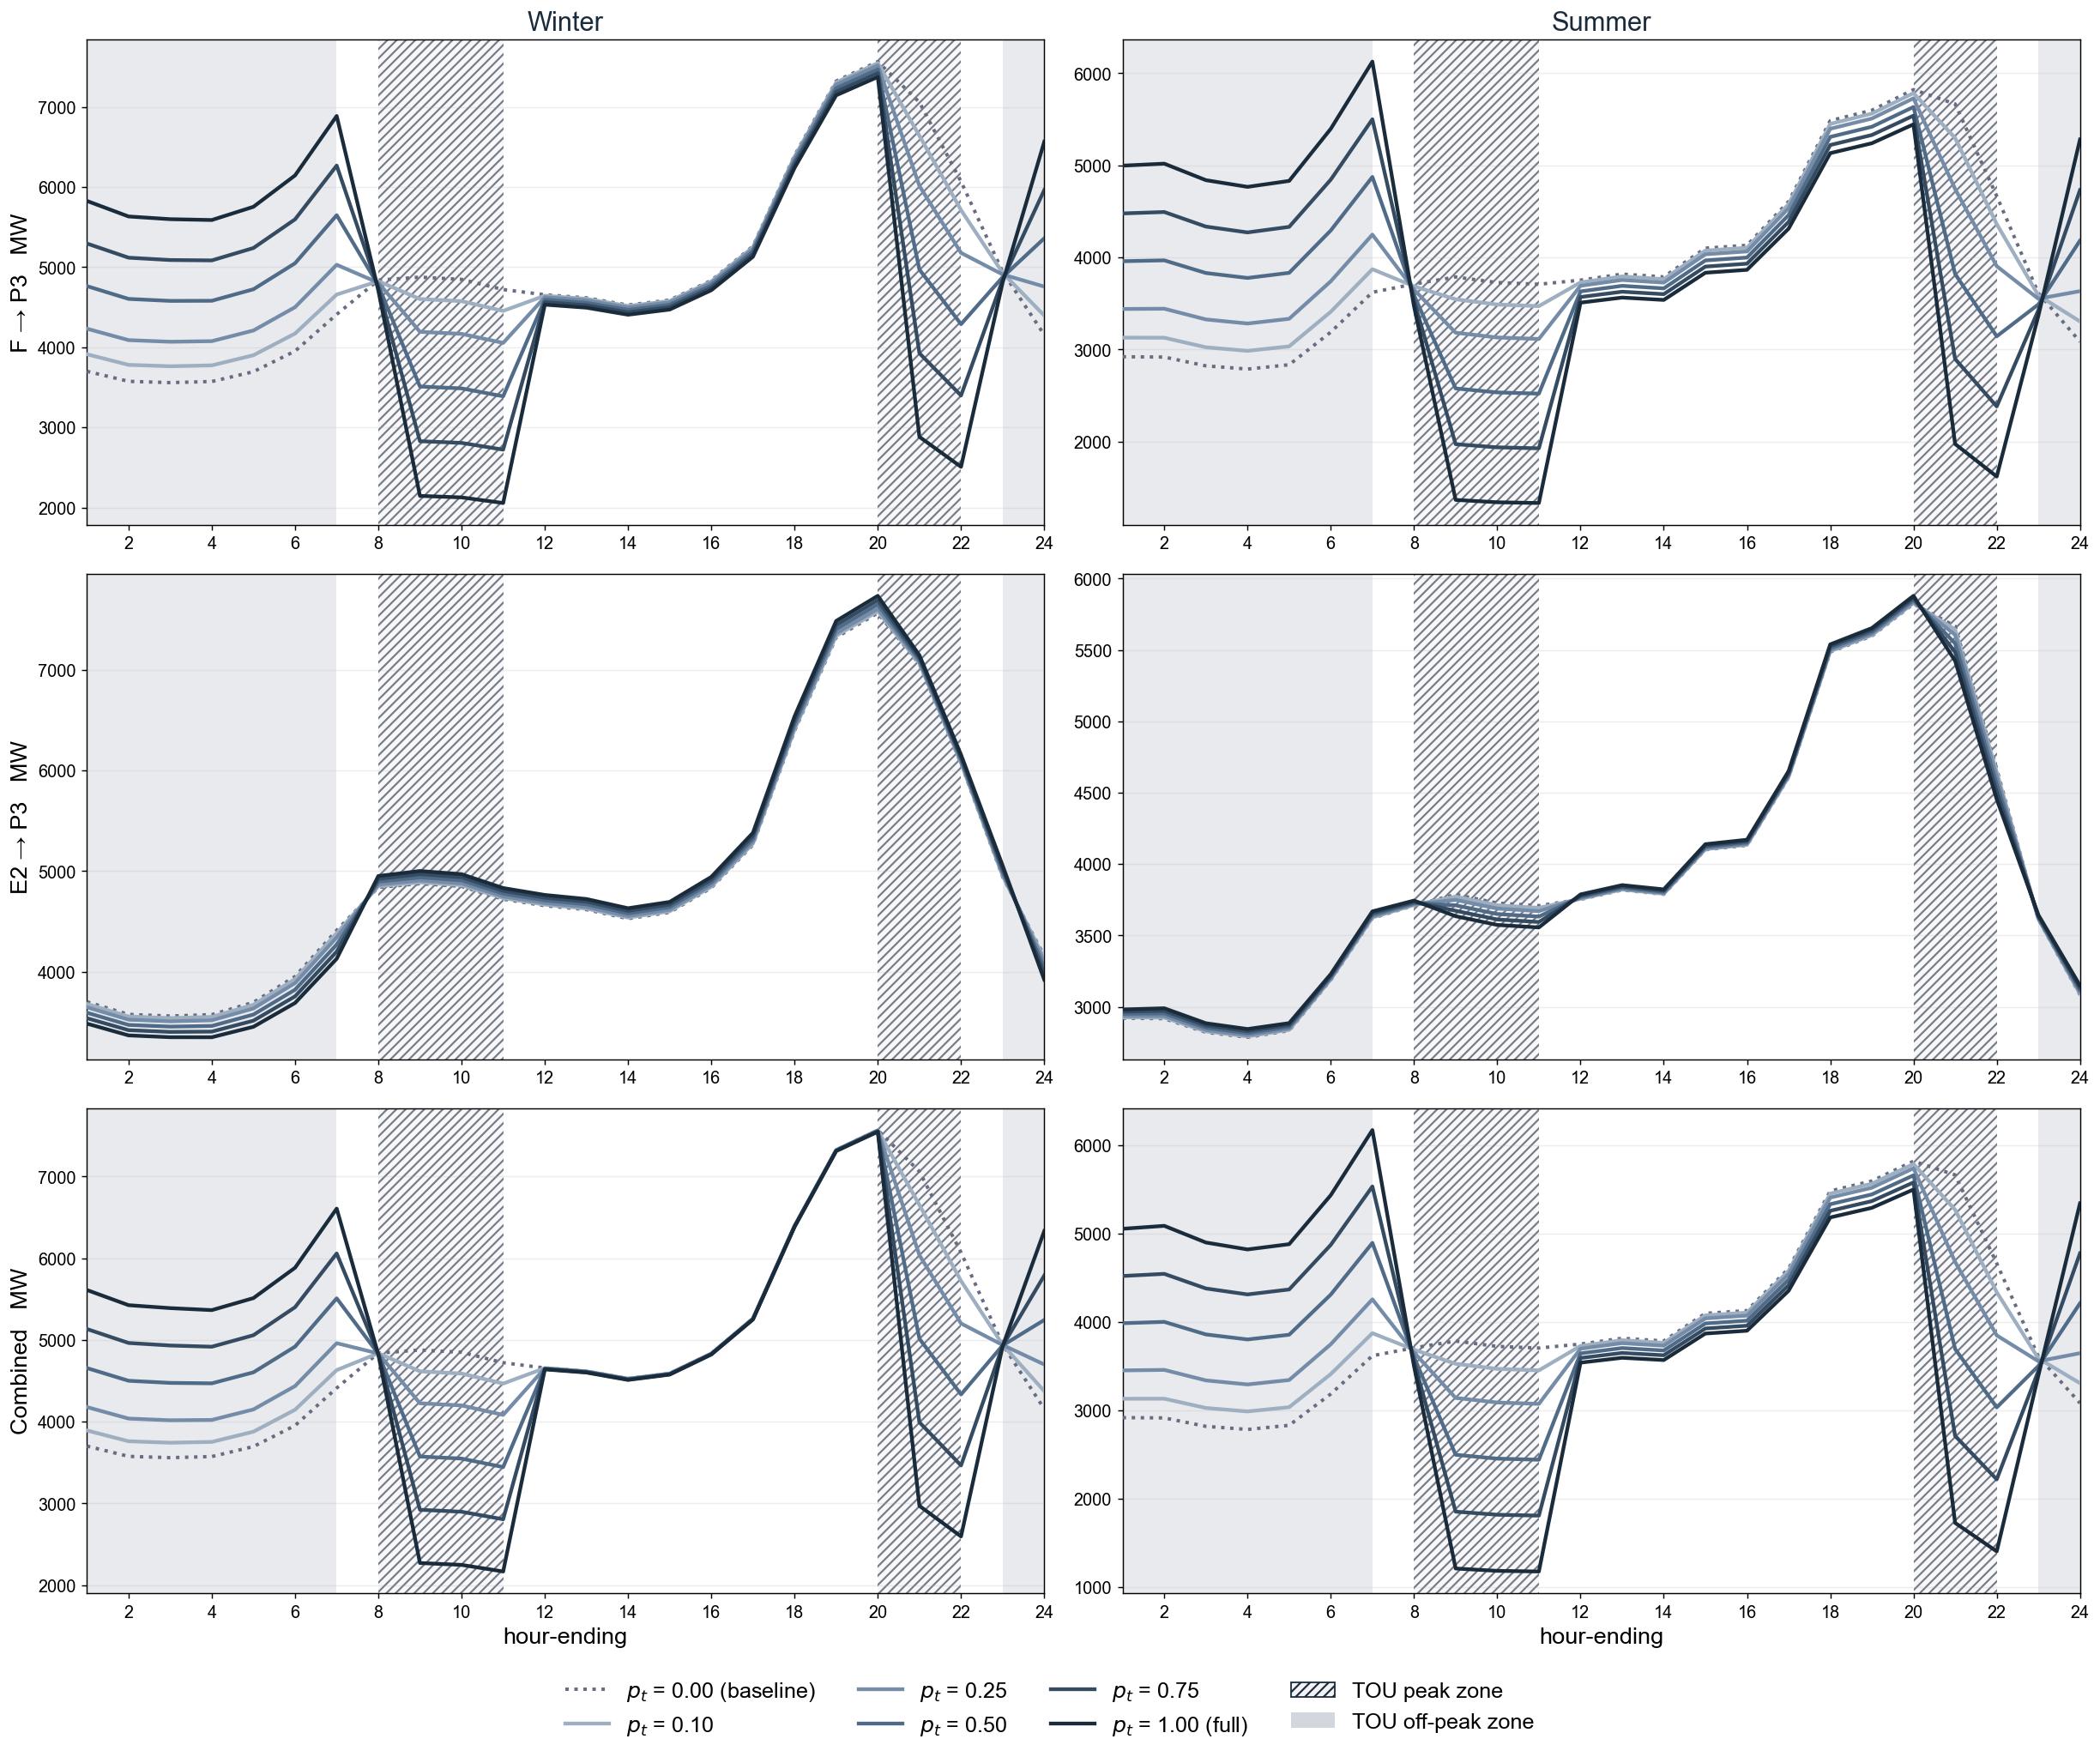

In [25]:
np.savez(OUT13/"_system_sweep_arrays.npz", S0=S0, PENETRATIONS=np.array(PENETRATIONS),
         period=np.array([PERIOD_OF_HOUR[h] for h in range(24)], dtype=object),
         **{f"L0_{sn}": np.asarray(L0_total[sn]) for sn in seasons},
         **{f"Lpflat_{sn}_{p}": np.asarray(Lp_FLAT_total[p][sn]) for sn in seasons for p in PENETRATIONS},
         **{f"Lp2z_{sn}_{p}": np.asarray(Lp_2Z_total[p][sn]) for sn in seasons for p in PENETRATIONS})
import make_loadshift_grid as _m11; importlib.reload(_m11); _m11.main()
Image(str(OUT13/"loadshift_grid.png"))

**Two-channel adoption trajectory and winter load morph** (not in the article). From the inline `pen_df` + system-sweep arrays.

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\adoption_ribbon_main.png  (211 KB)
UserWarning (make_adoption_ribbon.py:166): This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


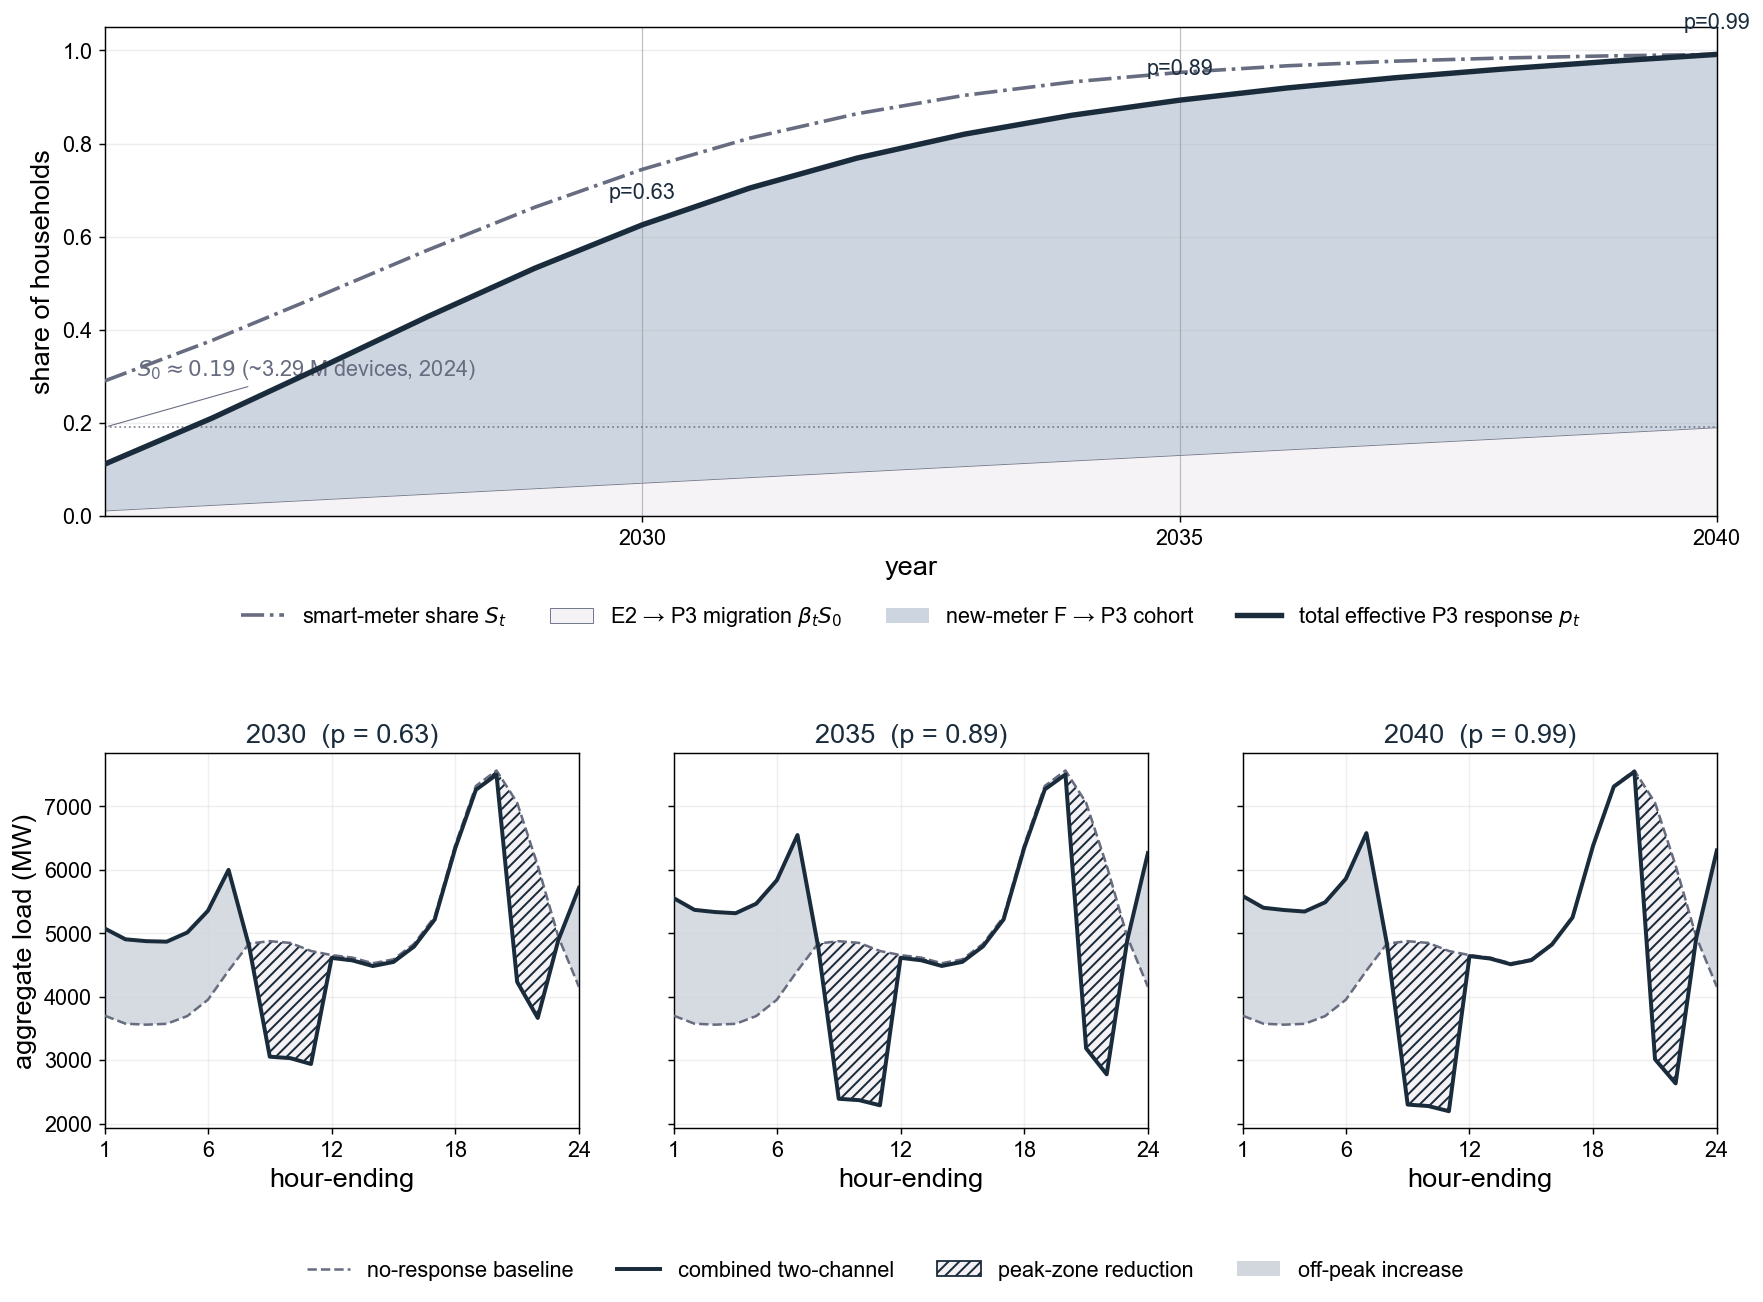

In [26]:
pen_df.to_csv(OUT13/"penetration_forecast.csv", index=False)
import warnings
import make_adoption_ribbon as _m12; importlib.reload(_m12)
with warnings.catch_warnings(record=True) as _w:          # warnings without absolute paths
    warnings.simplefilter("always")
    _m12.main()
for _x in _w:
    print(f"{_x.category.__name__} ({Path(_x.filename).name}:{_x.lineno}): {_x.message}")
Image(str(OUT13/"adoption_ribbon_main.png"))

**Table 6.** Average tariffs with passive, PEED-response and combined customer bill changes
(% of baseline). Positive = lower bill under the "to" tariff. Computed inline; the class energies
`CONS_GWH_029` are the ARLP-implied GWh of the class shares (`TABLE6`, Fig. 6) under the consistent ESH split. ESH
bills use the effective winter base: ESH-1 ₴2.20; ESH-2 per TOU zone from the months in which ARLP-03 exceeds 2,000 kWh.
The P3 bill neutrality against F is printed per class.

In [27]:
CONS_GWH_029 = {0:16703.0,1:12921.0,2:2938.0,3:4281.0,4:1326.0}
_rf = lambda c,sn,z: _base_for(c,sn)[0]
_re2 = lambda c,sn,z: _base_for(c,sn)[0]*(NIGHT_MULT if z=="off-peak" else 1.0)
_re3 = lambda c,sn,z: _base_for(c,sn)[0]*CUR3Z_COEFF[z]
_rp = lambda c,sn,z: _prop_rate_zone(c,sn)[z]


def _bill(c, rate_fn, Lp):
    num=den=0.0
    for sn in seasons:
        L = Lp(sn)
        for h in range(24):
            w = DAYS[sn]*L[h]; num += w*rate_fn(c,sn,PERIOD_OF_HOUR[h]); den += w
    return CONS_GWH_029[c]*(num/den)


# --- the fixed effective ESH winter base, used in the bills only ----------------------------------------------------
# Rule (inputs/neurc_household_tariffs_uah.csv; the wording in force before 1 February 2025 is kept for the whole
# heating season as a modelling assumption): in an October-April month a household pays ₴2.20/kWh on its whole monthly volume up to 2,000 kWh,
# otherwise ₴3.60/kWh on the whole volume. The rule is applied to each source ARLP's per-household consumption in each
# base-year month (timestamp month, as the seasons), never to a class average. w(c, z) is the share of class c's winter
# energy in TOU zone z that falls in months at ₴3.60 (weights: households x consumption); the effective base is
# 2.20 + 1.40 w. The bills use, per tariff, (1 - w) r_lo + w r_hi of its statutory rates, fixed for every scenario (the
# threshold is not reassessed after a response). The PEED price signals (make_du_zones, _du_e3z_p3z), Table 4 and
# _PROPOSED keep the statutory rates.
_IN02_A03 = pd.read_csv(INP/"neurc_household_tariffs_uah.csv")
_ESH_RULE = _IN02_A03[_IN02_A03.regime == "esh_discounted"]
ESH_THRESHOLD_KWH = float(_ESH_RULE.monthly_threshold_kwh.unique().item())
_flat_in02 = _IN02_A03[_IN02_A03.tariff == "flat"].set_index("regime").rate_uah_per_kwh_excl_vat
check("ESH rule of the statutory tariff file = model constants (2,000 kWh; October-April; ₴2.20 / ₴3.60)",
      ESH_THRESHOLD_KWH == 2000.0 and {int(m) for m in _ESH_RULE.months.unique().item().split(";")} == set(WINTER_MONTHS)
      and _flat_in02["esh_discounted"] == _ESH_LO and _flat_in02["regular"] == _ESH_HI)
_ZC = {"peak": "kWh_peak", "shoulder": "kWh_shoulder", "off-peak": "kWh_off_peak"}
_mon, _zon = TS.dt.month.to_numpy(), np.array([PERIOD_OF_HOUR[h] for h in TS.dt.hour])
_a03 = []
for a in ESH:
    for m in sorted(WINTER_MONTHS):
        _sel = _mon == m
        _kwh = float(load_df.loc[_sel, a].sum())
        _a03.append({"ARLP": a, "cluster": CLUSTER_OF[a], "class": PLOT_LAB_029[CLUSTER_OF[a]], "month": m, "H_kHH": H_all[a],
                     "kWh_per_household": _kwh, **{_ZC[z]: float(load_df.loc[_sel & (_zon == z), a].sum()) for z in ZONES_3},
                     "above_threshold": _kwh > ESH_THRESHOLD_KWH,
                     "base_UAH_per_kWh": _ESH_HI if _kwh > ESH_THRESHOLD_KWH else _ESH_LO})
ESH_MONTHLY = pd.DataFrame(_a03)
ESH_W, _eff = {}, []
for c in sorted(ESH_CLUSTERS):
    _s = ESH_MONTHLY[ESH_MONTHLY.cluster == c]
    for z in ZONES_3:
        _e = _s.H_kHH*_s[_ZC[z]]                                  # MWh in the base year (kHH x kWh)
        ESH_W[(c, z)] = float(_e[_s.above_threshold].sum()/_e.sum())
        _eff.append({"cluster": c, "class": PLOT_LAB_029[c], "season": "winter", "zone": z, "energy_MWh": float(_e.sum()),
                     "energy_above_threshold_MWh": float(_e[_s.above_threshold].sum()), "w_share_at_3_60": ESH_W[(c, z)],
                     "effective_base_UAH_per_kWh": _ESH_LO + (_ESH_HI - _ESH_LO)*ESH_W[(c, z)]})
ESH_EFF_TABLE = pd.DataFrame(_eff)
check("ESH monthly ARLP table = winter zone energy of L0 per ESH class (rel. 1e-12)",
      all(np.isclose(ESH_EFF_TABLE.set_index(["cluster", "zone"]).loc[(c, z), "energy_MWh"],
                     DAYS["winter"]*L0[c]["winter"][[h for h in range(24) if PERIOD_OF_HOUR[h] == z]].sum(), rtol=1e-12, atol=0)
          for c in ESH_CLUSTERS for z in ZONES_3))
check("ESH-1: no month above 2,000 kWh (effective base ₴2.20 in every zone)",
      all(ESH_W[(c, z)] == 0.0 for c in ESH_CLUSTERS if PLOT_LAB_029[c] == "ESH-1" for z in ZONES_3))
_eb = ESH_EFF_TABLE.set_index(["class", "zone"]).effective_base_UAH_per_kWh
check("ESH-2 effective winter base peak/shoulder/off-peak ~ 2.739951/2.745326/2.840642 (1e-6)",
      np.allclose([_eb[("ESH-2", z)] for z in ZONES_3], [2.739951, 2.745326, 2.840642], atol=1e-6, rtol=0))
_STAT_RATE = {"F": _rf, "E2": _re2, "E3": _re3, "P3": _rp}
_ZPER = {v: k for k, v in _PCZ.items()}


def _lo_hi(x, c, sn, z):
    """Statutory zone rates of tariff x for class c at the ₴2.20 and ₴3.60 bases (P3: the 4-decimal _PROPOSED rates)."""
    if x == "P3":
        sub = _PROPOSED[(_PROPOSED.cluster == c) & (_PROPOSED.season == sn) & (_PROPOSED.period == _ZPER[z])].set_index("base_tag")
        return float(sub.loc["lo", "rate_UAH_per_kWh"]), float(sub.loc["hi", "rate_UAH_per_kWh"])
    k = {"F": 1.0, "E2": NIGHT_MULT if z == "off-peak" else 1.0, "E3": CUR3Z_COEFF[z]}[x]
    return _ESH_LO*k, _ESH_HI*k


def _bill_rate(x, c, sn, z):
    """Zone rate of tariff x in the bills: the statutory rate; for an ESH class in winter with w > 0, (1 - w) r_lo + w r_hi."""
    w = ESH_W.get((c, z), 0.0) if sn == "winter" else 0.0
    if w == 0.0:
        return _STAT_RATE[x](c, sn, z)
    lo, hi = _lo_hi(x, c, sn, z)
    return (1.0 - w)*lo + w*hi


_bf, _be2, _be3, _bp = ((lambda c, sn, z, _x=x: _bill_rate(_x, c, sn, z)) for x in ("F", "E2", "E3", "P3"))
_BILL_RATE = {"F": _bf, "E2": _be2, "E3": _be3, "P3": _bp}


def _bill_arlp_month(c, x):
    """Baseline class bill with the statutory base of each source ARLP and month in winter (the check of the effective base)."""
    num = DAYS["summer"]*sum(L0[c]["summer"][h]*_STAT_RATE[x](c, "summer", PERIOD_OF_HOUR[h]) for h in range(24))
    for r in ESH_MONTHLY[ESH_MONTHLY.cluster == c].to_dict("records"):
        num += r["H_kHH"]*sum(_lo_hi(x, c, "winter", z)[int(r["above_threshold"])]*r[_ZC[z]] for z in ZONES_3)
    return CONS_GWH_029[c]*num/sum(DAYS[sn]*L0[c][sn].sum() for sn in seasons)


check("Class bills with the effective base = per-ARLP-month bills, F/E2/E3/P3, ESH classes (rel. 1e-12)",
      all(np.isclose(_bill(c, _BILL_RATE[x], lambda sn, cc=c: L0[cc][sn]), _bill_arlp_month(c, x), rtol=1e-12, atol=0)
          for c in ESH_CLUSTERS for x in _BILL_RATE))
print(ESH_EFF_TABLE.round(6).to_string(index=False))


# All five switches of Table 6.
# Sign: positive = lower customer bill under the "to" tariff; passive + shift = combined.
_du_flat_e3z = {z: CUR3Z_COEFF[z]-1.0 for z in ZONES_3}
_du_e2z_e3z = dict(_du_flat_e3z); _du_e2z_e3z["off-peak"] = (CUR3Z_COEFF["off-peak"]-NIGHT_MULT)/NIGHT_MULT
_du_e3z_p3z = lambda c,sn: {z: (_rp(c,sn,z)-_re3(c,sn,z))/_re3(c,sn,z) for z in ZONES_3}   # price signal: statutory rates
_Lresp = lambda c,sn,du: rescale_energy(apply_peed_zonal(L0[c][sn], du, PEED_3), L0[c][sn])
_Lresp_flat_e3z = lambda c,sn: _Lresp(c, sn, _du_flat_e3z)
_rows = []
for c in CLASSES13:
    L0p = (lambda cc: (lambda sn: L0[cc][sn]))(c)
    Bf, Be2, Be3, Bp = (_bill(c,_bf,L0p), _bill(c,_be2,L0p), _bill(c,_be3,L0p), _bill(c,_bp,L0p))
    Be3_rf = _bill(c, _be3, lambda sn, cc=c: _Lresp_flat_e3z(cc, sn))
    Be3_r2 = _bill(c, _be3, lambda sn, cc=c: _Lresp(cc, sn, _du_e2z_e3z))
    Bp_re3 = _bill(c, _bp, lambda sn, cc=c: _Lresp(cc, sn, _du_e3z_p3z(cc, sn)))
    Bprf = _bill(c, _bp, lambda sn, cc=c: Lp_FLAT[1.0][cc][sn])
    Bpr2 = _bill(c, _bp, lambda sn, cc=c: Lp_2Z[1.0][cc][sn])
    _rows.append({"class":PLOT_LAB_029[c],"cons_GWh":CONS_GWH_029[c],
        "avg_flat":Bf/CONS_GWH_029[c],"avg_e2z":Be2/CONS_GWH_029[c],"avg_e3z":Be3/CONS_GWH_029[c],"avg_p3z":Bp/CONS_GWH_029[c],
        "bill_flat_MUAH":Bf,"bill_e2z_MUAH":Be2,"bill_e3z_MUAH":Be3,"bill_p3z_MUAH":Bp,
        "pass_flat_p3z_MUAH":Bf-Bp,"peed_flat_p3z_p1_MUAH":Bp-Bprf,"resp_flat_p3z_p1_MUAH":Bf-Bprf,
        "pass_flat_e3z_MUAH":Bf-Be3,"peed_flat_e3z_MUAH":Be3-Be3_rf,"comb_flat_e3z_MUAH":Bf-Be3_rf,
        "pass_e2z_p3z_MUAH":Be2-Bp,"behavioral_offset_e2z_p3z_p1_MUAH":Bp-Bpr2,"resp_e2z_p3z_p1_MUAH":Be2-Bpr2,
        "pass_e2z_e3z_MUAH":Be2-Be3,"peed_e2z_e3z_MUAH":Be3-Be3_r2,"comb_e2z_e3z_MUAH":Be2-Be3_r2,
        "pass_e3z_p3z_MUAH":Be3-Bp,"peed_e3z_p3z_MUAH":Bp-Bp_re3,"comb_e3z_p3z_MUAH":Be3-Bp_re3})
bill_df = pd.DataFrame(_rows)
_MON = [k for k in bill_df.columns if k.endswith("_MUAH")]
_tot = {"class":"Total","cons_GWh":bill_df.cons_GWh.sum(), **{k: bill_df[k].sum() for k in _MON}}
for t in ("flat","e2z","e3z","p3z"):
    _tot[f"avg_{t}"] = _tot[f"bill_{t}_MUAH"]/_tot["cons_GWh"]
bill_df = pd.concat([bill_df, pd.DataFrame([_tot])], ignore_index=True)
_T5_SPEC = {"flat_p3z": ("bill_flat_MUAH","pass_flat_p3z_MUAH","peed_flat_p3z_p1_MUAH","resp_flat_p3z_p1_MUAH"),
            "flat_e3z": ("bill_flat_MUAH","pass_flat_e3z_MUAH","peed_flat_e3z_MUAH","comb_flat_e3z_MUAH"),
            "e2z_p3z":  ("bill_e2z_MUAH","pass_e2z_p3z_MUAH","behavioral_offset_e2z_p3z_p1_MUAH","resp_e2z_p3z_p1_MUAH"),
            "e2z_e3z":  ("bill_e2z_MUAH","pass_e2z_e3z_MUAH","peed_e2z_e3z_MUAH","comb_e2z_e3z_MUAH"),
            "e3z_p3z":  ("bill_e3z_MUAH","pass_e3z_p3z_MUAH","peed_e3z_p3z_MUAH","comb_e3z_p3z_MUAH")}
for tr, (base, pas, shf, comb) in _T5_SPEC.items():
    assert (bill_df[comb]-bill_df[pas]-bill_df[shf]).abs().max() < 1e-9, f"Table 6 identity broken: {tr}"
    for eff, col in (("passive",pas), ("shift",shf), ("combined",comb)):
        bill_df[f"{tr}_{eff}_pct"] = 100*bill_df[col]/bill_df[base]
bill_df["resp_flat_p3z_p1_pct"] = bill_df["flat_p3z_combined_pct"]
bill_df["resp_e2z_p3z_p1_pct"] = bill_df["e2z_p3z_combined_pct"]
TABLE8 = bill_df[["class","cons_GWh","avg_flat","avg_e2z","avg_e3z","avg_p3z"]
                 + [f"{tr}_{eff}_pct" for tr in _T5_SPEC for eff in ("passive","shift","combined")]
                 + ["bill_flat_MUAH","bill_e2z_MUAH","bill_e3z_MUAH","bill_p3z_MUAH"]]
_T8 = bill_df.set_index("class")
# P3 bill neutrality against F at the baseline. alpha is neutral at one base per class and season; the
# zonal effective base moves ESH-2 off it (reported; alpha unchanged). The other classes stay neutral up to the
# 4-decimal rate rounding.
NEUTRALITY_P3 = bill_df[["class", "bill_flat_MUAH", "bill_p3z_MUAH", "pass_flat_p3z_MUAH", "flat_p3z_passive_pct"]]
print(NEUTRALITY_P3.round(6).to_string(index=False))
check("P3 bill neutrality vs F for A, B, C, ESH-1 (|passive| < 1e-4 of the flat bill: 4-decimal rate rounding)",
      all(abs(_T8.loc[k, "pass_flat_p3z_MUAH"]) < 1e-4*_T8.loc[k, "bill_flat_MUAH"] for k in ("A", "B", "C", "ESH-1")))
check("Table6 Total flat->p3z comb ~ 14.7", abs(_T8.loc["Total","resp_flat_p3z_p1_pct"]-14.7)<0.2)
check("Table6 Total e2z->p3z comb ~ -11.6", abs(_T8.loc["Total","resp_e2z_p3z_p1_pct"]+11.6)<0.2)
check("Table6 A flat->p3z comb ~ 22.5", abs(_T8.loc["A","resp_flat_p3z_p1_pct"]-22.5)<0.2)
check("Table6 A e2z->p3z comb ~ -4.5", abs(_T8.loc["A","resp_e2z_p3z_p1_pct"]+4.5)<0.2)
TABLE8.round(3)

  [OK] ESH rule of the statutory tariff file = model constants (2,000 kWh; October-April; ₴2.20 / ₴3.60)
  [OK] ESH monthly ARLP table = winter zone energy of L0 per ESH class (rel. 1e-12)
  [OK] ESH-1: no month above 2,000 kWh (effective base ₴2.20 in every zone)
  [OK] ESH-2 effective winter base peak/shoulder/off-peak ~ 2.739951/2.745326/2.840642 (1e-6)
  [OK] Class bills with the effective base = per-ARLP-month bills, F/E2/E3/P3, ESH classes (rel. 1e-12)
 cluster class season     zone   energy_MWh  energy_above_threshold_MWh  w_share_at_3_60  effective_base_UAH_per_kWh
       3 ESH-1 winter     peak 7.459676e+05                    0.000000         0.000000                    2.200000
       3 ESH-1 winter shoulder 1.503128e+06                    0.000000         0.000000                    2.200000
       3 ESH-1 winter off-peak 9.988150e+05                    0.000000         0.000000                    2.200000
       4 ESH-2 winter     peak 2.563211e+05                98857.6759

,class,cons_GWh,avg_flat,avg_e2z,avg_e3z,avg_p3z,flat_p3z_passive_pct,flat_p3z_shift_pct,flat_p3z_combined_pct,flat_e3z_passive_pct,flat_e3z_shift_pct,flat_e3z_combined_pct,e2z_p3z_passive_pct,e2z_p3z_shift_pct,e2z_p3z_combined_pct,e2z_e3z_passive_pct,e2z_e3z_shift_pct,e2z_e3z_combined_pct,e3z_p3z_passive_pct,e3z_p3z_shift_pct,e3z_p3z_combined_pct,bill_flat_MUAH,bill_e2z_MUAH,bill_e3z_MUAH,bill_p3z_MUAH
0,A,16703.0,3.600,3.132,3.463,3.600,-0.001,22.541,22.541,3.793,29.656,33.449,-14.943,10.517,-4.426,-10.582,26.322,15.740,-3.944,-13.493,-17.437,60130.800,52313.923,57849.813,60131.133
1,B,12921.0,3.600,3.164,3.484,3.600,0.002,11.865,11.867,3.229,28.392,31.621,-13.794,-1.677,-15.471,-10.122,24.756,14.634,-3.335,-15.271,-18.606,46515.600,40876.150,45013.470,46514.528
2,C,2938.0,3.600,3.119,3.449,3.600,0.002,0.869,0.871,4.187,29.857,34.043,-15.412,-4.610,-20.022,-10.583,26.673,16.090,-4.367,-5.025,-9.392,10576.800,9164.157,10133.991,10576.582
3,ESH-1,4281.0,2.570,2.211,2.440,2.570,0.001,2.012,2.013,5.078,29.783,34.860,-16.233,-7.102,-23.336,-10.333,26.874,16.542,-5.348,-7.549,-12.897,11003.367,9466.528,10444.664,11003.258
4,ESH-2,1326.0,2.933,2.495,2.740,2.932,0.038,0.143,0.181,6.574,29.248,35.822,-17.512,-1.656,-19.168,-9.828,26.763,16.935,-6.996,-1.816,-8.812,3889.324,3308.478,3633.640,3887.847
5,Total,38169.0,3.461,3.016,3.329,3.461,0.002,14.678,14.680,3.815,29.225,33.040,-14.752,3.185,-11.567,-10.376,25.852,15.476,-3.964,-12.625,-16.590,132115.891,115129.236,127075.579,132113.348


**Money tables.** Written to `layer13_peed_dr/` in the model currency: proposed rates, Table 4 (`table4_proposed_tariff.csv`), Table 6 (`table5_bill_impacts.csv`), the DAM savings by $p_t$ and by rollout year, the retailer waterfall values of the system-side accounting (not in the article), and the effective ESH winter base with its
monthly per-ARLP table (`esh_effective_winter_base.csv`, `esh_threshold_monthly_per_arlp.csv`).

In [28]:
# --- money tables, in the model currency (₴ million, excl. VAT) ---
_alpha = final_df.set_index(["cluster","season"])
_rates = _PROPOSED.assign(
    label=_PROPOSED.cluster.map(PLOT_LAB_029),
    alpha=[float(_alpha.loc[(r.cluster, r.season), _PER[r.period]]) for r in _PROPOSED.itertuples()],
    base_UAH_per_kWh=_PROPOSED.base_tag.map({"flat":FLAT_RATE, "lo":_ESH_LO, "hi":_ESH_HI}))
_rates = _rates[["cluster","label","season","period","base_tag","alpha","base_UAH_per_kWh","rate_UAH_per_kWh"]]

# DAM savings by rollout year: the cohort shares of pen_df instead of (1-S0)p and S0p
DAM_BY_YEAR = pen_df[["year","p_flat_to_3z","p_2z_to_3z","p_total"]].copy()
DAM_BY_YEAR["proposed_MUAH"] = [_comb_saving(dL_FLAT_total,dL_2Z_total,r.p_flat_to_3z,r.p_2z_to_3z)/1e6 for r in DAM_BY_YEAR.itertuples()]
DAM_BY_YEAR["current3z_MUAH"] = [_comb_saving(_dLf_cur,_dLz_cur,r.p_flat_to_3z,r.p_2z_to_3z)/1e6 for r in DAM_BY_YEAR.itertuples()]

# Retailer waterfall at p_t=1 (not in the article): retail revenue change = minus the customer
# bill saving of the Table 6 totals, cohorts weighted as in the DAM step ((1-S0) flat, S0 e2z).
_T = bill_df.set_index("class").loc["Total"]
_wf = []
for scheme, flat_cols, e2z_cols, dam in (
        ("p3z", ("pass_flat_p3z_MUAH","peed_flat_p3z_p1_MUAH"), ("pass_e2z_p3z_MUAH","behavioral_offset_e2z_p3z_p1_MUAH"), sav_prop[-1]),
        ("e3z", ("pass_flat_e3z_MUAH","peed_flat_e3z_MUAH"), ("pass_e2z_e3z_MUAH","peed_e2z_e3z_MUAH"), sav_cur[-1])):
    passive = -((1-S0)*_T[flat_cols[0]] + S0*_T[e2z_cols[0]])
    shift = -((1-S0)*_T[flat_cols[1]] + S0*_T[e2z_cols[1]])
    _wf.append({"scheme":scheme, "S0":S0, "passive_MUAH":passive, "load_shift_MUAH":shift,
                "total_retail_MUAH":passive+shift, "dam_saving_MUAH":dam, "net_MUAH":passive+shift+dam})
WATERFALL = pd.DataFrame(_wf)

_O12 = {"proposed_rates_per_class_season_period.csv": _rates,
        "table4_proposed_tariff.csv": TABLE7,
        "table5_bill_impacts.csv": TABLE8,
        "dam_savings_by_penetration.csv": pd.DataFrame({"p_t":PENETRATIONS,"proposed_MUAH":sav_prop,"current3z_MUAH":sav_cur}),
        "dam_savings_by_year.csv": DAM_BY_YEAR,
        "retailer_waterfall_values.csv": WATERFALL,
        "esh_threshold_monthly_per_arlp.csv": ESH_MONTHLY,
        "esh_effective_winter_base.csv": ESH_EFF_TABLE}
display(DAM_BY_YEAR.round(1), WATERFALL.round(1))   # shown before the anchor
# With any failed check (FAILED) the tables go to DIAG only; the failure itself is raised, not suppressed.
try:
    check("DAM proposed combined by year 2030/2035/2040 ~ 9907/13528/14045 M UAH",
          np.allclose(DAM_BY_YEAR.set_index("year").loc[[2030,2035,2040],"proposed_MUAH"], [9907.0,13527.9,14045.5], atol=25.3))
finally:
    _dest = DIAG/"notebook_only"/"layer13_peed_dr" if FAILED else OUT13
    _dest.mkdir(parents=True, exist_ok=True)
    for _fn, _df in _O12.items():
        _df.to_csv(_dest/_fn, index=False); print("wrote", (_dest/_fn).relative_to(VAULT))
    if FAILED:
        print(f"  [NOT CANONICAL] failed checks {FAILED}: money tables written to {_dest.relative_to(VAULT)} only")

,year,p_flat_to_3z,p_2z_to_3z,p_total,proposed_MUAH,current3z_MUAH
0,2025,0.1,0.0,0.1,1784.3,2919.1
1,2026,0.2,0.0,0.2,3339.9,5503.5
2,2027,0.3,0.0,0.3,5054.2,8320.1
3,2028,0.4,0.0,0.4,6804.3,11189.2
4,2029,0.5,0.1,0.5,8457.2,13916.0
5,2030,0.6,0.1,0.6,9907.0,16345.6
6,2031,0.6,0.1,0.7,11097.1,18395.3
7,2032,0.7,0.1,0.8,12020.7,20054.9
8,2033,0.7,0.1,0.8,12704.8,21364.1
9,2034,0.7,0.1,0.9,13192.2,22385.6


,scheme,S0,passive_MUAH,load_shift_MUAH,total_retail_MUAH,dam_saving_MUAH,net_MUAH
0,p3z,0.2,3235.5,-16394.4,-13158.8,14202.4,1043.6
1,e3z,0.2,-1802.2,-36924.8,-38727.0,25713.2,-13013.8


  [OK] DAM proposed combined by year 2030/2035/2040 ~ 9907/13528/14045 M UAH
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\proposed_rates_per_class_season_period.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\table4_proposed_tariff.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\table5_bill_impacts.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\dam_savings_by_penetration.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\dam_savings_by_year.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\retailer_waterfall_values.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\esh_threshold_monthly_per_arlp.csv
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\esh_effective_winter_base.csv


**Dataset exports.** Written to `dataset_exports/` in ₴ excluding VAT, from this notebook's own objects:
DAM load and price profiles for calendar 2021–2024 and the DR window (3, 4), DR-window zone prices next to the statutory
tariffs (5), the proposed tariff by regime (6) and Table 4 (6b), copies of the statutory-tariff and hourly-DAM inputs (7, 8),
and the money results (9), together with exports 1, 2 and 2b (class loads, no currency). With any failed check the exports
go to `_unchecked/dataset_exports/` only.

In [29]:
# --- dataset exports, ₴ excl. VAT; with any failed check they go to DIAG only ---
import shutil
EXP = OUT/"dataset_exports"
_SEASONS3 = ["winter", "summer", "full_year"]
_CLS = [PLOT_LAB_029[c] for c in CLASSES13]
_season = lambda ts: np.where(ts.dt.month.isin(set(WINTER_MONTHS)), "winter", "summer")
_he = lambda ts: np.where(ts.dt.hour == 0, 24, ts.dt.hour)           # hour-ending 1..24


def _repday(df, cols):
    # mean day per season and for the full year, rows hour_ending 1..24 (the published layout)
    out = []
    for sn in _SEASONS3:
        g = df if sn == "full_year" else df[df.season == sn]
        out.append(g.groupby("hour_ending")[cols].mean().reindex(range(1, 25)).reset_index().assign(season=sn))
    return pd.concat(out, ignore_index=True)[["season", "hour_ending", *cols]]


# exports 1, 2, 2b: class loads on the ARLP-implied household basis (Table 1 implHHths), the published method
_impl = dict(zip(TABLE2.ARLP, TABLE2.implHHths))
E1 = pd.DataFrame({"timestamp": TS})
for c in CLASSES13:
    E1[f"{PLOT_LAB_029[c]}_MWh"] = sum(_impl[n]*load_df[n] for n in ARLP_NAMES_ALL if CLUSTER_OF[n] == c)
_lc = [f"{l}_MWh" for l in _CLS]
_e1 = E1.assign(season=_season(E1.timestamp), hour_ending=_he(E1.timestamp))
E2 = _repday(_e1, _lc).rename(columns=dict(zip(_lc, _CLS)))
E2B = E2.copy(); E2B[_CLS] = E2[_CLS]/E2.groupby("season")[_CLS].transform("max")

# exports 3, 4: DAM by calendar year (workbook; year and season by the hour-ending Timestamp) and the DR window
_PCOLS = {"price_uah_per_mwh": "dam_net_uah_per_kWh_excl_vat", "distribution_tariff_uah_per_mwh": "distribution_uah_per_kWh_excl_vat",
          "transmission_tariff_uah_per_mwh": "transmission_uah_per_kWh_excl_vat",
          "gross_price_uah_per_mwh": "dam_gross_uah_per_kWh_excl_vat"}
_dam = pd.read_excel(INP/"DAM_2019-2025_v05_Full.xlsx", sheet_name="DAM",
                     usecols=["Timestamp", "settlement_hour", "volume_buy_mwh", *_PCOLS])
_dam["Timestamp"] = pd.to_datetime(_dam["Timestamp"])
_dam = _dam.assign(season=_season(_dam.Timestamp), hour_ending=_dam.settlement_hour)
DR_PERIOD = "DR_2024-09-29_2025-09-29"
_years = {str(y): _dam[_dam.Timestamp.dt.year == y] for y in (2021, 2022, 2023, 2024)}
_win = _dam[(_dam.Timestamp >= "2024-09-29 01:00") & (_dam.Timestamp <= "2025-09-29 00:00")]
_e3 = []
for per, d in {**_years, DR_PERIOD: _win}.items():
    v = _repday(d, ["volume_buy_mwh"]).rename(columns={"volume_buy_mwh": "dam_buy_volume_MWh"})
    v["dam_buy_volume_peaknorm"] = v.dam_buy_volume_MWh/v.groupby("season").dam_buy_volume_MWh.transform("max")
    _e3.append(v.assign(period=per))
E3 = pd.concat(_e3, ignore_index=True)[["period", "season", "hour_ending", "dam_buy_volume_MWh", "dam_buy_volume_peaknorm"]]
# prices of the DR window: inputs/hourly_dam_prices_uah.csv, i.e. the 8,760 model hours that the DAM savings use
# (25 of them filled)
_inp = price_df.rename(columns={"DAM_net_price_uah_mwh": "price_uah_per_mwh", "distribution_uah_mwh": "distribution_tariff_uah_per_mwh",
                                "transmission_uah_mwh": "transmission_tariff_uah_per_mwh",
                                "DAM_gross_price_uah_mwh": "gross_price_uah_per_mwh"})
_inp = _inp.assign(season=_season(_inp.timestamp), hour_ending=_he(_inp.timestamp))
E4 = pd.concat([_repday(d, list(_PCOLS)).assign(period=per) for per, d in {**_years, DR_PERIOD: _inp}.items()], ignore_index=True)
E4 = E4.rename(columns=_PCOLS)[["period", "season", "hour_ending", *_PCOLS.values()]]
E4[list(_PCOLS.values())] = E4[list(_PCOLS.values())]/1000

# export 5: DR-window DAM prices by TOU zone next to the statutory tariffs of the same hours
_IN02 = pd.read_csv(INP/"neurc_household_tariffs_uah.csv")
_zone = lambda he: PERIOD_OF_HOUR[he % 24]


def _tariff_at(tariff, regime, hours_he):
    rows = _IN02[(_IN02.tariff == tariff) & (_IN02.regime == regime)]
    rate = {int(h): r.rate_uah_per_kwh_excl_vat for r in rows.itertuples() for h in str(r.hours_hour_ending).split(";")}
    vals = {rate[h] for h in hours_he}
    assert len(vals) == 1, (tariff, regime, hours_he); return vals.pop()


_dr = E4[E4.period == DR_PERIOD].assign(zone=lambda d: d.hour_ending.map(_zone))
_r5 = []
for z in ZONES_3:
    hz = [h for h in range(1, 25) if _zone(h) == z]
    row = {"zone": z}
    for short in ("dam_net", "dam_gross"):
        for sn in _SEASONS3:
            row[f"{short}_uah_per_kWh_excl_vat_{sn}"] = _dr.loc[(_dr.season == sn) & (_dr.zone == z), f"{short}_uah_per_kWh_excl_vat"].mean()
    for t in ("flat", "e2z", "e3z"):
        for rg in ("regular", "esh_discounted"):
            row[f"{t}_{rg}_uah_per_kWh_excl_vat"] = _tariff_at(t, rg, hz)
    _r5.append(row)
E5 = pd.DataFrame(_r5)

# export 6: proposed tariff (Table 4) as ₴/kWh per zone with its regime; full-year and ALL rows in the deployed regime,
# weighted by class energy per season (the published cons_weight_GWh: export 1 summed per season)
_ew = _e1.groupby("season")[_lc].sum()/1000; _ew.columns = _CLS
_PZ = {"off": "off_peak", "shoulder": "shoulder", "peak": "peak"}
_rates_of = lambda c, sn, tag: {_PZ[p]: r for p, r in _PROPOSED[(_PROPOSED.cluster == c) & (_PROPOSED.season == sn)
                                                                & (_PROPOSED.base_tag == tag)][["period", "rate_UAH_per_kWh"]].values}
_dep = {(PLOT_LAB_029[c], sn): _rates_of(c, sn, _base_for(c, sn)[1]) for c in CLASSES13 for sn in seasons}


def _wavg(keys):
    w = np.array([_ew.loc[sn, lab] for lab, sn in keys])
    return {z: float(np.dot([_dep[k][z] for k in keys], w)/w.sum()) for z in _PZ.values()}, float(w.sum())


_r6 = []
for c in CLASSES13:
    lab, esh = PLOT_LAB_029[c], c in ESH_CLUSTERS
    for sn in seasons:
        tags = [("lo", "esh_discounted"), ("hi", "regular")] if (esh and sn == "winter") else [(_base_for(c, sn)[1], "regular")]
        for tag, rg in tags:
            _r6.append({"Class": lab, "Season": sn, "regime": rg, **_rates_of(c, sn, tag), "cons_weight_GWh": _ew.loc[sn, lab]})
    r, w = _wavg([(lab, sn) for sn in seasons])
    _r6.append({"Class": lab, "Season": "full_year", "regime": "deployed" if esh else "regular", **r, "cons_weight_GWh": w})
for sn, keys in [(sn, [(l, sn) for l in _CLS]) for sn in seasons] + [("full_year", [(l, s) for l in _CLS for s in seasons])]:
    r, w = _wavg(keys); _r6.append({"Class": "ALL (agg)", "Season": sn, "regime": "deployed", **r, "cons_weight_GWh": w})
E6 = pd.DataFrame(_r6)
E6["peak_off_ratio"] = E6.peak/E6.off_peak
E6 = E6.rename(columns={z: f"{z}_uah_per_kWh_excl_vat" for z in _PZ.values()})
E6 = E6[["Class", "Season", "regime", *[f"{z}_uah_per_kWh_excl_vat" for z in _PZ.values()], "peak_off_ratio", "cons_weight_GWh"]]
# export 6b: Table 4 of cell 49, ₴/kWh with 2 decimals
E6B = TABLE7.rename(columns={k: f"{k}_uah_per_kWh_excl_vat" for k in ("off_rate", "sho_rate", "peak_rate")})
for k in ("off_rate", "sho_rate", "peak_rate"):
    E6B[f"{k}_uah_per_kWh_excl_vat"] = E6B[f"{k}_uah_per_kWh_excl_vat"].map(lambda x: x if isinstance(x, str) else f"{x:.2f}")

# export 9: the money numbers the text prints, long format
_l = []
for p, a, b in zip(PENETRATIONS, sav_prop, sav_cur):
    _l += [("dam_savings_by_penetration", "p3z", f"p_t={p:.2f}", a, "MUAH"), ("dam_savings_by_penetration", "e3z", f"p_t={p:.2f}", b, "MUAH")]
for r in DAM_BY_YEAR.itertuples():
    _l += [("dam_savings_by_year", "p3z", str(r.year), r.proposed_MUAH, "MUAH"), ("dam_savings_by_year", "e3z", str(r.year), r.current3z_MUAH, "MUAH")]
for r in TABLE8.to_dict("records"):
    for k, v in r.items():
        if k != "class":
            _l.append(("table5", "all", f"{r['class']}:{k}", v, "MUAH" if k.endswith("_MUAH") else "pct" if k.endswith("_pct")
                       else "UAH_per_kWh" if k.startswith("avg_") else "GWh"))
for r in WATERFALL.to_dict("records"):
    _l += [("waterfall_p_t=1", r["scheme"], k, v, "share" if k == "S0" else "MUAH") for k, v in r.items() if k != "scheme"]
E9 = pd.DataFrame(_l, columns=["section", "scheme", "key", "value", "unit"])

_R = {"1_class_load_8760h_MWh.csv": E1.round(6), "2_class_repday_24h_MWh.csv": E2.round(6), "2b_class_repday_24h_peaknorm.csv": E2B.round(6),
      "3_dam_repday_load_24h.csv": E3.round({"dam_buy_volume_MWh": 3, "dam_buy_volume_peaknorm": 6}),
      "4_dam_prices_24h.csv": E4.round(6), "5_dam_zone_prices_vs_tariffs_uah.csv": E5.round(6),
      "6_table4_proposed_tariff_uah.csv": E6.round({**{f"{z}_uah_per_kWh_excl_vat": 4 for z in _PZ.values()}, "peak_off_ratio": 3, "cons_weight_GWh": 1}),
      "6b_table4_manuscript_uah.csv": E6B, "9_economic_results_uah.csv": E9}


_dest = DIAG/"dataset_exports" if FAILED else EXP
_dest.mkdir(parents=True, exist_ok=True)
for _fn, _df in _R.items():
    _df.to_csv(_dest/_fn, index=False); print("wrote", (_dest/_fn).relative_to(VAULT))
for _fn, _src in (("7_statutory_tariffs_uah.csv", INP/"neurc_household_tariffs_uah.csv"), ("8_dam_hourly_prices_uah.csv", INP/"hourly_dam_prices_uah.csv")):
    shutil.copyfile(_src, _dest/_fn); print("copied", (_dest/_fn).relative_to(VAULT))
if FAILED:
    print(f"  [NOT CANONICAL] failed checks {FAILED}: exports written to {_dest.relative_to(VAULT)} only")

wrote outputs\ARLP_Clustering\dataset_exports\1_class_load_8760h_MWh.csv
wrote outputs\ARLP_Clustering\dataset_exports\2_class_repday_24h_MWh.csv
wrote outputs\ARLP_Clustering\dataset_exports\2b_class_repday_24h_peaknorm.csv
wrote outputs\ARLP_Clustering\dataset_exports\3_dam_repday_load_24h.csv
wrote outputs\ARLP_Clustering\dataset_exports\4_dam_prices_24h.csv
wrote outputs\ARLP_Clustering\dataset_exports\5_dam_zone_prices_vs_tariffs_uah.csv
wrote outputs\ARLP_Clustering\dataset_exports\6_table4_proposed_tariff_uah.csv
wrote outputs\ARLP_Clustering\dataset_exports\6b_table4_manuscript_uah.csv
wrote outputs\ARLP_Clustering\dataset_exports\9_economic_results_uah.csv
copied outputs\ARLP_Clustering\dataset_exports\7_statutory_tariffs_uah.csv
copied outputs\ARLP_Clustering\dataset_exports\8_dam_hourly_prices_uah.csv


## §4.5.2–4.5.6 · Source-specific PEED scenarios, PSO compensation and rollout

The cells below re-run the PEED-dependent steps of §4.5 (cells 52, 53, 61, 63) for **three published PEED specifications**,
one at a time, instead of the averaged matrix of §3.6: **F11-SR** and **F11-LR** (Filippini 2011 [24], LSDVC, short and
long run, Marshallian) and **A19** (Auray et al. 2019 [22], two-price AIDS, conditional on electricity expenditure). No
matrix is central; their range is a range across source-specific scenarios, not a confidence interval. Inputs:
`inputs/peed_matrices_source_specific/` (values as published; `SOURCES.md`).

- **Response intensity λ** (`peed_scale`) scales the matrix: ε(λ) = λ·ε. λ = 1.00 is the full transferred-elasticity
  response, λ = 0.25 an attenuated response, λ = 0 the no-response control. λ is a sensitivity parameter, not an
  estimate, not a horizon and not the participation share $p_t$. For A19 any λ ≠ 1 breaks the AIDS adding-up
  restriction, so A19 at λ = 0.25 is an illustrative attenuated scenario.
- **Energy treatment:** R rescales each class-season day to its baseline energy (as §4.5); NR keeps the energy the
  linear response implies. **Within-zone allocation:** proportional (as §4.5) or valley filling, an illustrative
  counterfactual that water-fills the off-peak increment from the lowest baseline hours.
- 3 × 2 × 2 × 2 = **24 scenarios** plus the control; P3 and E3 always use the same matrix, λ, treatment and allocation.
  λ sweeps 0 → 1 (step 0.01) give the retailer-side curves and their crossings; a sweep point is not a scenario.
- The **zero floor** of cell 52 is kept. Each result is classified by the floor's influence (F0 no clipping, F1
  floor-affected, F2 floor-dominated stress case, F? not measurable), measured against a non-physical no-floor (NF)
  reference of the same scenario, and flagged for extreme responses (X-red ≤ −80 %, X-inc ≥ +100 %, X-res: η outside
  [0.80, 1.25]). The flags are reporting conventions, not validity tests.
- **Retailer side**, both relative to the baseline: $N^{\mathrm{ret}}$, the change in retailer contribution under the
  market-procurement counterfactual (revenue and external costs on the bill volume basis $Q(c)$), and $N^{\mathrm{RE}}$,
  the retail-equivalent net position (the existing net), its variant on the representative-day volumes, kept for
  reproducibility. The two differ only in the volume basis. Neither is a supplier's profit.
- **PSO compensation and supplier balance** (§3.7), both relative to the modelling-window baseline
  (file 18, `peed_pso_levels.csv`): $\Delta V^{\mathrm{PSO}}$, the change in regulated PSO compensation (the reference
  value of the monthly consumption minus the revenue), and $\Delta\Pi$, the change in the supplier balance (the
  reference value minus the procurement cost with a monthly BASE_M baseload block priced at the M−3 index,
  `inputs/base_m_prices_uah.csv`). At full participation each configuration has its own baseload; in the rollout
  (file 17) the baseload of a year comes from the previous year's load. Figs. 10–11 show these two; $N^{\mathrm{ret}}$
  and $N^{\mathrm{RE}}$ stay in the files as auxiliary columns.
- **Residential-average-matrix control X-LEG-100-R-P:** the same code with the residential-average matrix (λ = 1, R,
  proportional) must reproduce the reference objects of cells 52–63 exactly. It is evidence only; no output below comes
  from that matrix.

Outputs: `notebook_only/layer13_peed_sensitivity/` and `dataset_exports/10_peed_sensitivity_uah.csv`. With any failed
check they go to `_unchecked/` only.

In [30]:
# --- §4.5.2–4.5.6 source-specific PEED layer. The reference cells 52, 53, 61 and 63 stay unchanged:
# dr_layer() re-implements their PEED-dependent steps with the matrix E as a parameter and reuses their functions,
# price signals, cohort shares and prices. lambda (peed_scale) is the PEED response intensity, not p_t.
import peed_pso as pp
import peed_sensitivity as ps

importlib.reload(ps)
importlib.reload(pp)

PEED_SS_DIR = INP / "peed_matrices_source_specific"
PEED_SOURCES = ps.load_source_matrices(PEED_SS_DIR)                       # {omega: published 2x2}
PEED_3_SRC = {w: build_3x3(PEED_SOURCES[w]) for w in ps.PEED_MATRIX_IDS}  # shoulder-inert 3x3 (cell 22)
PEED_LEGACY = PEED_3                                                      # residential-average matrix: control only
for _w in ps.PEED_MATRIX_IDS:
    assert PEED_3_SRC[_w].equals(ps.shoulder_extension(PEED_SOURCES[_w])), _w
check("PEED A19 == residential-average source_auray2019.csv",PEED_SOURCES["A19"].equals(PEED_SRC["auray2019"]))
check("PEED eps_SS = (eps_PP + eps_OO)/2, shoulder cross terms 0",
      all(PEED_3_SRC[w].loc["shoulder","shoulder"] == 0.5*(PEED_SOURCES[w].loc["peak","peak"]+PEED_SOURCES[w].loc["off-peak","off-peak"])
          and PEED_3_SRC[w].loc["shoulder",["peak","off-peak"]].eq(0).all() and PEED_3_SRC[w].loc[["peak","off-peak"],"shoulder"].eq(0).all()
          for w in ps.PEED_MATRIX_IDS))

ZONE_HOURS = {z: [h for h in range(24) if PERIOD_OF_HOUR[h] == z] for z in ZONES_3}
OFF_IDX = list(TOU_PERIODS_0BASED["off"])
assert OFF_IDX == ZONE_HOURS["off-peak"] and PEAK_HOURS_13 == ZONE_HOURS["peak"]

# price signals of the five pathways (cells 52, 53, 61), computed once
assert _duf_cur == _du_flat_e3z and _du2_cur == _du_e2z_e3z
_DU_E3P3 = {c: {sn: _du_e3z_p3z(c, sn) for sn in seasons} for c in CLASSES13}
DU_OF = {"F->P3": DU_FLAT, "E2->P3": DU_2Z,
         "F->E3": {c: {sn: _du_flat_e3z for sn in seasons} for c in CLASSES13},
         "E2->E3": {c: {sn: _du_e2z_e3z for sn in seasons} for c in CLASSES13},
         "E3->P3": _DU_E3P3}

# zone rates of the four tariffs in the bills (cell 61; with the effective ESH winter base), cached; the
# cached values are the same floats as _bf, _be2, _be3, _bp. The price signals above keep the statutory rates.
_TARIFF_FN = {"F": _bf, "E2": _be2, "E3": _be3, "P3": _bp}
_RATE = {(x, c, sn, z): fn(c, sn, z) for x, fn in _TARIFF_FN.items() for c in CLASSES13 for sn in seasons for z in ZONES_3}
RATE_FN = {x: (lambda c, sn, z, _x=x: _RATE[(_x, c, sn, z)]) for x in _TARIFF_FN}
RATE24 = {x: {c: {sn: np.array([_RATE[(x, c, sn, PERIOD_OF_HOUR[h])] for h in range(24)]) for sn in seasons}
              for c in CLASSES13} for x in _TARIFF_FN}
_L0P = {c: (lambda sn, cc=c: L0[cc][sn]) for c in CLASSES13}
BASE_BILL = {x: {c: _bill(c, RATE_FN[x], _L0P[c]) for c in CLASSES13} for x in _TARIFF_FN}   # PEED-independent
_bd = bill_df.set_index("class")
check("PEED layer: baseline bills == Table 6 bills (exact)",
      all(BASE_BILL[x][c] == _bd.loc[PLOT_LAB_029[c], f"bill_{k}_MUAH"]
          for x, k in (("F","flat"),("E2","e2z"),("E3","e3z"),("P3","p3z")) for c in CLASSES13))

# prices by component, grouped as cell 53 groups the gross price
PRICE = ps.price_components(price_df, seasons, WINTER_MONTHS)
check("PEED layer: gross price by season/hour == dam_by_h (exact)",
      all(np.array_equal(PRICE["gross"][sn].to_numpy(), dam_by_h[sn].to_numpy()) for sn in seasons))
PRICE_VEC = {k: {sn: PRICE[k][sn].to_numpy() for sn in seasons} for k in PRICE}
_cost = lambda l, k, sn: (l*1000*PRICE_VEC[k][sn]).sum()*DAYS[sn]        # ₴ per season, as _annual_cost

E_PROF_GWH = {c: sum(L0[c][sn].sum()*DAYS[sn] for sn in seasons)/1e3 for c in CLASSES13}
XI = pd.Series({c: CONS_GWH_029[c]/E_PROF_GWH[c] for c in CLASSES13})    # bill basis / profile basis (xi_c)
W_COHORT = {"F": 1-S0, "E2": S0}
BASE_REVENUE_MUAH = (1-S0)*sum(BASE_BILL["F"].values()) + S0*sum(BASE_BILL["E2"].values())
BASE_COST_MUAH = _cost0/1e6

# PSO compensation and supplier balance (§3.7): monthly prices on the model calendar (month of the
# hour-ending stamp, as PRICE), BASE_M prices of the delivery months (inputs/base_m_prices_uah.csv, M-3 index), the
# aggregate baseline on the annual-consumption basis Q(c) and its window levels V0, G0, Pi0
BASE_M_PRICES = pd.read_csv(INP / "base_m_prices_uah.csv", dtype={"supply_month": str, "index_month": str})
PSO_MP = pp.month_prices(price_df, WINTER_MONTHS)
PSO_PIB = pp.base_m_by_month(BASE_M_PRICES, PSO_MP)
L0_HAT = pp.aggregate({c: L0[c] for c in CLASSES13}, XI)
PSO_LEVELS, PSO_LEVELS_M = pp.levels(L0_HAT, BASE_REVENUE_MUAH, PSO_MP, PSO_PIB)
_PERIOD24 = np.array([PERIOD_OF_HOUR[h] for h in range(24)])
PSO_MONEY = ("dV_PSO", "dV_vol", "dC_sup", "dC_mkt", "B", "dPi", "dG")
PSO_DIAG = tuple(f"{k}_{sn}_MW" for sn in seasons for k in ("b0", "b1")) + tuple(
    f"min_{k}_{sn}" for sn in seasons for k in ("hour", "zone")) + ("flag_M",)


def _response_case(l0, du, E, energy_treatment, floor):
    """One class x season x pathway case: (l1 before allocation, l_plus, delta_by_zone, eta, NF status)."""
    lin, dz = ps.linear_response(l0, du, E, PERIOD_OF_HOUR)
    floored = min(1.0 + dz[z] for z in ZONES_3) <= 0.0
    status = "ok"
    if floor:
        lp = apply_peed_zonal(l0, du, E)                 # the reference function (cell 52)
        assert np.array_equal(lp, np.maximum(lin, 0.0))
    else:
        lp = lin                                         # NF: a non-physical diagnostic reference only
    if energy_treatment == "NR":
        return lp, lp, dz, 1.0, status, floored
    e1 = float(lp.sum())
    if floor:
        assert e1 > 0.0, "sum of the floored load <= 0: rescale_energy would fall back to NR"
        return rescale_energy(lp, l0), lp, dz, float(l0.sum())/e1, status, floored
    if e1 <= 0.0:
        return np.full(24, np.nan), lp, dz, np.nan, "undefined", floored
    eta = float(l0.sum())/e1
    if floored and not (ps.NF_ETA_STABLE[0] <= eta <= ps.NF_ETA_STABLE[1]):
        status = "unstable"
    return lp*eta, lp, dz, eta, status, floored         # the arithmetic of rescale_energy


def dr_layer(E, allocation="proportional", energy_treatment="R", floor=True, detail=True):
    """All PEED-dependent results for one matrix E (already scaled by lambda), allocation, treatment and floor.

    detail=False skips the peak metrics, the valley-filling invariants and the case diagnostics (sweeps)."""
    assert allocation in ps.ALLOCATIONS and energy_treatment in ps.ENERGY_TREATMENTS
    ran = {"NR": energy_treatment == "NR", "VF": allocation == "valley_fill", "NF": not floor}
    prof, case, vf_rows = {}, {}, []
    for tr in ps.PATHWAYS:
        prof[tr] = {c: {} for c in CLASSES13}
        for c in CLASSES13:
            for sn in seasons:
                l0, du = L0[c][sn], DU_OF[tr][c][sn]
                l1, lp, dz, eta, status, floored = _response_case(l0, du, E, energy_treatment, floor)
                rec = {"pathway": tr, "class": PLOT_LAB_029[c], "season": sn, "floored": floored,
                       "nf_status": status, "eta": eta, "dz": dz, "l_plus": lp}
                if allocation == "valley_fill" and status != "undefined":
                    lvf, theta, nfill, applied = ps.valley_fill(l0, l1, OFF_IDX)
                    if detail:
                        e0z = {z: l0[ZONE_HOURS[z]].sum() for z in ZONES_3}
                        vf_rows.append({"pathway": tr, "class": PLOT_LAB_029[c], "season": sn, "applied": applied,
                                        "delta_e_off_MW": float((l1[OFF_IDX]-l0[OFF_IDX]).sum()),
                                        "theta_MW": theta, "n_filled": nfill,
                                        **{f"E_{z}_P": float(l1[ZONE_HOURS[z]].sum()) for z in ZONES_3},
                                        **{f"E_{z}_VF": float(lvf[ZONE_HOURS[z]].sum()) for z in ZONES_3},
                                        **{f"E0_{z}": float(e0z[z]) for z in ZONES_3},
                                        "E_day_P": float(l1.sum()), "E_day_VF": float(lvf.sum()),
                                        "max_absdiff_peak_shoulder_MW": float(np.abs(lvf-l1)[ZONE_HOURS["peak"]+ZONE_HOURS["shoulder"]].max()),
                                        "min_vf_minus_l0_off_MW": float((lvf-l0)[OFF_IDX].min()) if applied else np.nan,
                                        "max_hourly_mult_P": float((l1/l0).max()), "max_hourly_mult_VF": float((lvf/l0).max())})
                    l1 = lvf
                prof[tr][c][sn] = l1
                case[(tr, c, sn)] = rec
    out = {"prof": prof, "case": case, "ran": ran, "vf_rows": vf_rows}

    # DAM-based savings: the system-level saving of cell 53 (_comb_saving) and its per-case split
    dL = {tr: {sn: sum(prof[tr][c][sn]-L0[c][sn] for c in CLASSES13) for sn in seasons} for tr in ps.PRINCIPAL_PATHWAYS}
    out["dL"] = dL
    ch = {"P3": ("F->P3", "E2->P3"), "E3": ("F->E3", "E2->E3")}
    dam_p = []
    for sch, (tf, t2) in ch.items():
        for p in PENETRATIONS:
            pf, p2 = (1-S0)*p, S0*p
            dam_p.append({"scheme": sch, "p_t": p, "channel": "combined", "total_MUAH": _comb_saving(dL[tf], dL[t2], pf, p2)/1e6})
            dam_p.append({"scheme": sch, "p_t": p, "channel": "F", "total_MUAH": _comb_saving(dL[tf], dL[t2], pf, 0.0)/1e6})
            dam_p.append({"scheme": sch, "p_t": p, "channel": "E2", "total_MUAH": _comb_saving(dL[tf], dL[t2], 0.0, p2)/1e6})
    out["dam_p"] = pd.DataFrame(dam_p)
    dam_y = []
    for sch, (tf, t2) in ch.items():
        for r in pen_df.itertuples():
            dam_y.append({"scheme": sch, "year": int(r.year), "channel": "combined",
                          "total_MUAH": _comb_saving(dL[tf], dL[t2], r.p_flat_to_3z, r.p_2z_to_3z)/1e6})
            dam_y.append({"scheme": sch, "year": int(r.year), "channel": "F", "total_MUAH": _comb_saving(dL[tf], dL[t2], r.p_flat_to_3z, 0.0)/1e6})
            dam_y.append({"scheme": sch, "year": int(r.year), "channel": "E2", "total_MUAH": _comb_saving(dL[tf], dL[t2], 0.0, r.p_2z_to_3z)/1e6})
    out["dam_y"] = pd.DataFrame(dam_y)

    # per case: energies, DAM cost by price component (volume / timing), volume-aware bill terms of the "to" tariff
    vt = []
    for tr in ps.PATHWAYS:
        x0, x1 = ps.PATHWAY_TARIFFS[tr]
        for c in CLASSES13:
            den = sum(DAYS[sn]*L0[c][sn].sum() for sn in seasons)
            for sn in seasons:
                l0, l1 = L0[c][sn], prof[tr][c][sn]
                e0, e1 = float(l0.sum()), float(l1.sum())
                nu = e1/e0
                row = {"pathway": tr, "class": PLOT_LAB_029[c], "c": c, "season": sn, "E0_MWh_day": e0, "E1_MWh_day": e1, "nu": nu,
                       "dE_prof_GWh": DAYS[sn]*(e1-e0)/1e3}
                for k in ("gross",) + ps.COMPONENTS:
                    c0, c1 = _cost(l0, k, sn), _cost(l1, k, sn)
                    row[f"Pi0_{k}_MUAH"], row[f"Pi1_{k}_MUAH"] = c0/1e6, c1/1e6
                    row[f"S_{k}_MUAH"] = (c0-c1)/1e6
                    row[f"S_{k}_vol_MUAH"] = (1-nu)*c0/1e6
                    row[f"S_{k}_tim_MUAH"] = (nu*c0-c1)/1e6
                t0 = CONS_GWH_029[c]*DAYS[sn]*float(np.dot(RATE24[x1][c][sn], l0))/den
                t1 = CONS_GWH_029[c]*DAYS[sn]*float(np.dot(RATE24[x1][c][sn], l1))/den
                p0 = CONS_GWH_029[c]*DAYS[sn]*float(np.dot(RATE24[x0][c][sn], l0))/den
                row.update({"bill_from_l0_MUAH": p0, "bill_to_l0_MUAH": t0, "bill_to_l1_MUAH": t1,
                            "bill_resp_vol_MUAH": -(nu-1)*t0, "bill_resp_tim_MUAH": nu*t0-t1})
                vt.append(row)
    vt = pd.DataFrame(vt)
    out["vt"] = vt
    vts = vt.drop(columns=["class", "season"]).groupby(["pathway", "c"]).sum()     # per class, both seasons

    # Table 6 (cell 61 layout); under R the bills of cell 61 (_bill), under NR the volume-aware bills
    resp_to = {}
    for tr in ps.PATHWAYS:
        x0, x1 = ps.PATHWAY_TARIFFS[tr]
        for c in CLASSES13:
            if energy_treatment == "R":
                resp_to[(tr, c)] = (BASE_BILL[x1][c], _bill(c, RATE_FN[x1], (lambda sn, cc=c, t=tr: prof[t][cc][sn])))
            else:
                resp_to[(tr, c)] = (float(vts.loc[(tr, c), "bill_to_l0_MUAH"]), float(vts.loc[(tr, c), "bill_to_l1_MUAH"]))
    rows = []
    for c in CLASSES13:
        Bf, Be2, Be3, Bp = BASE_BILL["F"][c], BASE_BILL["E2"][c], BASE_BILL["E3"][c], BASE_BILL["P3"][c]
        (b_fp0, Bprf), (b_2p0, Bpr2) = resp_to[("F->P3", c)], resp_to[("E2->P3", c)]
        (b_fe0, Be3_rf), (b_2e0, Be3_r2) = resp_to[("F->E3", c)], resp_to[("E2->E3", c)]
        b_ep0, Bp_re3 = resp_to[("E3->P3", c)]
        r = {"class": PLOT_LAB_029[c], "cons_GWh": CONS_GWH_029[c],
             "avg_flat": Bf/CONS_GWH_029[c], "avg_e2z": Be2/CONS_GWH_029[c], "avg_e3z": Be3/CONS_GWH_029[c], "avg_p3z": Bp/CONS_GWH_029[c],
             "bill_flat_MUAH": Bf, "bill_e2z_MUAH": Be2, "bill_e3z_MUAH": Be3, "bill_p3z_MUAH": Bp}
        if energy_treatment == "R":      # cell 61, term by term
            r.update({"pass_flat_p3z_MUAH": Bf-Bp, "peed_flat_p3z_p1_MUAH": Bp-Bprf, "resp_flat_p3z_p1_MUAH": Bf-Bprf,
                      "pass_flat_e3z_MUAH": Bf-Be3, "peed_flat_e3z_MUAH": Be3-Be3_rf, "comb_flat_e3z_MUAH": Bf-Be3_rf,
                      "pass_e2z_p3z_MUAH": Be2-Bp, "behavioral_offset_e2z_p3z_p1_MUAH": Bp-Bpr2, "resp_e2z_p3z_p1_MUAH": Be2-Bpr2,
                      "pass_e2z_e3z_MUAH": Be2-Be3, "peed_e2z_e3z_MUAH": Be3-Be3_r2, "comb_e2z_e3z_MUAH": Be2-Be3_r2,
                      "pass_e3z_p3z_MUAH": Be3-Bp, "peed_e3z_p3z_MUAH": Bp-Bp_re3, "comb_e3z_p3z_MUAH": Be3-Bp_re3})
        else:                            # passive from the baseline bills, response from the volume-aware bills, combined = their sum
            for pas, shf, comb, x0b, x1b, (t0, t1) in (
                    ("pass_flat_p3z_MUAH", "peed_flat_p3z_p1_MUAH", "resp_flat_p3z_p1_MUAH", Bf, Bp, (b_fp0, Bprf)),
                    ("pass_flat_e3z_MUAH", "peed_flat_e3z_MUAH", "comb_flat_e3z_MUAH", Bf, Be3, (b_fe0, Be3_rf)),
                    ("pass_e2z_p3z_MUAH", "behavioral_offset_e2z_p3z_p1_MUAH", "resp_e2z_p3z_p1_MUAH", Be2, Bp, (b_2p0, Bpr2)),
                    ("pass_e2z_e3z_MUAH", "peed_e2z_e3z_MUAH", "comb_e2z_e3z_MUAH", Be2, Be3, (b_2e0, Be3_r2)),
                    ("pass_e3z_p3z_MUAH", "peed_e3z_p3z_MUAH", "comb_e3z_p3z_MUAH", Be3, Bp, (b_ep0, Bp_re3))):
                r[pas], r[shf] = x0b-x1b, t0-t1
                r[comb] = r[pas]+r[shf]
        for tr, key in (("F->P3","flat_p3z"), ("E2->P3","e2z_p3z"), ("F->E3","flat_e3z"), ("E2->E3","e2z_e3z"), ("E3->P3","e3z_p3z")):
            r[f"{key}_resp_vol_MUAH"] = float(vts.loc[(tr, c), "bill_resp_vol_MUAH"])
            r[f"{key}_resp_tim_MUAH"] = float(vts.loc[(tr, c), "bill_resp_tim_MUAH"])
        rows.append(r)
    bd = pd.DataFrame(rows)
    mon = [k for k in bd.columns if k.endswith("_MUAH")]
    tot = {"class": "Total", "cons_GWh": bd.cons_GWh.sum(), **{k: bd[k].sum() for k in mon}}
    for t in ("flat", "e2z", "e3z", "p3z"):
        tot[f"avg_{t}"] = tot[f"bill_{t}_MUAH"]/tot["cons_GWh"]
    bd = pd.concat([bd, pd.DataFrame([tot])], ignore_index=True)
    for tr, (base, pas, shf, comb) in _T5_SPEC.items():
        assert (bd[comb]-bd[pas]-bd[shf]).abs().max() < 1e-9, f"Table 6 identity broken: {tr}"
        for eff, col in (("passive", pas), ("shift", shf), ("combined", comb)):
            bd[f"{tr}_{eff}_pct"] = 100*bd[col]/bd[base]
        for part in ("vol", "tim"):
            bd[f"{tr}_resp_{part}_pct"] = 100*bd[f"{tr}_resp_{part}_MUAH"]/bd[base]
    bd["resp_flat_p3z_p1_pct"] = bd["flat_p3z_combined_pct"]
    bd["resp_e2z_p3z_p1_pct"] = bd["e2z_p3z_combined_pct"]
    out["bill_df"] = bd
    out["TABLE8"] = bd[["class","cons_GWh","avg_flat","avg_e2z","avg_e3z","avg_p3z"]
                       + [f"{tr}_{eff}_pct" for tr in _T5_SPEC for eff in ("passive","shift","combined")]
                       + ["bill_flat_MUAH","bill_e2z_MUAH","bill_e3z_MUAH","bill_p3z_MUAH"]]

    # retailer side at p_t = 1 (cell 63), then both retailer-side metrics (N^ret, N^RE) from the per-class terms
    T = bd.set_index("class").loc["Total"]
    dam1 = out["dam_p"].query("p_t == 1.0 and channel == 'combined'").set_index("scheme").total_MUAH
    wf = []
    for scheme, flat_cols, e2z_cols in (("p3z", ("pass_flat_p3z_MUAH","peed_flat_p3z_p1_MUAH"), ("pass_e2z_p3z_MUAH","behavioral_offset_e2z_p3z_p1_MUAH")),
                                        ("e3z", ("pass_flat_e3z_MUAH","peed_flat_e3z_MUAH"), ("pass_e2z_e3z_MUAH","peed_e2z_e3z_MUAH"))):
        dam = float(dam1["P3" if scheme == "p3z" else "E3"])
        passive = -((1-S0)*T[flat_cols[0]] + S0*T[e2z_cols[0]])
        shift = -((1-S0)*T[flat_cols[1]] + S0*T[e2z_cols[1]])
        wf.append({"scheme": scheme, "S0": S0, "passive_MUAH": passive, "load_shift_MUAH": shift,
                   "total_retail_MUAH": passive+shift, "dam_saving_MUAH": dam, "net_MUAH": passive+shift+dam})
    out["WATERFALL"] = pd.DataFrame(wf)
    met = {}
    bdc = bd.set_index("class")
    for sch, (tf, t2) in ch.items():
        kf, k2 = {"P3": ("flat_p3z", "e2z_p3z"), "E3": ("flat_e3z", "e2z_e3z")}[sch]
        sp = {k: v for k, v in _T5_SPEC.items()}
        terms = []
        for c in CLASSES13:
            lab = PLOT_LAB_029[c]
            t = {"class": c}
            t["R_pas"] = -(W_COHORT["F"]*bdc.loc[lab, sp[kf][1]] + W_COHORT["E2"]*bdc.loc[lab, sp[k2][1]])
            t["R_resp"] = -(W_COHORT["F"]*bdc.loc[lab, sp[kf][2]] + W_COHORT["E2"]*bdc.loc[lab, sp[k2][2]])
            t["R_resp_vol"] = -(W_COHORT["F"]*bdc.loc[lab, f"{kf}_resp_vol_MUAH"] + W_COHORT["E2"]*bdc.loc[lab, f"{k2}_resp_vol_MUAH"])
            t["R_resp_tim"] = -(W_COHORT["F"]*bdc.loc[lab, f"{kf}_resp_tim_MUAH"] + W_COHORT["E2"]*bdc.loc[lab, f"{k2}_resp_tim_MUAH"])
            for k in ps.COMPONENTS + ("gross",):
                for part in ("", "_vol", "_tim"):
                    col = f"S_{k}{part}_MUAH"
                    t[f"S_{k}{part}"] = W_COHORT["F"]*vts.loc[(tf, c), col] + W_COHORT["E2"]*vts.loc[(t2, c), col]
            terms.append(t)
        terms = pd.DataFrame(terms).set_index("class")
        m = ps.retailer_metrics(terms, XI)
        m["S_gross"], m["S_gross_vol"], m["S_gross_tim"] = (float(terms[f"S_gross{p}"].sum()) for p in ("", "_vol", "_tim"))
        m["dE_prof_GWh"] = W_COHORT["F"]*vts.loc[tf, "dE_prof_GWh"].sum() + W_COHORT["E2"]*vts.loc[t2, "dE_prof_GWh"].sum()
        w = out["WATERFALL"].set_index("scheme").loc["p3z" if sch == "P3" else "e3z"]
        m["dam_saving_MUAH"], m["net_MUAH"] = w.dam_saving_MUAH, w.net_MUAH     # N^RE as cell 63 computes it
        m["passive_MUAH"], m["load_shift_MUAH"], m["total_retail_MUAH"] = w.passive_MUAH, w.load_shift_MUAH, w.total_retail_MUAH
        met[sch] = m
        out[f"terms_{sch}"] = terms
    out["metrics"] = pd.DataFrame(met).T

    # PSO compensation and supplier balance at p_t = 1 (§3.7), each configuration with its own
    # baseload; dG_fixed_b keeps the baseload at b0 (checked in the next cell: then dG = -N^ret)
    dLh = {tr: pp.aggregate({c: {sn: prof[tr][c][sn]-L0[c][sn] for sn in seasons} for c in CLASSES13}, XI)
           for tr in ps.PRINCIPAL_PATHWAYS}
    pso = {}
    for sch, (tf, t2) in ch.items():
        L1h = {sn: L0_HAT[sn] + W_COHORT["F"]*dLh[tf][sn] + W_COHORT["E2"]*dLh[t2][sn] for sn in seasons}
        d_rev = float(met[sch]["total_retail_MUAH"])
        pso[sch] = {**pp.fp_metrics(L0_HAT, L1h, d_rev, PSO_MP, PSO_PIB, period=_PERIOD24),
                    "dG_fixed_b": pp.fp_metrics(L0_HAT, L1h, d_rev, PSO_MP, PSO_PIB, b1=pp.baseload(L0_HAT))["dG"]}
    out["pso"] = pd.DataFrame(pso).T

    # Table 6 totals (combined, %) and floor counts
    out["t5_total"] = {tr: float(T[f"{k}_combined_pct"]) for tr, k in (("F->P3","flat_p3z"), ("E2->P3","e2z_p3z"),
                       ("F->E3","flat_e3z"), ("E2->E3","e2z_e3z"), ("E3->P3","e3z_p3z"))}
    out["floor_counts"] = {tr: sum(case[(tr, c, sn)]["floored"] for c in CLASSES13 for sn in seasons) for tr in ps.PATHWAYS}
    out["zones_zero"] = {tr: sum(sum(1.0+case[(tr, c, sn)]["dz"][z] <= 0.0 for z in ZONES_3) for c in CLASSES13 for sn in seasons)
                         for tr in ps.PATHWAYS}
    if not detail:
        return out

    # peak metrics (ps.peak_metrics, with its tie rule): cohort-weighted series and channels applied to all households
    pk = []
    for sn in seasons:
        b = L0_total[sn]
        for p in PENETRATIONS:
            series = {"F->P3 cohort": b+(1-S0)*p*dL["F->P3"][sn], "E2->P3 cohort": b+S0*p*dL["E2->P3"][sn],
                      "combined P3": b+(1-S0)*p*dL["F->P3"][sn]+S0*p*dL["E2->P3"][sn],
                      "combined E3": b+(1-S0)*p*dL["F->E3"][sn]+S0*p*dL["E2->E3"][sn],
                      "F->P3 all households": b+p*dL["F->P3"][sn], "E2->P3 all households": b+p*dL["E2->P3"][sn],
                      "F->E3 all households": b+p*dL["F->E3"][sn], "E2->E3 all households": b+p*dL["E2->E3"][sn]}
            for name, prof_s in series.items():
                pk.append({"season": sn, "p_t": p, "series": name, **ps.peak_metrics(b, prof_s, PEAK_HOURS_13, PERIOD_OF_HOUR)})
    out["peak"] = pd.DataFrame(pk)
    out["vf"] = pd.DataFrame(vf_rows)
    return out


def case_diagnostics(E):
    """The physical-validity diagnostics (ps.validity_diagnostics, items 1-8) per pathway x class x season; they depend on
    the matrix and lambda only."""
    rows = []
    for tr in ps.PATHWAYS:
        for c in CLASSES13:
            for sn in seasons:
                l0, du = L0[c][sn], DU_OF[tr][c][sn]
                lin, dz = ps.linear_response(l0, du, E, PERIOD_OF_HOUR)
                lp = np.maximum(lin, 0.0)
                rows.append({"pathway": tr, "class": PLOT_LAB_029[c], "season": sn, "principal": tr != "E3->P3",
                             **ps.validity_diagnostics(l0, lp, dz, du, ZONE_HOURS)})
    return pd.DataFrame(rows)


print(f"PEED layer ready: {len(ps.PEED_MATRIX_IDS)} source matrices, lambda {list(ps.PEED_SCALES.values())} + control; "
      f"xi_c {XI.min():.4f}-{XI.max():.4f}; baseline revenue {BASE_REVENUE_MUAH:,.1f} M UAH")

  [OK] PEED A19 == residential-average source_auray2019.csv
  [OK] PEED eps_SS = (eps_PP + eps_OO)/2, shoulder cross terms 0
  [OK] PEED layer: baseline bills == Table 6 bills (exact)
  [OK] PEED layer: gross price by season/hour == dam_by_h (exact)
PEED layer ready: 3 source matrices, lambda [1.0, 0.25] + control; xi_c 0.9654-0.9703; baseline revenue 128,877.8 M UAH


In [31]:
# --- §4.5.2–4.5.6 runs: the residential-average-matrix control, the diagnostic regression, the 24 scenarios, the
# control, the 24 NF references and the 12 lambda sweeps; the output files and export 10, with their checks.
# Written to layer13_peed_sensitivity/; with any failed check to DIAG only (as cell 63).
import copy as _copy
import time as _time

_t38 = _time.time()
OUT38 = OUT/"notebook_only"/"layer13_peed_sensitivity"
_FROZEN = {"_DEF": dict(_DEF), "final_df": final_df.copy(), "TABLE7": TABLE7.copy(), "_PROPOSED": _PROPOSED.copy(),
           "pen_df": pen_df.copy(), "DU": _copy.deepcopy((DU_FLAT, DU_2Z))}
_rel = lambda a, b, scale: abs(float(a)-float(b)) <= 1e-12*max(abs(float(scale)), 1.0)
TR_KEY = {"F->P3": "flat_p3z", "E2->P3": "e2z_p3z", "F->E3": "flat_e3z", "E2->E3": "e2z_e3z", "E3->P3": "e3z_p3z"}
SCHEME_KEY = {"P3": "p3z", "E3": "e3z"}

# ── 1. residential-average-matrix control X-LEG-100-R-P: exact equality with the reference objects; evidence only
GATE = dr_layer(1.0*PEED_LEGACY)
_g = {}
for _c in CLASSES13:
    for _sn in seasons:
        _g[f"L1c_FLAT {_c} {_sn}"] = np.array_equal(GATE["prof"]["F->P3"][_c][_sn], L1c_FLAT[_c][_sn])
        _g[f"L1c_2Z {_c} {_sn}"] = np.array_equal(GATE["prof"]["E2->P3"][_c][_sn], L1c_2Z[_c][_sn])
for _sn in seasons:
    _g[f"_dLf_cur {_sn}"] = np.array_equal(GATE["dL"]["F->E3"][_sn], _dLf_cur[_sn])
    _g[f"_dLz_cur {_sn}"] = np.array_equal(GATE["dL"]["E2->E3"][_sn], _dLz_cur[_sn])
_gp = GATE["dam_p"].query("channel == 'combined'")
_gy = GATE["dam_y"].query("channel == 'combined'")
_g["sav_prop"] = list(_gp[_gp.scheme == "P3"].total_MUAH) == list(sav_prop)
_g["sav_cur"] = list(_gp[_gp.scheme == "E3"].total_MUAH) == list(sav_cur)
_g["DAM_BY_YEAR proposed"] = list(_gy[_gy.scheme == "P3"].total_MUAH) == list(DAM_BY_YEAR.proposed_MUAH)
_g["DAM_BY_YEAR current3z"] = list(_gy[_gy.scheme == "E3"].total_MUAH) == list(DAM_BY_YEAR.current3z_MUAH)
_g["bill_df"] = GATE["bill_df"][bill_df.columns].equals(bill_df)
_g["TABLE8"] = GATE["TABLE8"].equals(TABLE8)
for _col in WATERFALL.columns:
    _g[f"WATERFALL {_col}"] = GATE["WATERFALL"][_col].equals(WATERFALL[_col])
check(f"X-LEG-100-R-P gate: {len(_g)} reference objects equal exactly; no NR, VF or NF code ran",
      all(_g.values()) and not any(GATE["ran"].values()))
_gm = GATE["metrics"]
check("gate: N^RE == WATERFALL.net_MUAH exactly", list(_gm.net_MUAH) == list(WATERFALL.net_MUAH))
check("gate: S^en, S^ext_Q == 14202.4/13775.0 (P3), 25712.7/24929.1 (E3) M UAH (0.1 M UAH); S_DAM == S^ext exactly",
      np.allclose(_gm.loc[["P3","E3"], ["S_en","S_ext_Q"]].to_numpy(),
                  [[14202.4, 13775.0], [25712.7, 24929.1]], atol=0.06)
      and all(_gm.loc[s, "S_DAM"] == _gm.loc[s, "S_ext"] for s in ("P3", "E3")))
# N^ret depends on the bills, so on the effective ESH winter base of the bills (cell 61)
check("gate: N^ret == 616.2 / -13797.9 M UAH (0.1 M UAH)",
      np.allclose(_gm.loc[["P3","E3"], "N_ret"].to_numpy(), [616.2, -13797.9], atol=0.06))
print("gate X-LEG-100-R-P (residential-average-matrix control, evidence only; not a result):")
display(_gm[["passive_MUAH","load_shift_MUAH","total_retail_MUAH","dam_saving_MUAH","net_MUAH","S_en","S_ext","S_ext_Q","N_ret",
             "bridge_basis"]].round(3))

# ── 2. diagnostic regression: the no-floor (NF) results, floor counts and eta range of the residential-average-matrix
# control; the E3 thresholds of the source matrices
GATE_NF = dr_layer(PEED_LEGACY, floor=False)
_nm = GATE_NF["metrics"]
check("residential-average-matrix control NF DAM: 14397.6/29557.5 M UAH",
      np.allclose([_nm.loc["P3","dam_saving_MUAH"], _nm.loc["E3","dam_saving_MUAH"]], [14397.6, 29557.5], atol=0.06))
# the NF nets and the Table 6 totals depend on the bills, so on the effective ESH winter base of the bills (cell 61)
check("residential-average-matrix control NF net: 746.6/-14298.9 M UAH",
      np.allclose([_nm.loc["P3","net_MUAH"], _nm.loc["E3","net_MUAH"]], [746.6, -14298.9], atol=0.06))
check("residential-average-matrix control NF Table 6 totals: 15.18/37.84/-19.24 %",
      np.allclose([GATE_NF["t5_total"][t] for t in ("F->P3","F->E3","E3->P3")], [15.18, 37.84, -19.24], atol=0.006))
D_LEG = case_diagnostics(PEED_LEGACY)
check("residential-average-matrix control: floored cases at lambda = 1 == 1/6/10/0/8",
      D_LEG.groupby("pathway").floored.sum().reindex(list(ps.PATHWAYS)).tolist() == [1, 6, 10, 0, 8])
check("residential-average-matrix control: eta range 0.824-1.293", abs(D_LEG.eta_R.min()-0.824) < 5e-4 and abs(D_LEG.eta_R.max()-1.293) < 5e-4)
_SP5 = {"F11-SR": (-0.865, 0.573, -0.548, 0.312), "F11-LR": (-2.520, 1.451, -1.595, 0.790), "A19": (-1.011, 1.547, -0.827, 0.799)}
_d5 = {w: (ps.zone_deltas(_du_flat_e3z, PEED_3_SRC[w]), ps.zone_deltas(_du_e2z_e3z, PEED_3_SRC[w])) for w in ps.PEED_MATRIX_IDS}
check("E3 zone-change thresholds of the source matrices == reference values (3 decimals)",
      all(np.allclose([_d5[w][0]["peak"], _d5[w][0]["off-peak"], _d5[w][1]["peak"], _d5[w][1]["off-peak"]], v, atol=5e-4)
          for w, v in _SP5.items()))

# ── 3. the 24 scenarios, their NF references and the control
SCN, SCN_NF, SPEC = {}, {}, {}
for _spec in ps.scenario_grid():
    _sid = ps.scenario_id(**_spec)
    _E = ps.scale_peed(PEED_3_SRC[_spec["peed_matrix"]], _spec["peed_scale"])
    SPEC[_sid] = _spec
    SCN[_sid] = dr_layer(_E, _spec["allocation"], _spec["energy_treatment"])
    SCN_NF[_sid] = dr_layer(_E, _spec["allocation"], _spec["energy_treatment"], floor=False)
_CT = {(w, t, a): dr_layer(ps.scale_peed(PEED_3_SRC[w], 0.0), a, t)
       for w in ps.PEED_MATRIX_IDS for t in ps.ENERGY_TREATMENTS for a in ps.ALLOCATIONS}
CTRL = _CT[(ps.PEED_MATRIX_IDS[0], "R", "proportional")]
_same = lambda a, b: (all(np.array_equal(a["prof"][tr][c][sn], b["prof"][tr][c][sn]) for tr in ps.PATHWAYS for c in CLASSES13 for sn in seasons)
                      and a["dam_p"].equals(b["dam_p"]) and a["dam_y"].equals(b["dam_y"]) and a["metrics"].equals(b["metrics"])
                      and a["TABLE8"].equals(b["TABLE8"]))
check("control identical for every matrix, treatment and allocation (exact)", all(_same(CTRL, r) for r in _CT.values()))
check("control: response, DAM and volume are 0; both nets equal the passive step (exact)",
      all(np.array_equal(CTRL["prof"][tr][c][sn], L0[c][sn]) for tr in ps.PATHWAYS for c in CLASSES13 for sn in seasons)
      and (CTRL["dam_p"].total_MUAH == 0).all() and (CTRL["dam_y"].total_MUAH == 0).all()
      and (CTRL["metrics"].load_shift_MUAH == 0).all() and (CTRL["metrics"].net_MUAH == CTRL["metrics"].passive_MUAH).all()
      and (CTRL["metrics"].N_ret == CTRL["metrics"].R_pas).all() and (CTRL["metrics"].dE_prof_GWh == 0).all())
check("passive step: Table 6 total route == per-class route (rel. 1e-12)",
      all(_rel(CTRL["metrics"].loc[s, "passive_MUAH"], CTRL["metrics"].loc[s, "R_pas"], BASE_REVENUE_MUAH) for s in ("P3", "E3")))
SID_CTRL = "X-CTRL-000"
SPEC[SID_CTRL] = {"peed_matrix": "any", "peed_scale": 0.0, "energy_treatment": "any", "allocation": "any"}
DIAG38 = {(w, s): case_diagnostics(ps.scale_peed(PEED_3_SRC[w], s))
          for w in ps.PEED_MATRIX_IDS for s in (ps.PEED_SCALES["full"], ps.PEED_SCALES["attenuated"])}
_cells = [(w, s, t) for w in ps.PEED_MATRIX_IDS for s in (1.0, 0.25) for t in ps.ENERGY_TREATMENTS]
_sidP = {(w, s, t): ps.scenario_id(w, s, t, "proportional") for (w, s, t) in _cells}
_sidV = {(w, s, t): ps.scenario_id(w, s, t, "valley_fill") for (w, s, t) in _cells}
print(f"scenarios, NF references and control computed in {_time.time()-_t38:.1f} s")

# ── 4. lambda sweeps 0 -> 1: per matrix x treatment x allocation
_sw_rows = []
for w in ps.PEED_MATRIX_IDS:
    for t in ps.ENERGY_TREATMENTS:
        for a in ps.ALLOCATIONS:
            _swid = ps.sweep_id(w, t, a)
            for lam in ps.PEED_SWEEP:
                _r = dr_layer(ps.scale_peed(PEED_3_SRC[w], lam), a, t, detail=(a == "valley_fill"))
                _pk1 = _r["peak"].query("p_t == 1.0") if a == "valley_fill" else None
                for sch in ("P3", "E3"):
                    m = _r["metrics"].loc[sch]
                    row = {"record": "point", "sweep_id": _swid, "peed_matrix": w, "energy_treatment": t, "allocation": a,
                           "peed_scale": lam, "scheme": sch,
                           **{k: float(m[k]) for k in ("passive_MUAH","load_shift_MUAH","R_resp_vol","R_resp_tim","total_retail_MUAH",
                                                       "dam_saving_MUAH","S_gross_vol","S_gross_tim","S_en","S_en_vol","S_en_tim",
                                                       "S_ext","S_ext_Q","S_ext_Q_vol","S_ext_Q_tim","net_MUAH","N_RE_vol",
                                                       "N_RE_tim","N_ret","N_ret_vol","N_ret_tim","bridge_basis","dE_prof_GWh")},
                           **{f"t5_total_{TR_KEY[tr]}_pct": _r["t5_total"][tr] for tr in ps.PATHWAYS},
                           "n_cases_floored": sum(_r["floor_counts"][tr] for tr in ps.SCHEMES[sch]),
                           "n_zones_zero": sum(_r["zones_zero"][tr] for tr in ps.SCHEMES[sch]),
                           "n_cases_floored_all_pathways": sum(_r["floor_counts"].values())}
                    q = _r["pso"].loc[sch]                                   # PSO compensation, supplier balance
                    row.update({f"{k}_MUAH": float(q[k]) for k in PSO_MONEY})
                    row["flag_M"] = bool(q["flag_M"])
                    if _pk1 is not None:
                        for sn in seasons:
                            q = _pk1[(_pk1.season == sn) & (_pk1.series == f"combined {sch}")].iloc[0]
                            row[f"max_MW_{sn}"], row[f"max_hour_ending_{sn}"] = q.max_MW, q.hour_ending
                    _sw_rows.append(row)
SWEEP = pd.DataFrame(_sw_rows).rename(columns={"load_shift_MUAH": "response_MUAH", "R_resp_vol": "response_vol_MUAH",
                                               "R_resp_tim": "response_tim_MUAH", "S_gross_vol": "dam_vol_MUAH",
                                               "S_gross_tim": "dam_tim_MUAH", "net_MUAH": "net_MUAH", "N_RE_vol": "net_vol_MUAH",
                                               "N_RE_tim": "net_tim_MUAH", "N_ret": "net_ret_MUAH", "N_ret_vol": "net_ret_vol_MUAH",
                                               "N_ret_tim": "net_ret_tim_MUAH"})
_pi0 = {"P3": BASE_COST_MUAH, "E3": BASE_COST_MUAH}
for _swid, g in SWEEP.groupby("sweep_id"):
    for sch in ("P3", "E3"):
        gg = g[g.scheme == sch]
        d1 = float(gg[gg.peed_scale == 1.0].dam_saving_MUAH.iloc[0])
        SWEEP.loc[gg.index, "dam_lin_dev_MUAH"] = gg.dam_saving_MUAH - gg.peed_scale*d1
SWEEP["dam_lin_dev_rel_Pi0"] = SWEEP.dam_lin_dev_MUAH/BASE_COST_MUAH
# crossings of both kinds, per metric: neutrality |net_P3| = |net_E3|; direction net = 0
_cr = []
for _swid, g in SWEEP.groupby("sweep_id", sort=False):
    gp, ge = g[g.scheme == "P3"].set_index("peed_scale"), g[g.scheme == "E3"].set_index("peed_scale")
    for met, col in (("N_ret", "net_ret_MUAH"), ("N_RE", "net_MUAH")):
        lam = gp.index.to_numpy()
        for x in ps.crossing(lam, (gp[col].abs()-ge[col].abs()).to_numpy()):
            _cr.append({"record": "crossing", "sweep_id": _swid, "kind": "neutrality |net_P3| = |net_E3|", "metric": met, "scheme": "P3 vs E3",
                        "lambda_crossing": round(x, 2)})
        for sch, gs in (("P3", gp), ("E3", ge)):
            for x in ps.crossing(lam, gs[col].to_numpy()):
                _cr.append({"record": "crossing", "sweep_id": _swid, "kind": "direction net = 0", "metric": met, "scheme": sch,
                            "lambda_crossing": round(x, 2)})
    for met, col in (("dV_PSO", "dV_PSO_MUAH"), ("dPi", "dPi_MUAH")):        # equality P3 = E3; value = 0
        lam = gp.index.to_numpy()
        for x in ps.crossing(lam, (gp[col]-ge[col]).to_numpy()):
            _cr.append({"record": "crossing", "sweep_id": _swid, "kind": "equality P3 = E3", "metric": met, "scheme": "P3 vs E3",
                        "lambda_crossing": round(x, 2)})
        for sch, gs in (("P3", gp), ("E3", ge)):
            for x in ps.crossing(lam, gs[col].to_numpy()):
                _cr.append({"record": "crossing", "sweep_id": _swid, "kind": "direction value = 0", "metric": met, "scheme": sch,
                            "lambda_crossing": round(x, 2)})
# the valley-filling rule per matrix and treatment (the VF curve is drawn where VF and P differ by >= A_MONEY_MUAH), on
# N^ret (not shown in the article), N^RE, dV_PSO and dPi
_vf = []
for w in ps.PEED_MATRIX_IDS:
    for t in ps.ENERGY_TREATMENTS:
        gP = SWEEP[SWEEP.sweep_id == ps.sweep_id(w, t, "proportional")].set_index(["peed_scale", "scheme"])
        gV = SWEEP[SWEEP.sweep_id == ps.sweep_id(w, t, "valley_fill")].set_index(["peed_scale", "scheme"])
        for met, col in (("N_ret", "net_ret_MUAH"), ("N_RE", "net_MUAH"), ("dV_PSO", "dV_PSO_MUAH"), ("dPi", "dPi_MUAH")):
            mx = float((gV[col]-gP[col]).abs().max())
            _vf.append({"record": "vf_rule", "sweep_id": f"{ps.sweep_id(w, t, 'proportional')} vs -VF", "peed_matrix": w,
                        "energy_treatment": t, "metric": met, "max_abs_vf_minus_p_MUAH": mx, "vf_curve_in_figure": mx >= ps.A_MONEY_MUAH})
SWEEP_OUT = pd.concat([SWEEP, pd.DataFrame(_cr), pd.DataFrame(_vf)], ignore_index=True)
print(f"sweeps: {SWEEP.sweep_id.nunique()} x {SWEEP.peed_scale.nunique()} points in {_time.time()-_t38:.1f} s (cumulative)")

# ── 5. output tables (the numbered files below); every scenario file carries peed_matrix, peed_scale, energy_treatment, allocation
ALL38 = {**SCN, SID_CTRL: CTRL}
_dims = lambda sid: {"scenario_id": sid, **SPEC[sid]}
_E_PROF_TOT = sum(E_PROF_GWH.values())
_W = W_COHORT


def _vts(r):
    return r["vt"].drop(columns=["class", "season"]).groupby(["pathway", "c"]).sum()


def _dam_split(r, sch, pf, p2):
    """volume and timing parts of a scheme's DAM saving at channel shares (pf, p2), from the per-case terms"""
    tf, t2 = ps.SCHEMES[sch]
    v = r["vt"].groupby("pathway")[["S_gross_vol_MUAH", "S_gross_tim_MUAH"]].sum()
    return (pf*v.loc[tf, "S_gross_vol_MUAH"] + p2*v.loc[t2, "S_gross_vol_MUAH"],
            pf*v.loc[tf, "S_gross_tim_MUAH"] + p2*v.loc[t2, "S_gross_tim_MUAH"])


# file 1, 1b: registries
_SRC_META = {
    "F11-SR": ("Filippini (2011) [24]", "10.1016/j.enpol.2011.06.002", "Tables 3-4, LSDVC peak and LSDVC off-peak columns, short run",
               "dynamic log-log peak and off-peak demand equations, LSDV corrected by Kiviet's method (LSDVC); 22 Swiss cities 2000-2006",
               "short run (Marshallian)"),
    "F11-LR": ("Filippini (2011) [24]", "10.1016/j.enpol.2011.06.002", "Table 4, LSDVC peak and LSDVC off-peak columns, long run",
               "as F11-SR; long run = short run/(1 - lag coefficient)", "long run (Marshallian)"),
    "A19": ("Auray et al. (2019) [22]", "10.24187/ecostat.2019.513.2002", "Table 4, 'This study', two-price model",
            "two-price AIDS budget-share system, homogeneity and symmetry imposed, iterative SUR; French two-price customers 2007-2015",
            "conditional on total electricity expenditure (no SR/LR status)")}
F1 = pd.DataFrame([{"peed_matrix": w, "source": m[0], "doi": m[1], "table": m[2], "specification": m[3], "elasticity_type": m[4],
                    "eps_PP": PEED_SOURCES[w].loc["peak","peak"], "eps_PO": PEED_SOURCES[w].loc["peak","off-peak"],
                    "eps_OP": PEED_SOURCES[w].loc["off-peak","peak"], "eps_OO": PEED_SOURCES[w].loc["off-peak","off-peak"],
                    "eps_SS": PEED_3_SRC[w].loc["shoulder","shoulder"], "input_file": f"inputs/peed_matrices_source_specific/{ps.PEED_FILES[w]}"}
                   for w, m in _SRC_META.items()])
F1B = pd.DataFrame([{"scenario_id": sid, "role": "control" if sid == SID_CTRL else "scenario", **SPEC[sid],
                     "peed_scale_label": ps.PEED_SCALE_LABEL[SPEC[sid]["peed_scale"]],
                     "nf_reference_id": "" if sid == SID_CTRL else ps.scenario_id(**SPEC[sid], nf=True)} for sid in ALL38])

# file 2, 3: DAM-based savings by p_t and by rollout year, with the volume and timing parts
_f2, _f3 = [], []
for sid, r in ALL38.items():
    for q in r["dam_p"].itertuples():
        pf, p2 = {"combined": ((1-S0)*q.p_t, S0*q.p_t), "F": ((1-S0)*q.p_t, 0.0), "E2": (0.0, S0*q.p_t)}[q.channel]
        vol, tim = _dam_split(r, q.scheme, pf, p2)
        _f2.append({**_dims(sid), "scheme": q.scheme, "channel": q.channel, "p_t": q.p_t, "total_MUAH": q.total_MUAH,
                    "volume_MUAH": vol, "timing_MUAH": tim})
    _py = pen_df.set_index("year")
    for q in r["dam_y"].itertuples():
        a, b = _py.loc[q.year, "p_flat_to_3z"], _py.loc[q.year, "p_2z_to_3z"]
        pf, p2 = {"combined": (a, b), "F": (a, 0.0), "E2": (0.0, b)}[q.channel]
        vol, tim = _dam_split(r, q.scheme, pf, p2)
        _f3.append({**_dims(sid), "scheme": q.scheme, "channel": q.channel, "year": q.year, "p_flat_to_3z": a, "p_2z_to_3z": b,
                    "total_MUAH": q.total_MUAH, "volume_MUAH": vol, "timing_MUAH": tim})
F2, F3 = pd.DataFrame(_f2), pd.DataFrame(_f3)

# file 4: bill impacts in the layout of Table 6, per class x transition (allocation-invariant: the P scenarios; VF
# checked equal) and the control
_f4 = []
for sid in [_sidP[k] for k in _cells] + [SID_CTRL]:
    bd = ALL38[sid]["bill_df"].set_index("class")
    for cl in bd.index:
        for tr, key in TR_KEY.items():
            base, pas, shf, comb = _T5_SPEC[key]
            _f4.append({**_dims(sid), "class": cl, "transition": tr, "base_bill_MUAH": bd.loc[cl, base],
                        "passive_MUAH": bd.loc[cl, pas], "response_MUAH": bd.loc[cl, shf],
                        "response_vol_MUAH": bd.loc[cl, f"{key}_resp_vol_MUAH"], "response_tim_MUAH": bd.loc[cl, f"{key}_resp_tim_MUAH"],
                        "combined_MUAH": bd.loc[cl, comb], "passive_pct": bd.loc[cl, f"{key}_passive_pct"],
                        "response_pct": bd.loc[cl, f"{key}_shift_pct"], "response_vol_pct": bd.loc[cl, f"{key}_resp_vol_pct"],
                        "response_tim_pct": bd.loc[cl, f"{key}_resp_tim_pct"], "combined_pct": bd.loc[cl, f"{key}_combined_pct"]})
F4 = pd.DataFrame(_f4)
F4.loc[F4.scenario_id == SID_CTRL, "allocation"] = "any"

# file 5: retailer side, both metrics (N^ret, N^RE), retailer sign (positive = improvement relative to the baseline)
_M5 = {"passive_MUAH": "passive_MUAH", "load_shift_MUAH": "response_MUAH", "R_resp_vol": "response_vol_MUAH",
       "R_resp_tim": "response_tim_MUAH", "total_retail_MUAH": "total_retail_MUAH", "dam_saving_MUAH": "dam_saving_MUAH",
       "S_gross_vol": "dam_vol_MUAH", "S_gross_tim": "dam_tim_MUAH", "net_MUAH": "net_MUAH", "N_RE_vol": "net_vol_MUAH",
       "N_RE_tim": "net_tim_MUAH", **{f"S_{k}{p}": f"S_{k}{p}_MUAH" for k in ("en", "ext", "ext_Q", "dist", "trans")
                                    for p in ("", "_vol", "_tim")},
       "N_ret": "net_ret_MUAH", "N_ret_vol": "net_ret_vol_MUAH", "N_ret_tim": "net_ret_tim_MUAH",
       "bridge_basis": "bridge_basis_MUAH", "dE_prof_GWh": "dE_prof_GWh"}
_f5 = []
for sid, r in ALL38.items():
    for sch in ("P3", "E3"):
        m = r["metrics"].loc[sch]
        row = {**_dims(sid), "scheme": sch, **{v: float(m[k]) for k, v in _M5.items()}}
        row["net_pct_of_base_revenue"] = 100*row["net_MUAH"]/BASE_REVENUE_MUAH
        row["net_ret_pct_of_base_revenue"] = 100*row["net_ret_MUAH"]/BASE_REVENUE_MUAH
        row["base_revenue_MUAH"] = BASE_REVENUE_MUAH
        q = r["pso"].loc[sch]                                           # PSO compensation, supplier balance (§3.7)
        row.update({f"{k}_MUAH": float(q[k]) for k in PSO_MONEY})
        row.update({k: q[k] for k in PSO_DIAG})
        _f5.append(row)
F5 = pd.DataFrame(_f5)

# file 6: peak metrics
F6 = pd.concat([r["peak"].assign(**_dims(sid)) for sid, r in ALL38.items()], ignore_index=True)
F6 = F6[list(_dims(SID_CTRL)) + [c for c in F6.columns if c not in _dims(SID_CTRL)]]

# file 7: case-level diagnostics, items 1-8 (matrix x lambda; R and NR quantities side by side)
F7 = pd.concat([d.assign(peed_matrix=w, peed_scale=s) for (w, s), d in DIAG38.items()], ignore_index=True)
F7 = F7[["peed_matrix", "peed_scale"] + [c for c in F7.columns if c not in ("peed_matrix", "peed_scale")]]

# file 13: valley-filling invariants of the VF scenarios
F13 = pd.concat([ALL38[_sidV[k]]["vf"].assign(**_dims(_sidV[k])) for k in _cells], ignore_index=True)
F13 = F13[list(_dims(SID_CTRL)) + [c for c in F13.columns if c not in _dims(SID_CTRL)]]

# file 15: volume and timing per scenario x scheme x channel x class x season (and annual)
_f15 = []
for sid, r in ALL38.items():
    v = r["vt"]
    for sch, (tf, t2) in ps.SCHEMES.items():
        for chn, tr in (("F", tf), ("E2", t2)):
            g = v[v.pathway == tr]
            for c in CLASSES13:
                gc = g[g.c == c]
                for sn, q in [(sn, gc[gc.season == sn].sum(numeric_only=True)) for sn in seasons] + [("annual", gc.sum(numeric_only=True))]:
                    w = _W[chn]
                    row = {**_dims(sid), "scheme": sch, "channel": chn, "pathway": tr, "class": PLOT_LAB_029[c], "season": sn,
                           "cohort_weight": w, "E0_MWh_day": q.E0_MWh_day if sn != "annual" else np.nan,
                           "E1_MWh_day": q.E1_MWh_day if sn != "annual" else np.nan,
                           "nu": q.nu if sn != "annual" else np.nan, "dE_prof_GWh": q.dE_prof_GWh, "dE_bill_GWh": XI[c]*q.dE_prof_GWh,
                           "xi_c": XI[c]}
                    for k in ("gross",) + ps.COMPONENTS:
                        for col in (f"Pi0_{k}_MUAH", f"Pi1_{k}_MUAH", f"S_{k}_MUAH", f"S_{k}_vol_MUAH", f"S_{k}_tim_MUAH"):
                            row[col] = q[col]
                    for p in ("", "_vol", "_tim"):
                        row[f"S_ext_Q{p}_MUAH"] = XI[c]*(q[f"S_net{p}_MUAH"]+q[f"S_dist{p}_MUAH"]+q[f"S_trans{p}_MUAH"])
                    row["bill_passive_MUAH"] = q.bill_from_l0_MUAH - q.bill_to_l0_MUAH
                    row["bill_resp_vol_MUAH"], row["bill_resp_tim_MUAH"] = q.bill_resp_vol_MUAH, q.bill_resp_tim_MUAH
                    row["w_net_vol_RE_MUAH"] = w*(q.S_gross_vol_MUAH - q.bill_resp_vol_MUAH)
                    row["w_net_tim_RE_MUAH"] = w*(q.S_gross_tim_MUAH - q.bill_resp_tim_MUAH)
                    row["w_net_vol_ret_MUAH"] = w*(row["S_ext_Q_vol_MUAH"] - q.bill_resp_vol_MUAH)
                    row["w_net_tim_ret_MUAH"] = w*(row["S_ext_Q_tim_MUAH"] - q.bill_resp_tim_MUAH)
                    _f15.append(row)
F15 = pd.DataFrame(_f15)

# file 18: the PSO window levels (§3.7): monthly rows and totals (month of the hour-ending stamp)
# and the totals with the month of the hour's start (the alternative convention, checked below)
_MP_HS = pp.month_prices(price_df, WINTER_MONTHS, "hour_start")
PSO_LEVELS_HS, _ = pp.levels(L0_HAT, BASE_REVENUE_MUAH, _MP_HS, pp.base_m_by_month(BASE_M_PRICES, _MP_HS))
_tot18 = lambda tot, conv: {"record": "total", "convention": conv,
                            **{f"{k}_MUAH": v for k, v in tot.items() if k not in ("Q_MWh", "baseload_MWh")},
                            "Q_MWh": tot["Q_MWh"], "baseload_MWh": tot["baseload_MWh"]}
F18 = pd.concat([PSO_LEVELS_M.assign(record="month", convention="stamp"),
                 pd.DataFrame([_tot18(PSO_LEVELS, "stamp"), _tot18(PSO_LEVELS_HS, "hour_start")])], ignore_index=True)
F18 = F18[["record", "convention"] + [c for c in F18.columns if c not in ("record", "convention")]]

# file 10: loads of every scenario and the control (npz; keys "<scenario>__<pathway>__<class>__<season>")
_npz = {f"L0__{PLOT_LAB_029[c]}__{sn}": L0[c][sn] for c in CLASSES13 for sn in seasons}
_npz["S0"] = np.array(S0)
_npz["period"] = np.array([PERIOD_OF_HOUR[h] for h in range(24)])          # zone of each house index 0..23
for sid, r in ALL38.items():
    for tr in ps.PATHWAYS:
        for c in CLASSES13:
            for sn in seasons:
                _npz[f"{sid}__{tr.replace('->', '_to_')}__{PLOT_LAB_029[c]}__{sn}"] = r["prof"][tr][c][sn]

# ── 6. classification of each result: floor class, extreme-response flags, stress scenarios -> files 7b, 7c
_NFO = {"ok": 0, "unstable": 1, "undefined": 2}
_D7 = {(w, s): d.set_index(["pathway", "class", "season"]) for (w, s), d in DIAG38.items()}


def _xflags(sid, keys):
    s = SPEC[sid]
    d = _D7[(s["peed_matrix"], s["peed_scale"])].loc[[(tr, PLOT_LAB_029[c], sn) for tr, c, sn in keys]]
    t = s["energy_treatment"]
    return ps.x_flags(d[[f"final_change_{t}_{z}" for z in ZONES_3]].to_numpy().ravel(), d.eta_R.to_numpy(), t)


def _classify(sid, result, value, value_nf, keys, d_r, a_r, contrib=None, hour=None, hour_nf=None, twin=None):
    r, rn = SCN[sid], SCN_NF[sid]
    fl = [k for k in keys if r["case"][k]["floored"]]
    st = max((rn["case"][k]["nf_status"] for k in fl), key=_NFO.get, default="ok")
    dF = np.nan if st != "ok" or not fl else float(value) - float(value_nf)
    if not fl:
        dF = 0.0
    cls = ps.floor_class(bool(fl), st, dF, d_r, a_r, hour_changed=(None if hour is None else (st == "ok" and hour != hour_nf)))
    rho = np.nan if cls in ("F?",) or hour is not None else ps.relative_floor_influence(dF, d_r, a_r)
    share = np.nan
    if contrib is not None:
        tot = sum(contrib.values())
        share = sum(v for k, v in contrib.items() if k in fl)/tot if tot != 0 else np.nan
    return {**_dims(sid), "record": "result", "result": result, "value": value, "value_NF": value_nf if st == "ok" else np.nan,
            "delta_F": dF, "D_r": d_r, "A_r": a_r, "rho_F": rho, "floor_class": cls, "nf_status": st,
            "n_feeding_cases": len(keys), "n_feeding_floored": len(fl), "share_from_floored_cases": share,
            "rescale_influence_R_minus_NR": twin, **_xflags(sid, keys)}


def _pk1(r, sch, sn):
    p = r["peak"]
    return p[(p.p_t == 1.0) & (p.series == f"combined {sch}") & (p.season == sn)].iloc[0]


_twin = lambda sid: ps.scenario_id(SPEC[sid]["peed_matrix"], SPEC[sid]["peed_scale"],
                                   "NR" if SPEC[sid]["energy_treatment"] == "R" else "R", SPEC[sid]["allocation"])
_keys = lambda trs, sns=None: [(tr, c, sn) for tr in trs for c in CLASSES13 for sn in (sns or seasons)]
_r7b, _r7c = [], []
for sid, r in SCN.items():
    rn, rt = SCN_NF[sid], SCN[_twin(sid)]
    sR = (lambda a, b: a-b) if SPEC[sid]["energy_treatment"] == "R" else (lambda a, b: b-a)
    m, mn, mt = r["metrics"], rn["metrics"], rt["metrics"]
    vt = r["vt"].set_index(["pathway", "c", "season"])
    for sch, (tf, t2) in ps.SCHEMES.items():
        ks = _keys((tf, t2))
        wch = {tf: _W["F"], t2: _W["E2"]}
        dam_c = {(tr, c, sn): wch[tr]*vt.loc[(tr, c, sn), "S_gross_MUAH"] for tr, c, sn in ks}
        en_c = {(tr, c, sn): wch[tr]*vt.loc[(tr, c, sn), "S_net_MUAH"] for tr, c, sn in ks}
        resp_c = {(tr, c, sn): -wch[tr]*(vt.loc[(tr, c, sn), "bill_resp_vol_MUAH"]+vt.loc[(tr, c, sn), "bill_resp_tim_MUAH"]) for tr, c, sn in ks}
        ext_c = {(tr, c, sn): wch[tr]*XI[c]*(vt.loc[(tr, c, sn), ["S_net_MUAH", "S_dist_MUAH", "S_trans_MUAH"]].sum()) for tr, c, sn in ks}
        hd = {"scheme": sch, "headline": True}
        _r7b.append({**_classify(sid, "DAM-based saving, p_t = 1", m.loc[sch, "dam_saving_MUAH"], mn.loc[sch, "dam_saving_MUAH"], ks,
                                 abs(m.loc[sch, "S_gross_vol"])+abs(m.loc[sch, "S_gross_tim"]), ps.A_MONEY_MUAH, dam_c,
                                 twin=sR(m.loc[sch, "dam_saving_MUAH"], mt.loc[sch, "dam_saving_MUAH"])), **hd, "unit": "M UAH"})
        _r7b.append({**_classify(sid, "DAM energy part S_en, p_t = 1", m.loc[sch, "S_en"], mn.loc[sch, "S_en"], ks,
                                 abs(m.loc[sch, "S_en_vol"])+abs(m.loc[sch, "S_en_tim"]), ps.A_MONEY_MUAH, en_c,
                                 twin=sR(m.loc[sch, "S_en"], mt.loc[sch, "S_en"])), **hd, "headline": False, "unit": "M UAH"})
        _dy, _dyn, _dyt = (x["dam_y"].query("channel == 'combined' and scheme == @sch").set_index("year").total_MUAH for x in (r, rn, rt))
        _py = pen_df.set_index("year")
        for y in _dy.index:
            a, b = _py.loc[y, "p_flat_to_3z"], _py.loc[y, "p_2z_to_3z"]
            vol, tim = _dam_split(r, sch, a, b)
            cy = {(tr, c, sn): (a if tr == tf else b)*vt.loc[(tr, c, sn), "S_gross_MUAH"] for tr, c, sn in ks}
            _r7b.append({**_classify(sid, f"DAM-based saving, year {y}", _dy[y], _dyn[y], ks, abs(vol)+abs(tim), ps.A_MONEY_MUAH, cy,
                                     twin=sR(_dy[y], _dyt[y])), **hd, "headline": False, "year": y, "unit": "M UAH"})
        for sn in seasons:
            q, qn, qt = (_pk1(x, sch, sn) for x in (r, rn, rt))
            kk = _keys((tf, t2), [sn])
            _r7b.append({**_classify(sid, "maximum, combined, p_t = 1", q.max_MW, qn.max_MW, kk, q.base_max_MW, 0.0,
                                     twin=sR(q.max_MW, qt.max_MW)), **hd, "season": sn, "unit": "MW"})
            _r7b.append({**_classify(sid, "hour of the maximum (hour-ending), combined, p_t = 1", q.hour_ending, qn.hour_ending, kk,
                                     np.nan, 0.0, hour=q.hour_ending, hour_nf=qn.hour_ending,
                                     twin=float(q.hour_ending != qt.hour_ending)), **hd, "season": sn, "unit": "hour-ending"})
        # economic results (they depend on the bills): retailer response, total and both nets
        hd = {"scheme": sch, "headline": True}
        rv, rtm = abs(m.loc[sch, "R_resp_vol"]), abs(m.loc[sch, "R_resp_tim"])
        _r7c.append({**_classify(sid, "retailer response", m.loc[sch, "load_shift_MUAH"], mn.loc[sch, "load_shift_MUAH"], ks, rv+rtm,
                                 ps.A_MONEY_MUAH, resp_c, twin=sR(m.loc[sch, "load_shift_MUAH"], mt.loc[sch, "load_shift_MUAH"])), **hd, "unit": "M UAH"})
        _r7c.append({**_classify(sid, "retailer total (revenue change)", m.loc[sch, "total_retail_MUAH"], mn.loc[sch, "total_retail_MUAH"], ks,
                                 rv+rtm, ps.A_MONEY_MUAH, resp_c, twin=sR(m.loc[sch, "total_retail_MUAH"], mt.loc[sch, "total_retail_MUAH"])),
                     **hd, "headline": False, "unit": "M UAH"})
        _r7c.append({**_classify(sid, "net N^RE (retail-equivalent net position)", m.loc[sch, "net_MUAH"], mn.loc[sch, "net_MUAH"], ks,
                                 rv+rtm+abs(m.loc[sch, "S_gross_vol"])+abs(m.loc[sch, "S_gross_tim"]), ps.A_MONEY_MUAH,
                                 {k: resp_c[k]+dam_c[k] for k in ks}, twin=sR(m.loc[sch, "net_MUAH"], mt.loc[sch, "net_MUAH"])), **hd, "unit": "M UAH"})
        _r7c.append({**_classify(sid, "net N^ret (change in retailer contribution under the market-procurement counterfactual)",
                                 m.loc[sch, "N_ret"], mn.loc[sch, "N_ret"], ks,
                                 rv+rtm+abs(m.loc[sch, "S_ext_Q_vol"])+abs(m.loc[sch, "S_ext_Q_tim"]), ps.A_MONEY_MUAH,
                                 {k: resp_c[k]+ext_c[k] for k in ks}, twin=sR(m.loc[sch, "N_ret"], mt.loc[sch, "N_ret"])), **hd, "unit": "M UAH"})
    bd, bdn, bdt = (x["bill_df"].set_index("class").loc["Total"] for x in (r, rn, rt))
    for tr, key in TR_KEY.items():
        ks = _keys((tr,))
        bc = {(tr2, c, sn): -(vt.loc[(tr2, c, sn), "bill_resp_vol_MUAH"]+vt.loc[(tr2, c, sn), "bill_resp_tim_MUAH"]) for tr2, c, sn in ks}
        _r7c.append({**_classify(sid, "bill-impact total, combined", bd[f"{key}_combined_pct"], bdn[f"{key}_combined_pct"], ks,
                                 abs(bd[f"{key}_resp_vol_pct"])+abs(bd[f"{key}_resp_tim_pct"]), ps.A_PP, bc,
                                 twin=sR(bd[f"{key}_combined_pct"], bdt[f"{key}_combined_pct"])),
                     "transition": tr, "headline": tr != "E3->P3", "unit": "% of the baseline bill"})
F7B = pd.DataFrame(_r7b)
F7C = pd.DataFrame(_r7c)
# scenario-level labels and aggregates of items 2-5 and 8
_agg7b, _agg7c = [], []
for sid, r in SCN.items():
    s = SPEC[sid]
    d = DIAG38[(s["peed_matrix"], s["peed_scale"])]
    t = s["energy_treatment"]
    hm = pd.DataFrame([{"pathway": tr, "mult": float(np.nanmax(r["prof"][tr][c][sn]/L0[c][sn]))} for tr in ps.PATHWAYS
                       for c in CLASSES13 for sn in seasons])
    for grp, dd in [(tr, d[d.pathway == tr]) for tr in ps.PATHWAYS] + [("principal", d[d.principal]), ("all", d)]:
        fc = dd[[f"final_change_{t}_{z}" for z in ZONES_3]].to_numpy().ravel()
        raw = dd[[f"delta_{z}" for z in ZONES_3]].to_numpy().ravel()
        hmm = hm[hm.pathway.isin([grp] if grp in ps.PATHWAYS else (ps.PRINCIPAL_PATHWAYS if grp == "principal" else ps.PATHWAYS))]
        q = {"n_cases": len(dd), "n_cases_floored": int(dd.floored.sum()), "n_cases_negative_load": int(dd.negative_load.sum()),
             "n_zones_zero": int(dd.n_zones_zero.sum()),
             **{f"n_zones_final_le_{int(-100*b)}pct": int((fc <= b + 1e-12).sum()) for b in ps.X_RED_BINS[:3]},
             "n_zones_final_eq_-100pct": int((fc <= -1.0 + 1e-12).sum()),
             **{f"n_zones_raw_delta_le_{int(-100*b)}pct": int((raw <= b + 1e-12).sum()) for b in ps.X_RED_BINS},
             "n_zones_final_ge_+100pct": int((fc >= ps.X_INC).sum()),
             "max_raw_delta": float(raw.max()), "min_raw_delta": float(raw.min()), "max_final_change": float(fc.max()),
             "min_final_change": float(fc.min()), "max_hourly_multiplier": float(hmm.mult.max()),
             "gamma_plus_min": float(dd.gamma_plus.min()), "gamma_plus_max": float(dd.gamma_plus.max())}
        if t == "R":
            q.update({"eta_min": float(dd.eta_R.min()), "eta_max": float(dd.eta_R.max()),
                      "shoulder_change_by_rescale_pct_min": float(dd.shoulder_change_by_rescale_pct.min()),
                      "shoulder_change_by_rescale_pct_max": float(dd.shoulder_change_by_rescale_pct.max()),
                      "unchanged_price_change_R_pct_min": float(dd.unchanged_price_change_R_pct.min()),
                      "unchanged_price_change_R_pct_max": float(dd.unchanged_price_change_R_pct.max())})
        for k, v in q.items():
            _agg7b.append({**_dims(sid), "record": "aggregate", "group": grp, "quantity": k, "value": float(v)})
    pr = d[d.principal]
    xf = ps.x_flags(pr[[f"final_change_{t}_{z}" for z in ZONES_3]].to_numpy().ravel(), pr.eta_R.to_numpy(), t)
    hb = F7B[(F7B.scenario_id == sid) & F7B.headline]
    hc = F7C[(F7C.scenario_id == sid) & F7C.headline]
    _agg7b += [{**_dims(sid), "record": "aggregate", "group": "scenario", "quantity": "stress_scenario_physical",
                "value": float((hb.floor_class == "F2").any())},
               {**_dims(sid), "record": "aggregate", "group": "scenario", "quantity": "extreme_response_flag",
                "value": float(any(xf.values()))},
               *[{**_dims(sid), "record": "aggregate", "group": "scenario", "quantity": f"principal_{k}", "value": float(v)} for k, v in xf.items()]]
    _agg7c += [{**_dims(sid), "record": "aggregate", "group": "scenario", "quantity": "stress_scenario",
                "value": float((hb.floor_class == "F2").any() or (hc.floor_class == "F2").any())},
               {**_dims(sid), "record": "aggregate", "group": "scenario", "quantity": "stress_scenario_economic",
                "value": float((hc.floor_class == "F2").any())}]
F7B = pd.concat([F7B, pd.DataFrame(_agg7b)], ignore_index=True)
F7C = pd.concat([F7C, pd.DataFrame(_agg7c)], ignore_index=True)
print(f"tables and classification built in {_time.time()-_t38:.1f} s (cumulative)")

# ── 7. in-notebook checks; with a failure the tables built so far go to DIAG only (finally below)
_P0 = BASE_COST_MUAH
F9 = X10 = None
_done38 = False
try:
    _ok = lambda a, b, scale=_P0: bool(np.all(np.abs(np.asarray(a, float)-np.asarray(b, float)) <= 1e-12*max(abs(scale), 1.0)))
    check("source registry == inputs; scenario registry == design (24 + control)",
          all(np.allclose(F1.set_index("peed_matrix").loc[w, ["eps_PP","eps_PO","eps_OP","eps_OO"]].astype(float).to_numpy(),
                          PEED_SOURCES[w].to_numpy().ravel(), atol=0, rtol=0) for w in ps.PEED_MATRIX_IDS)
          and len(F1B) == 25 and F1B.role.eq("scenario").sum() == 24
          and {tuple(x) for x in F1B[F1B.role == "scenario"][list(ps.DIMENSIONS)].itertuples(index=False)}
              == {tuple(d.values()) for d in ps.scenario_grid()})
    check("completeness (cases, transitions, schemes, scenarios, sweeps)",
          len(F7) == 300 and (F7.groupby(["peed_matrix","peed_scale"]).size() == 50).all()
          and len(F4) == 13*6*5 and set(F4.transition) == set(ps.PATHWAYS) and set(F5.scheme) == {"P3","E3"} and len(F5) == 50
          and len(SCN) == 24 and len(SCN_NF) == 24 and SWEEP.sweep_id.nunique() == 12
          and (SWEEP.groupby(["sweep_id","scheme"]).size() == len(ps.PEED_SWEEP)).all())
    check("PEED-independent objects unchanged (_DEF, final_df, TABLE7, _PROPOSED, pen_df, DU_*)",
          _FROZEN["_DEF"] == _DEF and _FROZEN["final_df"].equals(final_df) and _FROZEN["TABLE7"].equals(TABLE7)
          and _FROZEN["_PROPOSED"].equals(_PROPOSED) and _FROZEN["pen_df"].equals(pen_df) and _FROZEN["DU"] == (DU_FLAT, DU_2Z))
    check("passive bills and the passive retailer step identical in all 24 scenarios and the control (exact)",
          (F4.groupby(["class","transition"]).passive_MUAH.nunique() == 1).all() and (F5.groupby("scheme").passive_MUAH.nunique() == 1).all()
          and (F4.groupby(["class","transition"]).base_bill_MUAH.nunique() == 1).all())
    check("Table 6 passive + response = combined (< 1e-9); N^RE = passive + response + DAM; N^ret = passive + response + S^ext_Q",
          float((F4.passive_MUAH+F4.response_MUAH-F4.combined_MUAH).abs().max()) < 1e-9
          and _ok(F5.net_MUAH, F5.passive_MUAH+F5.response_MUAH+F5.dam_saving_MUAH)
          and _ok(F5.net_ret_MUAH, F5.passive_MUAH+F5.response_MUAH+F5.S_ext_Q_MUAH))
    _f2c = F2.merge(F2[F2.p_t == 1.0][["scenario_id","scheme","channel","total_MUAH","volume_MUAH","timing_MUAH"]],
                    on=["scenario_id","scheme","channel"], suffixes=("", "_1"))
    check("DAM, its volume and timing parts linear in p_t (rel. 1e-9 of the baseline DAM cost)",
          all(float((_f2c[c]-_f2c.p_t*_f2c[f"{c}_1"]).abs().max()) <= 1e-9*_P0 for c in ("total_MUAH","volume_MUAH","timing_MUAH")))
    check("additivity: DAM volume + timing = total (rel. 1e-12); components (net, dist, trans) sum to the gross price",
          _ok(F2.volume_MUAH+F2.timing_MUAH, F2.total_MUAH)
          and all(_ok(sum(F15[f"S_{k}{p}_MUAH"] for k in ps.COMPONENTS), F15[f"S_gross{p}_MUAH"]) for p in ("", "_vol", "_tim")))
    check("bridge N^RE - N^ret = basis term, also for net volume and net timing (rel. 1e-12)",
          _ok(F5.net_MUAH-F5.net_ret_MUAH, F5.bridge_basis_MUAH)
          and _ok(F5.net_vol_MUAH-F5.net_ret_vol_MUAH, F5.S_ext_vol_MUAH-F5.S_ext_Q_vol_MUAH)
          and _ok(F5.net_tim_MUAH-F5.net_ret_tim_MUAH, F5.S_ext_tim_MUAH-F5.S_ext_Q_tim_MUAH))
    _t0 = ALL38[_sidP[(ps.PEED_MATRIX_IDS[0], 1.0, "R")]]["terms_P3"]
    check("xi_c = Q(c)/profile energy (exact); xi = 1 gives the profile basis (exact)",
          all(XI[c] == CONS_GWH_029[c]/E_PROF_GWH[c] for c in CLASSES13)
          and ps.retailer_metrics(_t0, pd.Series(1.0, index=_t0.index))["S_ext_Q"] == ps.retailer_metrics(_t0, XI)["S_ext"])
    _pr = price_df
    _spread = max(float(PRICE[k][sn].max()-PRICE[k][sn].min()) for k in ("dist", "trans") for sn in seasons)
    check(f"price components: gross = net + dist + trans (<= 1e-9), the nine columns of the builder; network spread {_spread:.5f} <= 0.002 UAH/kWh",
          float((_pr.DAM_gross_price_uah_mwh-_pr.DAM_net_price_uah_mwh-_pr.distribution_uah_mwh-_pr.transmission_uah_mwh
                 ).abs().max()) <= 1e-9
          and list(_pr.columns) == ["timestamp", "DAM_timestamp", "DAM_net_price_uah_mwh", "DAM_gross_price_uah_mwh",
                                    "distribution_uah_mwh", "transmission_uah_mwh", "fx_uah_per_usd", "filled", "fill_day"]
          and _spread <= 0.002)
    # energy treatments
    _Rv = [SCN[_sidP[k]] for k in _cells if k[2] == "R"]
    check("R: daily energy unchanged per case; volume parts of every component and of both nets <= 1e-9 of the baseline",
          all(abs(r["prof"][tr][c][sn].sum()-L0[c][sn].sum()) <= 1e-12*L0[c][sn].sum() for r in _Rv for tr in ps.PATHWAYS
              for c in CLASSES13 for sn in seasons)
          and float(F15[F15.energy_treatment == "R"][[f"S_{k}_vol_MUAH" for k in ("gross",)+ps.COMPONENTS]
                                                     + ["bill_resp_vol_MUAH", "S_ext_Q_vol_MUAH"]].abs().max().max()) <= 1e-9*_P0
          and float(F5[F5.energy_treatment == "R"][["net_vol_MUAH", "net_ret_vol_MUAH"]].abs().max().max()) <= 1e-9*_P0)
    _NRv = {k: SCN[_sidP[k]] for k in _cells if k[2] == "NR"}
    check("NR: l1 = l_plus exactly, eta = 1.0 (proportional)",
          all(np.array_equal(r["prof"][tr][c][sn], r["case"][(tr, c, sn)]["l_plus"]) and r["case"][(tr, c, sn)]["eta"] == 1.0
              for r in _NRv.values() for tr in ps.PATHWAYS for c in CLASSES13 for sn in seasons))
    _et4 = True
    for (w, s, t), rN in _NRv.items():
        rR = SCN[_sidP[(w, s, "R")]]
        vR, vN = rR["vt"].set_index(["pathway","c","season"]), rN["vt"].set_index(["pathway","c","season"])
        for tr in ps.PATHWAYS:
            for c in CLASSES13:
                for sn in seasons:
                    eta = rR["case"][(tr, c, sn)]["eta"]
                    _et4 &= bool(np.allclose(rN["prof"][tr][c][sn], rR["prof"][tr][c][sn]/eta, rtol=1e-12, atol=0))
                    for k in ("gross",)+ps.COMPONENTS:
                        _et4 &= _ok(vN.loc[(tr, c, sn), f"S_{k}_tim_MUAH"], vR.loc[(tr, c, sn), f"S_{k}_tim_MUAH"]/eta)
                        _et4 &= _ok(vN.loc[(tr, c, sn), f"S_{k}_vol_MUAH"], (1-1/eta)*vR.loc[(tr, c, sn), f"Pi0_{k}_MUAH"])
                    _et4 &= _ok(vN.loc[(tr, c, sn), "bill_resp_vol_MUAH"], (1-1/eta)*vR.loc[(tr, c, sn), "bill_to_l0_MUAH"], BASE_REVENUE_MUAH)
                    _et4 &= _ok(vN.loc[(tr, c, sn), "bill_resp_tim_MUAH"], vR.loc[(tr, c, sn), "bill_resp_tim_MUAH"]/eta, BASE_REVENUE_MUAH)
    check("NR = R/eta per hour; timing NR = timing R/eta; volume (1 - 1/eta) Pi0 and (1 - 1/eta) Bill, every component", _et4)
    _et5 = True
    for k in _cells:
        r = SCN[_sidP[k]]
        v = r["vt"].groupby(["pathway","c"])[["bill_to_l1_MUAH","bill_to_l0_MUAH"]].sum()
        for tr in ps.PATHWAYS:
            x1 = ps.PATHWAY_TARIFFS[tr][1]
            for c in CLASSES13:
                bva = ps.bill_volume_aware(CONS_GWH_029[c], RATE24[x1][c], L0[c], r["prof"][tr][c], DAYS)[0]
                _et5 &= _ok(bva, v.loc[(tr, c), "bill_to_l1_MUAH"], BASE_REVENUE_MUAH)
                if k[2] == "R":
                    _et5 &= _ok(bva, _bill(c, RATE_FN[x1], (lambda sn, cc=c, t=tr, rr=r: rr["prof"][t][cc][sn])), BASE_REVENUE_MUAH)
    check("bill_volume_aware = the volume-aware bill terms; = _bill on R profiles (rel. 1e-12); one xi_c in every scenario", _et5)
    # floor counts against the thresholds; linearity identities (R and NR), proportional allocation
    _et8 = True
    for (w, s), d in DIAG38.items():
        d1 = DIAG38[(w, 1.0)]
        lam_min = d1[[f"lambda_star_{z}" for z in ZONES_3]].min(axis=1).to_numpy()
        _et8 &= bool(np.array_equal(d.floored.to_numpy(), s >= lam_min - 1e-15))
        for t in ps.ENERGY_TREATMENTS:
            _et8 &= SCN[ps.scenario_id(w, s, t, "proportional")]["floor_counts"] == SCN[ps.scenario_id(w, s, "R", "proportional")]["floor_counts"]
    check("floored cases = the lambda* table per matrix; identical under R and NR", _et8)
    _lin = {"R": True, "NR": True}
    for w in ps.PEED_MATRIX_IDS:
        d1 = DIAG38[(w, 1.0)].set_index(["pathway","class","season"])
        for tr in ps.PATHWAYS:
            for c in CLASSES13:
                for sn in seasons:
                    ls = float(d1.loc[(tr, PLOT_LAB_029[c], sn), [f"lambda_star_{z}" for z in ZONES_3]].min())
                    pts = [x for x in (0.25, 0.5, 1.0) if x <= ls]
                    if len(pts) < 2:
                        continue
                    l0, du = L0[c][sn], DU_OF[tr][c][sn]
                    dz = ps.zone_deltas(du, PEED_3_SRC[w])
                    dv = np.array([dz[PERIOD_OF_HOUR[h]] for h in range(24)])
                    gam = float((l0*dv).sum()/l0.sum())
                    dl = {}
                    for t in ps.ENERGY_TREATMENTS:
                        for x in pts:
                            dl[(t, x)] = _response_case(l0, du, ps.scale_peed(PEED_3_SRC[w], x), t, True)[0]-l0
                    for x in pts:
                        _lin["NR"] &= bool(np.all(np.abs(dl[("NR", x)]-x*dv*l0) <= 1e-12*l0))
                    x1, x2 = pts[0], pts[-1]
                    _lin["R"] &= bool(np.all(np.abs(x2*(1+x1*gam)*dl[("R", x1)]-x1*(1+x2*gam)*dl[("R", x2)]) <= 1e-12*l0))
    check("R, proportional: linear-fractional identity in lambda below lambda*_min, per hour (1e-12 x l0)", _lin["R"])
    check("NR, proportional: Delta l(lambda) = lambda delta l0 below lambda*_min, per hour (1e-12 x l0)", _lin["NR"])
    # valley filling
    _vf2 = (all(float((F13[f"E_{z}_VF"]-F13[f"E_{z}_P"]).abs().max()) <= 1e-12*float(F13[f"E0_{z}"].max()) for z in ZONES_3)
            and float((F13.E_day_VF-F13.E_day_P).abs().max()) <= 1e-12*float(F13.E_day_P.max())
            and (F13.max_absdiff_peak_shoulder_MW == 0).all()
            and float(F13.min_vf_minus_l0_off_MW.min(skipna=True)) >= -1e-12*float(L0_total["winter"].max()))
    for k in _cells:
        rP, rV = SCN[_sidP[k]], SCN[_sidV[k]]
        for tr in ps.PATHWAYS:
            for c in CLASSES13:
                for sn in seasons:
                    row = F13[(F13.scenario_id == _sidV[k]) & (F13.pathway == tr) & (F13["class"] == PLOT_LAB_029[c]) & (F13.season == sn)].iloc[0]
                    _vf2 &= bool(row.applied == (row.delta_e_off_MW > ps.VF_TOL_REL*L0[c][sn][OFF_IDX].sum()))
                    if not row.applied:
                        _vf2 &= bool(np.array_equal(rV["prof"][tr][c][sn], rP["prof"][tr][c][sn]))
    check("VF keeps zone and daily energies, peak and shoulder hours; l_VF >= l0 where filled; applied iff dE_off > tol", _vf2)
    _vf7 = True
    for k in _cells:
        fP, fV = F5[F5.scenario_id == _sidP[k]].set_index("scheme"), F5[F5.scenario_id == _sidV[k]].set_index("scheme")
        bP, bV = SCN[_sidP[k]]["bill_df"].set_index("class"), SCN[_sidV[k]]["bill_df"].set_index("class")
        _vf7 &= all(_ok(bV[col], bP[col], BASE_REVENUE_MUAH) for col in bP.columns if col.endswith("_MUAH"))
        _vf7 &= all(_ok(fV[c], fP[c], BASE_REVENUE_MUAH) for c in ("passive_MUAH","response_MUAH","response_vol_MUAH","response_tim_MUAH"))
        _vf7 &= _ok(fV.net_MUAH-fP.net_MUAH, fV.dam_saving_MUAH-fP.dam_saving_MUAH)
        _vf7 &= _ok(fV.net_ret_MUAH-fP.net_ret_MUAH, fV.S_ext_Q_MUAH-fP.S_ext_Q_MUAH)
        _vf7 &= all(_ok(fV[f"S_{x}_vol_MUAH"], fP[f"S_{x}_vol_MUAH"]) for x in ("en","ext","ext_Q","dist","trans"))
    check("bills and the retailer response equal under P and VF; VF - P of each net = that of its own cost term", _vf7)
    # NF references
    _sp12 = True
    for sid, r in SCN.items():
        rn = SCN_NF[sid]
        _sp12 &= rn["ran"]["NF"] and SPEC[sid]["allocation"] == ("valley_fill" if rn["ran"]["VF"] else "proportional")
        for kk, cs in r["case"].items():
            if not cs["floored"]:
                _sp12 &= bool(np.array_equal(rn["prof"][kk[0]][kk[1]][kk[2]], r["prof"][kk[0]][kk[1]][kk[2]]))
                _sp12 &= rn["case"][kk]["nf_status"] == "ok"
            else:
                _sp12 &= rn["case"][kk]["nf_status"] in ("ok", "unstable", "undefined")
    check("NF: same allocation; unfloored cases equal the coded profile exactly; floored cases defined or flagged", _sp12)
    check("no output row comes from the residential-average matrix",
          all(set(f.peed_matrix.astype(str)) <= set(ps.PEED_MATRIX_IDS) | {"any"} for f in (F1, F1B, F2, F3, F4, F5, F6, F7, F13, F15, F7B, F7C))
          and set(SWEEP.peed_matrix) <= set(ps.PEED_MATRIX_IDS))
    _sw = SWEEP.set_index(["peed_matrix","energy_treatment","allocation","peed_scale","scheme"])
    check("sweeps at lambda = 1.00 and 0.25 equal the named scenarios (rel. 1e-12)",
          all(_ok(_sw.loc[(SPEC[sid]["peed_matrix"], SPEC[sid]["energy_treatment"], SPEC[sid]["allocation"], SPEC[sid]["peed_scale"], sch),
                          ["net_MUAH","net_ret_MUAH","dam_saving_MUAH"]].to_numpy(),
                  F5[(F5.scenario_id == sid) & (F5.scheme == sch)][["net_MUAH","net_ret_MUAH","dam_saving_MUAH"]].to_numpy().ravel())
              for sid in SCN for sch in ("P3","E3")))
    # §3.7: PSO compensation dV_PSO, supplier balance dPi, financing gap dG = dV_PSO - dPi
    _pso = {sid: r["pso"] for sid, r in ALL38.items()}
    _f5k = F5.set_index(["scenario_id", "scheme"])
    check("PSO control: dV_PSO = -dRev (the passive step), dPi = 0, B = 0, b1 = b0 (rel. 1e-12)",
          all(_ok(_pso[SID_CTRL].loc[s, "dV_PSO"], -CTRL["metrics"].loc[s, "total_retail_MUAH"])
              and _ok(_pso[SID_CTRL].loc[s, "dPi"], 0.0) and _ok(_pso[SID_CTRL].loc[s, "B"], 0.0)
              and all(_pso[SID_CTRL].loc[s, f"b1_{sn}_MW"] == _pso[SID_CTRL].loc[s, f"b0_{sn}_MW"] for sn in seasons)
              for s in ("P3", "E3")))
    check("PSO, R: monthly energy unchanged, so dV_PSO = -dRev (rel. 1e-9 of the baseline cost)",
          float(F5[F5.energy_treatment == "R"].dV_vol_MUAH.abs().max()) <= 1e-9*_P0
          and float((F5.dV_PSO_MUAH - F5.dV_vol_MUAH + F5.total_retail_MUAH).abs().max()) <= 1e-9*_P0)
    check("PSO, VF and P: equal dV_PSO; dPi = volume part - dC_sup, dC_sup = dC_mkt + B, dG = dV_PSO - dPi (rel. 1e-12)",
          all(_ok(F5[F5.scenario_id == _sidV[k]].set_index("scheme").dV_PSO_MUAH,
                  F5[F5.scenario_id == _sidP[k]].set_index("scheme").dV_PSO_MUAH) for k in _cells)
          and _ok(F5.dPi_MUAH, F5.dV_vol_MUAH - F5.dC_sup_MUAH) and _ok(F5.dC_sup_MUAH, F5.dC_mkt_MUAH + F5.B_MUAH)
          and _ok(F5.dG_MUAH, F5.dV_PSO_MUAH - F5.dPi_MUAH))
    check("PSO, with the baseload fixed at b0: dC_mkt = -S^ext_Q and dG = -N^ret (rel. 1e-12 of the baseline cost)",
          all(_ok(_pso[sid].loc[s, "dC_mkt"], -_f5k.loc[(sid, s), "S_ext_Q_MUAH"])
              and _ok(_pso[sid].loc[s, "dG_fixed_b"], -_f5k.loc[(sid, s), "net_ret_MUAH"]) for sid in ALL38 for s in ("P3", "E3")))
    check("PSO window levels: V0 = G0 + Pi0, Pi0 = profile + lag part, the months sum to the totals (rel. 1e-12)",
          _ok(PSO_LEVELS["V0"], PSO_LEVELS["G0"] + PSO_LEVELS["Pi0"])
          and _ok(PSO_LEVELS["Pi0"], PSO_LEVELS["Pi0_profile"] + PSO_LEVELS["Pi0_lag"])
          and _ok(PSO_LEVELS_M.C_sup_MUAH.sum(), PSO_LEVELS["C_sup"]) and _ok(PSO_LEVELS_M.ref_value_MUAH.sum(), PSO_LEVELS["ref_value"])
          and int(PSO_LEVELS_M.days.sum()) == 365)
    check("PSO window levels with the hour-start month == reference values (UAH bn: V0 160.6, Pi0 -17.3, G0 177.9, ref 289.5, C_sup 306.8, C_mkt 302.1; 0.05)",
          all(abs(PSO_LEVELS_HS[k]/1e3 - v) <= 0.05 for k, v in {"V0": 160.6, "Pi0": -17.3, "G0": 177.9, "ref_value": 289.5,
                                                                   "C_sup": 306.8, "C_mkt": 302.1}.items()))
    check("PSO window levels: month of the stamp minus month of the hour start <= UAH 0.2 bn",
          all(abs(PSO_LEVELS[k] - PSO_LEVELS_HS[k]) <= 200.0 for k in ("ref_value", "C_mkt", "C_sup", "V0", "G0", "Pi0")))
    check("PSO sweeps at lambda = 1.00 and 0.25 equal the named scenarios for dV_PSO and dPi (rel. 1e-12)",
          all(_ok(_sw.loc[(SPEC[sid]["peed_matrix"], SPEC[sid]["energy_treatment"], SPEC[sid]["allocation"], SPEC[sid]["peed_scale"], sch),
                          ["dV_PSO_MUAH", "dPi_MUAH"]].to_numpy(),
                  F5[(F5.scenario_id == sid) & (F5.scheme == sch)][["dV_PSO_MUAH", "dPi_MUAH"]].to_numpy().ravel())
              for sid in SCN for sch in ("P3", "E3")))
    check("PSO flag M = the baseload block below half of b0 in a season",
          bool((F5.flag_M.astype(bool) == np.logical_or.reduce([F5[f"b1_{sn}_MW"] < pp.M_BASELOAD_RATIO*F5[f"b0_{sn}_MW"]
                                                                for sn in seasons])).all()))

    # ── 8. file 9 (long format): the source-specific summary (table "6": physical results, panel A; economic results,
    # panel B) and the bill-impact totals per transition (table "5B"); and export 10
    _f9 = []
    _f5i = F5.set_index(["scenario_id","scheme"])
    _f6i = F6[(F6.p_t == 1.0)].set_index(["scenario_id","series","season"])
    _cls_str = lambda df: " ".join(sorted(set(df.floor_class.dropna()), key=ps.FLOOR_CLASSES.index))
    for _cell in _cells + [None]:
        w, s, t = _cell if _cell else (None, None, None)
        sP = SID_CTRL if w is None else _sidP[(w, s, t)]
        sV = SID_CTRL if w is None else _sidV[(w, s, t)]
        row_id = "control (lambda = 0)" if w is None else f"{w} | {s:.2f} | {t}"
        base = {"table": "6", "row_id": row_id, "peed_matrix": w or "any", "peed_scale": 0.0 if w is None else s, "energy_treatment": t or "any"}
        for sch in ("P3", "E3"):
            _f9.append({**base, "panel": "A", "column": "annual energy change", "scheme": sch, "allocation": "P",
                        "value": 100*_f5i.loc[(sP, sch), "dE_prof_GWh"]/_E_PROF_TOT, "unit": "%", "source_file": "peed_sensitivity_retailer.csv",
                        "key": f"scenario_id={sP}; scheme={sch}; dE_prof_GWh / {_E_PROF_TOT:.1f} GWh"})
        for sn in seasons:
            _f9.append({**base, "panel": "A", "column": f"peak-zone mean change, {sn}", "scheme": "P3", "allocation": "P",
                        "value": _f6i.loc[(sP, "combined P3", sn), "peakzone_mean_change_pct"], "unit": "%",
                        "source_file": "peed_sensitivity_peak.csv", "key": f"scenario_id={sP}; series=combined P3; season={sn}; p_t=1"})
        for al, sid in (("P", sP), ("VF", sV)):
            q = _f6i.loc[(sid, "combined P3", "summer")]
            _f9.append({**base, "panel": "A", "column": "summer maximum", "scheme": "P3", "allocation": al, "value": q.max_MW, "unit": "MW",
                        "source_file": "peed_sensitivity_peak.csv", "key": f"scenario_id={sid}; series=combined P3; season=summer; p_t=1"})
            _f9.append({**base, "panel": "A", "column": "summer maximum, hour-ending", "scheme": "P3", "allocation": al,
                        "value": q.hour_ending, "unit": "hour-ending", "source_file": "peed_sensitivity_peak.csv",
                        "key": f"scenario_id={sid}; series=combined P3; season=summer; p_t=1"})
            for sn in seasons:
                _f9.append({**base, "panel": "A", "column": f"shave, {sn}", "scheme": "P3", "allocation": al,
                            "value": _f6i.loc[(sid, "combined P3", sn), "shave_MW"], "unit": "MW", "source_file": "peed_sensitivity_peak.csv",
                            "key": f"scenario_id={sid}; series=combined P3; season={sn}; p_t=1"})
        if w is not None:
            d = DIAG38[(w, s)]
            _f9.append({**base, "panel": "A", "column": "cases with a zone at zero (of 50)", "scheme": "all", "allocation": "P",
                        "value": int(d.floored.sum()), "unit": "cases", "source_file": "peed_validity_diagnostics.csv",
                        "key": f"peed_matrix={w}; peed_scale={s}; sum(floored)"})
            _f9.append({**base, "panel": "A", "column": "zones at zero (of 150)", "scheme": "all", "allocation": "P",
                        "value": int(d.n_zones_zero.sum()), "unit": "zones", "source_file": "peed_validity_diagnostics.csv",
                        "key": f"peed_matrix={w}; peed_scale={s}; sum(n_zones_zero)"})
            for al, sid in (("P", sP), ("VF", sV)):
                hb = F7B[(F7B.scenario_id == sid) & (F7B.record == "result") & (F7B.headline == True)]
                hc = F7C[(F7C.scenario_id == sid) & (F7C.record == "result") & (F7C.headline == True)]
                xa = F7B[(F7B.scenario_id == sid) & (F7B.group == "scenario")].set_index("quantity").value
                _f9.append({**base, "panel": "A", "column": "floor classes of the physical headline results", "scheme": "P3, E3",
                            "allocation": al, "value": _cls_str(hb), "unit": "class", "source_file": "peed_validity_physical.csv",
                            "key": f"scenario_id={sid}; headline results"})
                _f9.append({**base, "panel": "A", "column": "extreme-response flags", "scheme": "principal cases", "allocation": al,
                            "value": " ".join(k.replace("principal_", "") for k in ("principal_X_red","principal_X_inc","principal_X_res") if xa[k] == 1.0) or "none",
                            "unit": "flags", "source_file": "peed_validity_physical.csv", "key": f"scenario_id={sid}; group=scenario"})
                _f9.append({**base, "panel": "B", "column": "floor classes of the economic headline results", "scheme": "P3, E3",
                            "allocation": al, "value": _cls_str(hc), "unit": "class", "source_file": "peed_validity_economic.csv",
                            "key": f"scenario_id={sid}; headline results"})
        for al, sid in (("P", sP), ("VF", sV)):
            for sch in ("P3", "E3"):
                f = _f5i.loc[(sid, sch)]
                _f9.append({**base, "panel": "B", "column": "DAM-based saving", "scheme": sch, "allocation": al, "value": f.dam_saving_MUAH/1e3,
                            "unit": "UAH bn/yr", "source_file": "peed_sensitivity_retailer.csv", "key": f"scenario_id={sid}; scheme={sch}; dam_saving_MUAH"})
                if t == "NR":
                    _f9.append({**base, "panel": "B", "column": "DAM-based saving, volume part", "scheme": sch, "allocation": al,
                                "value": f.dam_vol_MUAH/1e3, "unit": "UAH bn/yr", "source_file": "peed_sensitivity_retailer.csv",
                                "key": f"scenario_id={sid}; scheme={sch}; dam_vol_MUAH"})
                    _f9.append({**base, "panel": "B", "column": "DAM energy part S_en", "scheme": sch, "allocation": al,
                                "value": f.S_en_MUAH/1e3, "unit": "UAH bn/yr", "source_file": "peed_sensitivity_retailer.csv",
                                "key": f"scenario_id={sid}; scheme={sch}; S_en_MUAH"})
                for met, col in (("N_ret", "net_ret_MUAH"), ("N_RE", "net_MUAH")):
                    _f9.append({**base, "panel": "B", "column": f"net {met}", "scheme": sch, "allocation": al, "value": f[col]/1e3,
                                "unit": "UAH bn/yr", "source_file": "peed_sensitivity_retailer.csv", "key": f"scenario_id={sid}; scheme={sch}; {col}"})
            for met, col in (("N_ret", "net_ret_MUAH"), ("N_RE", "net_MUAH")):
                _f9.append({**base, "panel": "B", "column": f"neutrality |net_P3| < |net_E3|, {met}", "scheme": "P3 vs E3", "allocation": al,
                            "value": bool(abs(_f5i.loc[(sid, "P3"), col]) < abs(_f5i.loc[(sid, "E3"), col])), "unit": "true/false",
                            "source_file": "peed_sensitivity_retailer.csv", "key": f"scenario_id={sid}; {col}"})
            if w is None:
                break
    for tr, key in TR_KEY.items():
        for (w, s, t) in _cells:
            sid = _sidP[(w, s, t)]
            v = F4[(F4.scenario_id == sid) & (F4["class"] == "Total") & (F4.transition == tr)].combined_pct.iloc[0]
            _f9.append({"table": "5B", "panel": "B", "row_id": f"{tr} | {t}", "column": f"{w} | {s:.2f}", "peed_matrix": w, "peed_scale": s,
                        "energy_treatment": t, "scheme": tr, "allocation": "P (allocation-invariant)", "value": v,
                        "unit": "% of the baseline bill", "source_file": "peed_sensitivity_table5_bill_impacts.csv",
                        "key": f"scenario_id={sid}; class=Total; transition={tr}; combined_pct"})
    F9 = pd.DataFrame(_f9)
    # export 10 (dataset file): every scenario and the control, no rows of the residential-average matrix, both nets,
    # their parts and the bridge
    _lab = {"net_MUAH": ps.NET_LABELS["N_RE"], "net_ret_MUAH": ps.NET_LABELS["N_ret"],
            "dV_PSO_MUAH": ps.NET_LABELS["dV_PSO"], "dPi_MUAH": ps.NET_LABELS["dPi"], "dG_MUAH": ps.NET_LABELS["dG"]}
    _x5 = F5.melt(id_vars=list(_dims(SID_CTRL))+["scheme"], value_vars=[c for c in F5.columns if c.endswith(("_MUAH", "_GWh", "revenue"))], var_name="quantity")
    _x5 = _x5.assign(table="retailer side, p_t = 1", transition="", **{"class": ""}, p_t=1.0, year=np.nan)
    _x2 = F2.melt(id_vars=list(_dims(SID_CTRL))+["scheme","channel","p_t"], value_vars=["total_MUAH","volume_MUAH","timing_MUAH"], var_name="quantity")
    _x2 = _x2.assign(table="DAM-based saving by p_t", transition="", **{"class": ""}, year=np.nan)
    _x3 = F3.melt(id_vars=list(_dims(SID_CTRL))+["scheme","channel","year"], value_vars=["total_MUAH","volume_MUAH","timing_MUAH"], var_name="quantity")
    _x3 = _x3.assign(table="DAM-based saving by rollout year", transition="", **{"class": ""}, p_t=np.nan)
    _x4 = F4.melt(id_vars=list(_dims(SID_CTRL))+["class","transition"], value_vars=[c for c in F4.columns if c.endswith(("_MUAH", "_pct"))],
                  var_name="quantity")
    _x4 = _x4.assign(table="customer bills, per class", scheme="", p_t=1.0, year=np.nan)
    X10 = pd.concat([_x5, _x2, _x3, _x4], ignore_index=True)
    X10["label"] = X10.quantity.map(_lab).fillna("")
    X10["unit"] = np.select([X10.quantity.str.endswith("_MUAH"), X10.quantity.str.endswith("_pct"), X10.quantity.str.endswith("_GWh")],
                            ["UAH million per year, excl. VAT", "%", "GWh per year"], "%")
    X10 = X10[["table","scenario_id","peed_matrix","peed_scale","energy_treatment","allocation","scheme","channel","transition","class",
               "p_t","year","quantity","label","value","unit"]]
    check("sweep grid is 0 -> 1 in steps of 0.01 (101 points)", ps.PEED_SWEEP == [round(i/100, 2) for i in range(101)])
    check("export 10 has no rows of the residential-average matrix and every scenario and the control", set(X10.scenario_id) == set(ALL38)
          and set(X10.peed_matrix.astype(str)) <= set(ps.PEED_MATRIX_IDS) | {"any"})
    _done38 = True
finally:
    # ── 9. write (canonical folder only if no check failed; else DIAG), as cell 63 does
    _F38 = {k: v for k, v in {"peed_source_registry.csv": F1, "peed_scenario_registry.csv": F1B, "peed_sensitivity_dam_by_penetration.csv": F2,
            "peed_sensitivity_dam_by_year.csv": F3, "peed_sensitivity_table5_bill_impacts.csv": F4, "peed_sensitivity_retailer.csv": F5,
            "peed_sensitivity_peak.csv": F6, "peed_validity_diagnostics.csv": F7, "peed_validity_physical.csv": F7B,
            "peed_validity_economic.csv": F7C, "peed_sensitivity_lambda_sweep.csv": SWEEP_OUT, "peed_sensitivity_summary.csv": F9,
            "peed_vf_invariants.csv": F13, "peed_volume_timing.csv": F15, "peed_pso_levels.csv": F18}.items() if v is not None}
    _canon38 = _done38 and not FAILED                  # any failed check or error: DIAG only
    _dest38 = OUT38 if _canon38 else DIAG/"notebook_only"/"layer13_peed_sensitivity"
    _dest38.mkdir(parents=True, exist_ok=True)
    for _fn, _df in _F38.items():
        _df.to_csv(_dest38/_fn, index=False); print("wrote", (_dest38/_fn).relative_to(VAULT))
    np.savez(_dest38/"_peed_sensitivity_arrays.npz", **_npz); print("wrote", (_dest38/"_peed_sensitivity_arrays.npz").relative_to(VAULT))
    _dx = OUT/"dataset_exports" if _canon38 else DIAG/"dataset_exports"
    _dx.mkdir(parents=True, exist_ok=True)
    if X10 is not None:
        X10.to_csv(_dx/"10_peed_sensitivity_uah.csv", index=False); print("wrote", (_dx/"10_peed_sensitivity_uah.csv").relative_to(VAULT))
    if not _canon38:
        print(f"  [NOT CANONICAL] failed checks {FAILED} or an error: source-specific PEED tables written to {_dest38.relative_to(VAULT)} only")
    print(f"source-specific PEED layer done in {_time.time()-_t38:.1f} s")

  [OK] X-LEG-100-R-P gate: 37 reference objects equal exactly; no NR, VF or NF code ran
  [OK] gate: N^RE == WATERFALL.net_MUAH exactly
  [OK] gate: S^en, S^ext_Q == 14202.4/13775.0 (P3), 25712.7/24929.1 (E3) M UAH (0.1 M UAH); S_DAM == S^ext exactly
  [OK] gate: N^ret == 616.2 / -13797.9 M UAH (0.1 M UAH)
gate X-LEG-100-R-P (residential-average-matrix control, evidence only; not a result):


,passive_MUAH,load_shift_MUAH,total_retail_MUAH,dam_saving_MUAH,net_MUAH,S_en,S_ext,S_ext_Q,N_ret,bridge_basis
P3,3235.542,-16394.369,-13158.827,14202.394,1043.567,14202.428,14202.394,13775.007,616.179,427.388
E3,-1802.228,-36924.774,-38727.001,25713.191,-13013.810,25712.731,25713.191,24929.112,-13797.889,784.079


  [OK] residential-average-matrix control NF DAM: 14397.6/29557.5 M UAH
  [OK] residential-average-matrix control NF net: 746.6/-14298.9 M UAH
  [OK] residential-average-matrix control NF Table 6 totals: 15.18/37.84/-19.24 %
  [OK] residential-average-matrix control: floored cases at lambda = 1 == 1/6/10/0/8
  [OK] residential-average-matrix control: eta range 0.824-1.293
  [OK] E3 zone-change thresholds of the source matrices == reference values (3 decimals)
  [OK] control identical for every matrix, treatment and allocation (exact)
  [OK] control: response, DAM and volume are 0; both nets equal the passive step (exact)
  [OK] passive step: Table 6 total route == per-class route (rel. 1e-12)
scenarios, NF references and control computed in 4.6 s
sweeps: 12 x 101 points in 109.3 s (cumulative)
tables and classification built in 117.3 s (cumulative)
  [OK] source registry == inputs; scenario registry == design (24 + control)
  [OK] completeness (cases, transitions, schemes, scenarios, s

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_source_loadshift.png  (428 KB)
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_source_loadshift_vf.png  (400 KB)
winter: y-range 1447-8113 MW (panel ranges [(1447, 8113), (1447, 8113)])
summer: y-range 639-6636 MW (panel ranges [(639, 6636), (658, 6232)])
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_source_loadshift_panels.png  (833 KB)
wrote peed_rollout_retailer.csv  (384 rows: 16 years x 24 scenarios)
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\participation_trajectory.png  (377 KB)
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_profiles_methods.png  (442 KB)


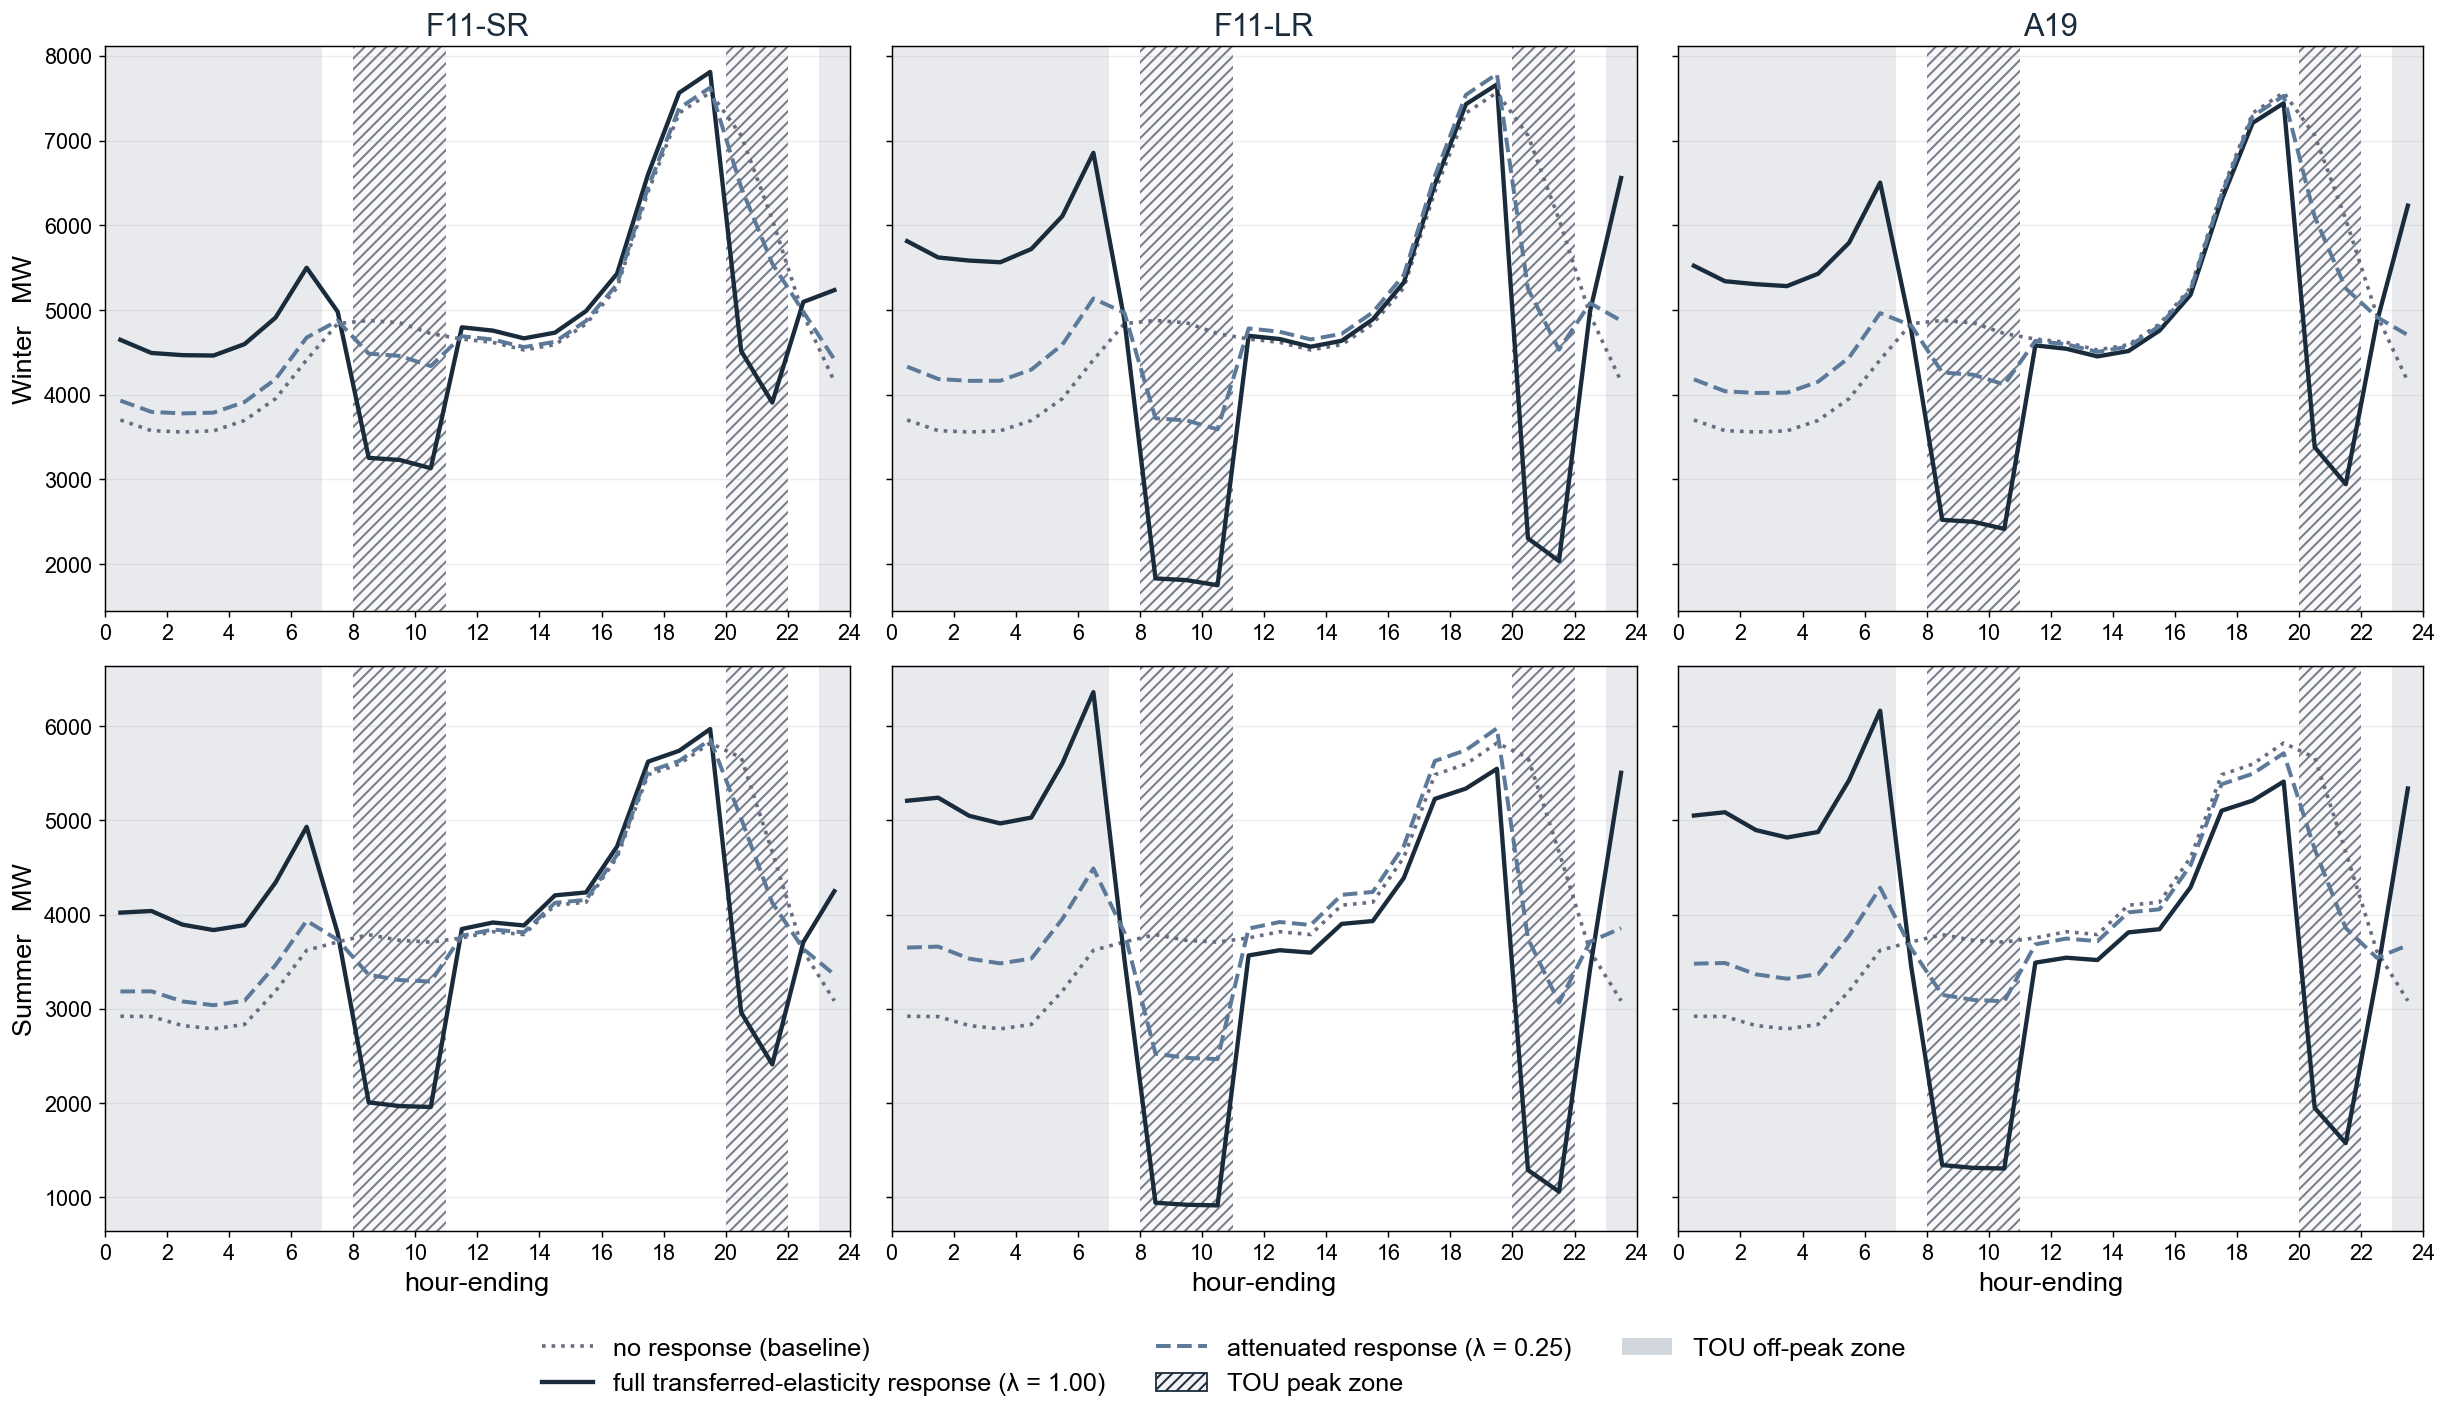

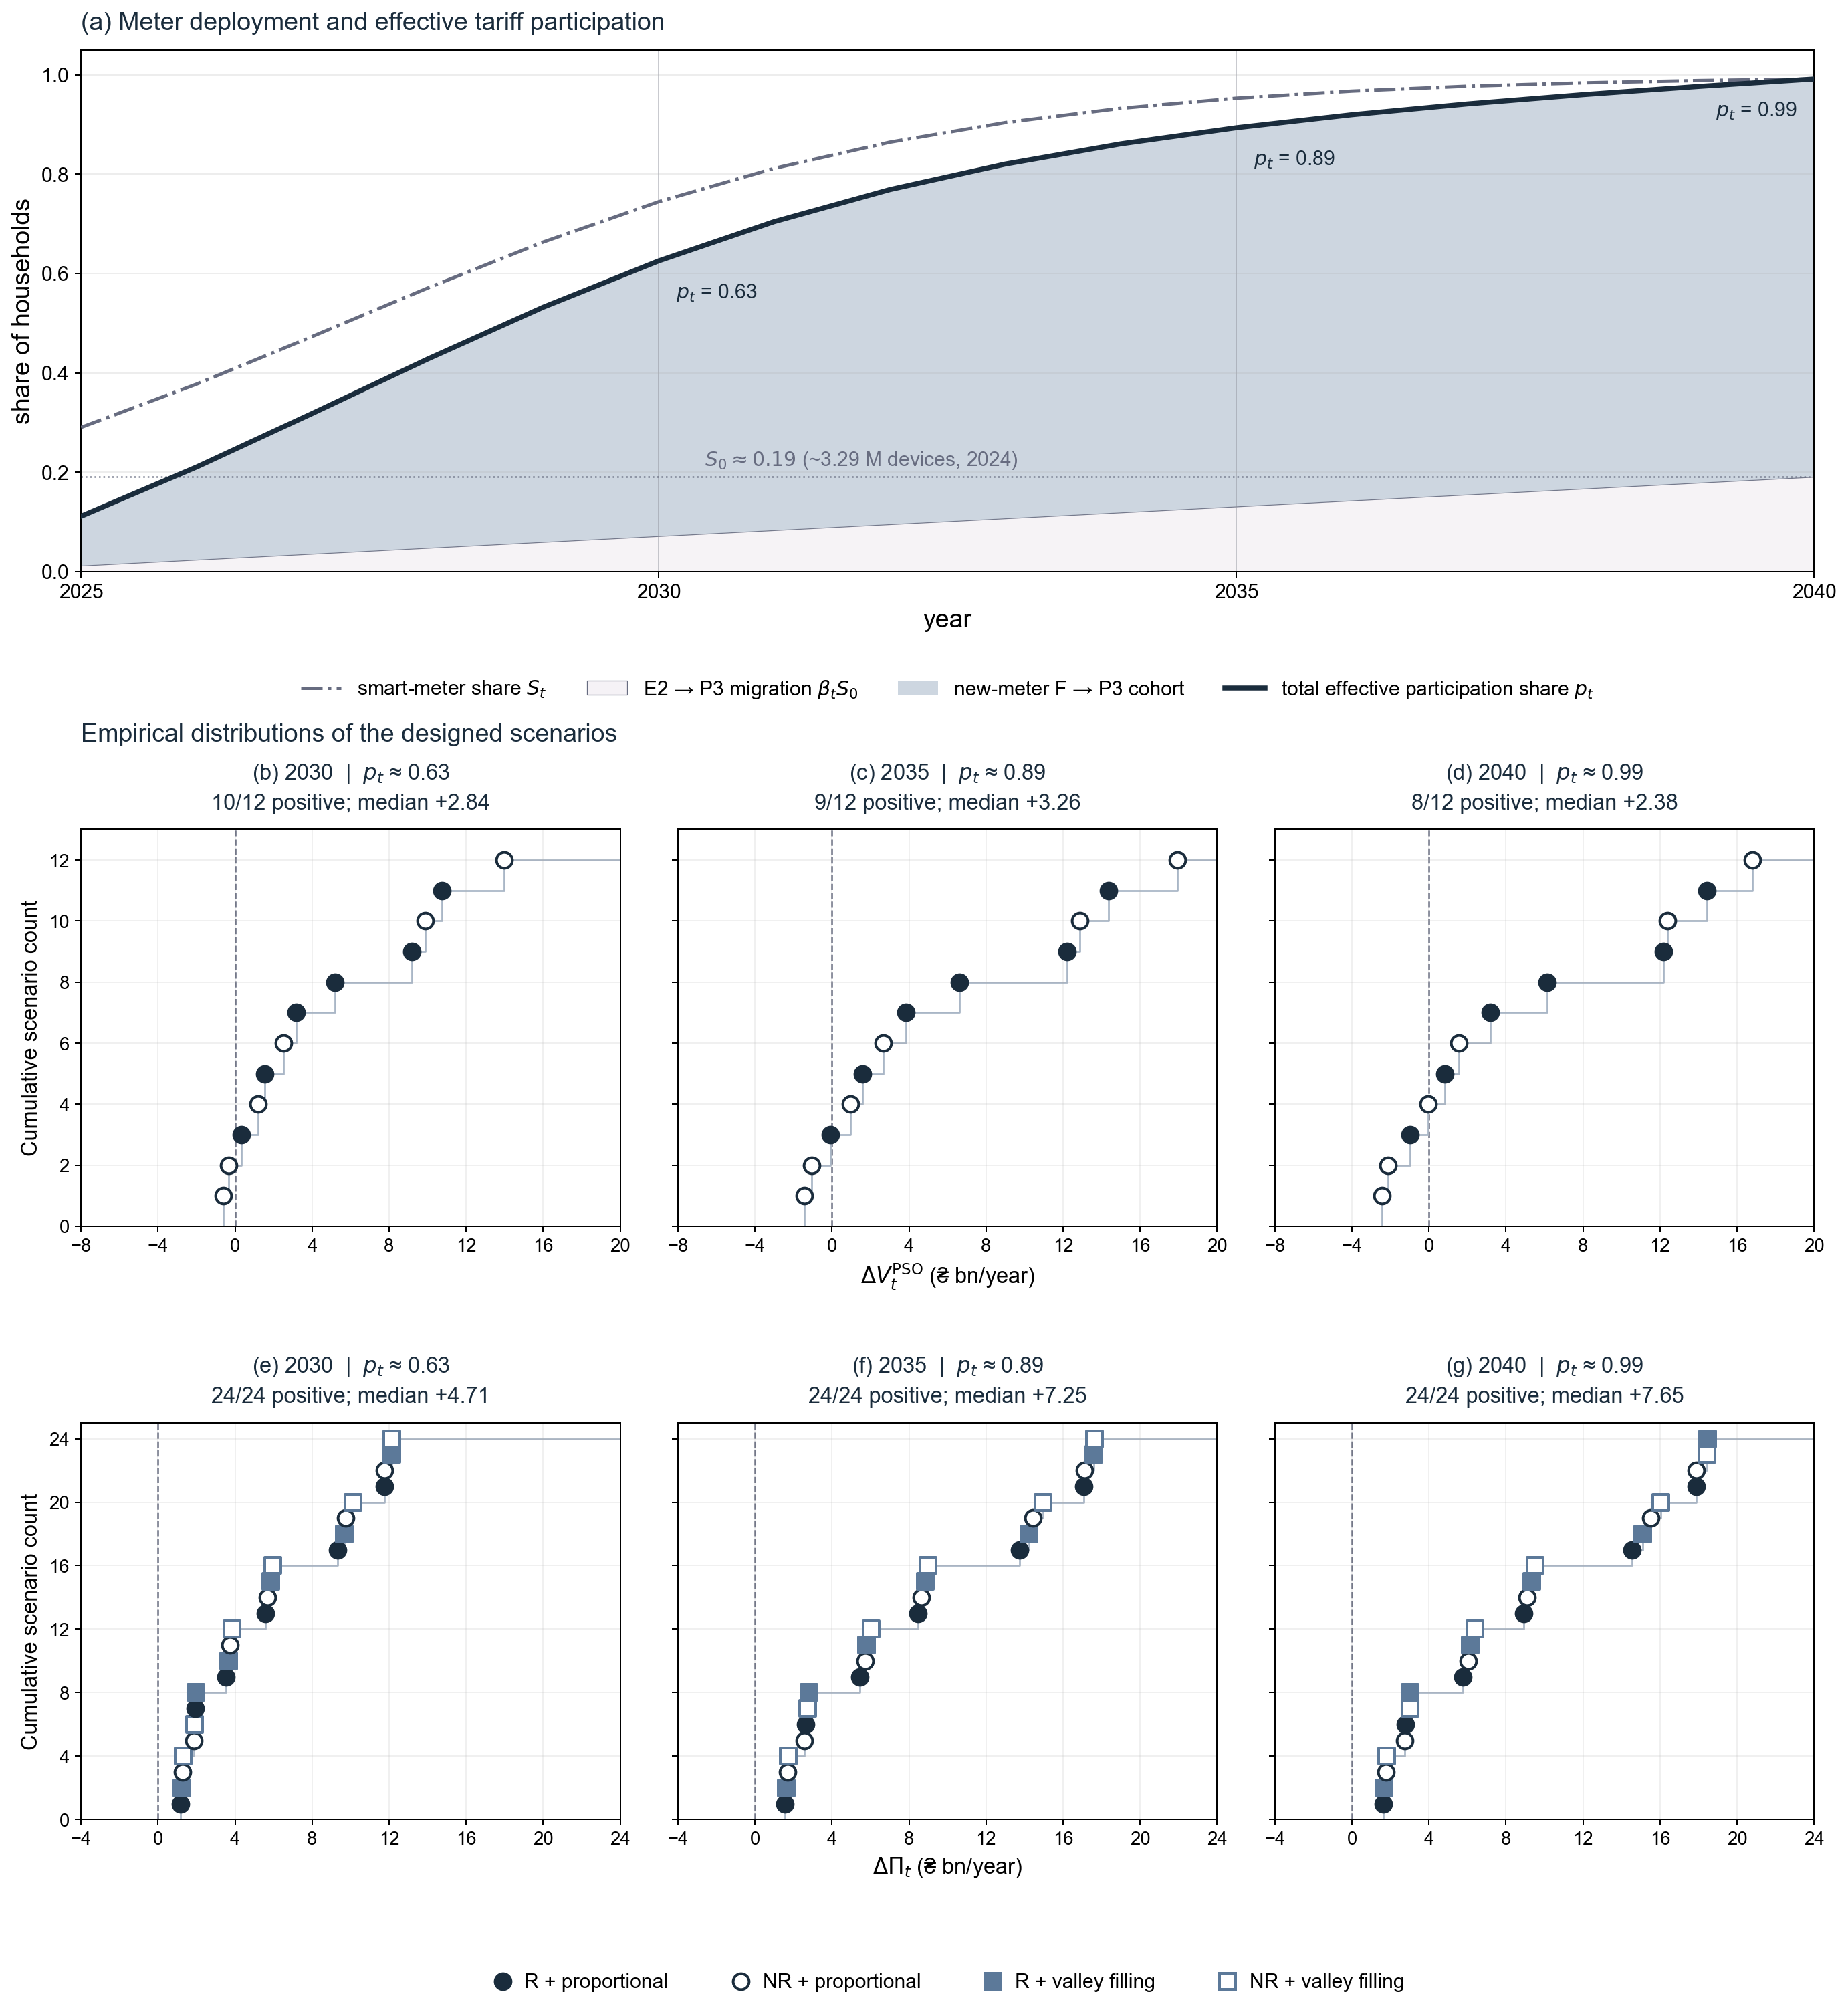

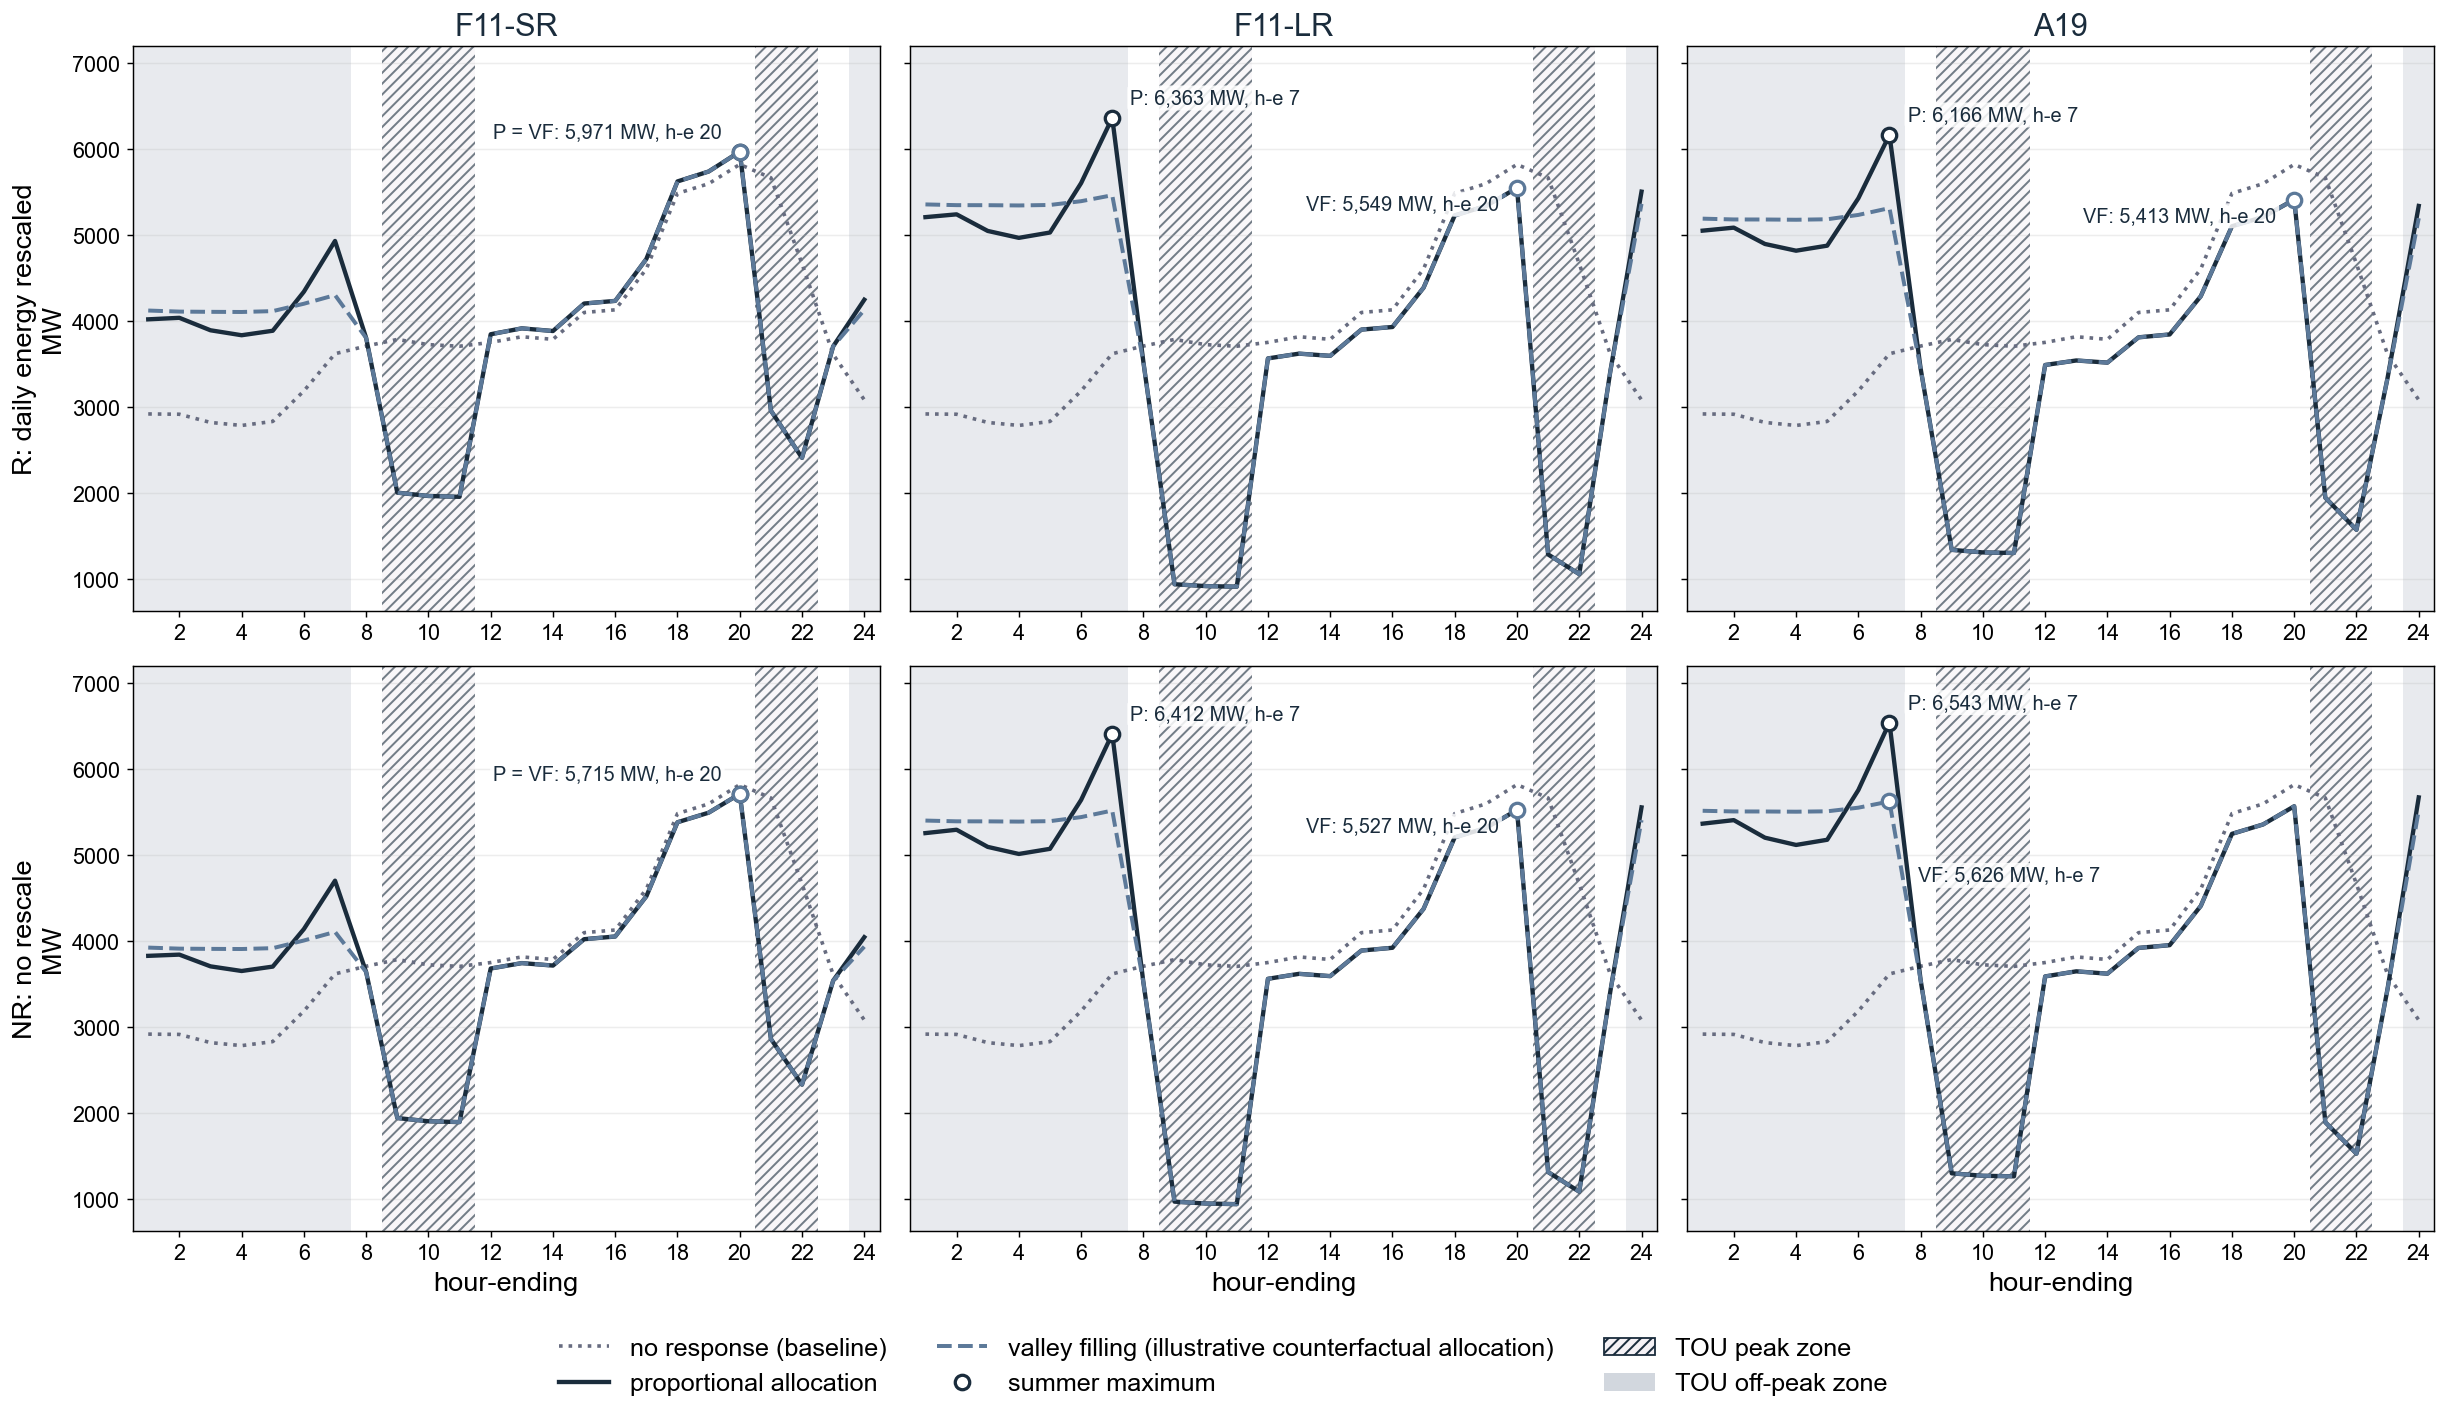

In [32]:
# --- Fig. 9 (panels a and b) and Fig. 11, with the summer profiles by energy treatment and allocation, drawn by the
# notebook from the files above ---
import _peed_fig_common as _m38fc
import make_participation_trajectory as _m38b
import make_peed_profiles_methods as _m38c
import make_peed_source_loadshift as _m38a
import peed_rollout_retailer as _m38r

importlib.reload(_m38fc)
importlib.reload(_m38a); _m38a.main()
importlib.reload(_m38r); _m38r.main()   # file 17, the data of Fig. 11b-g (dV_PSO and dPi)
importlib.reload(_m38b); _m38b.main()
importlib.reload(_m38c); _m38c.main()
display(Image(str(OUT38/"peed_source_loadshift.png")), Image(str(OUT38/"participation_trajectory.png")),
        Image(str(OUT38/"peed_profiles_methods.png")))

# §5 · Discussion

## System-side accounting (not in the article)

The system-side revenue/cost waterfall (not in the article) shows the transitions to the proposed (P3) and existing (E3) 3z tariffs. Its values in ₴
million, excluding VAT, are `retailer_waterfall_values.csv` (money tables above): the DAM-saving steps
are the combined-channel savings at $p_t=1$, valued at the DAM price plus the applicable transmission and distribution tariffs, excluding VAT; the retail steps are minus the cohort-weighted
Table 6 total bill changes. The PNG below is drawn from that file by `make_retailer_waterfall.py`,
in ₴ bn.

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_dr\retailer_waterfall_split.png  (140 KB)


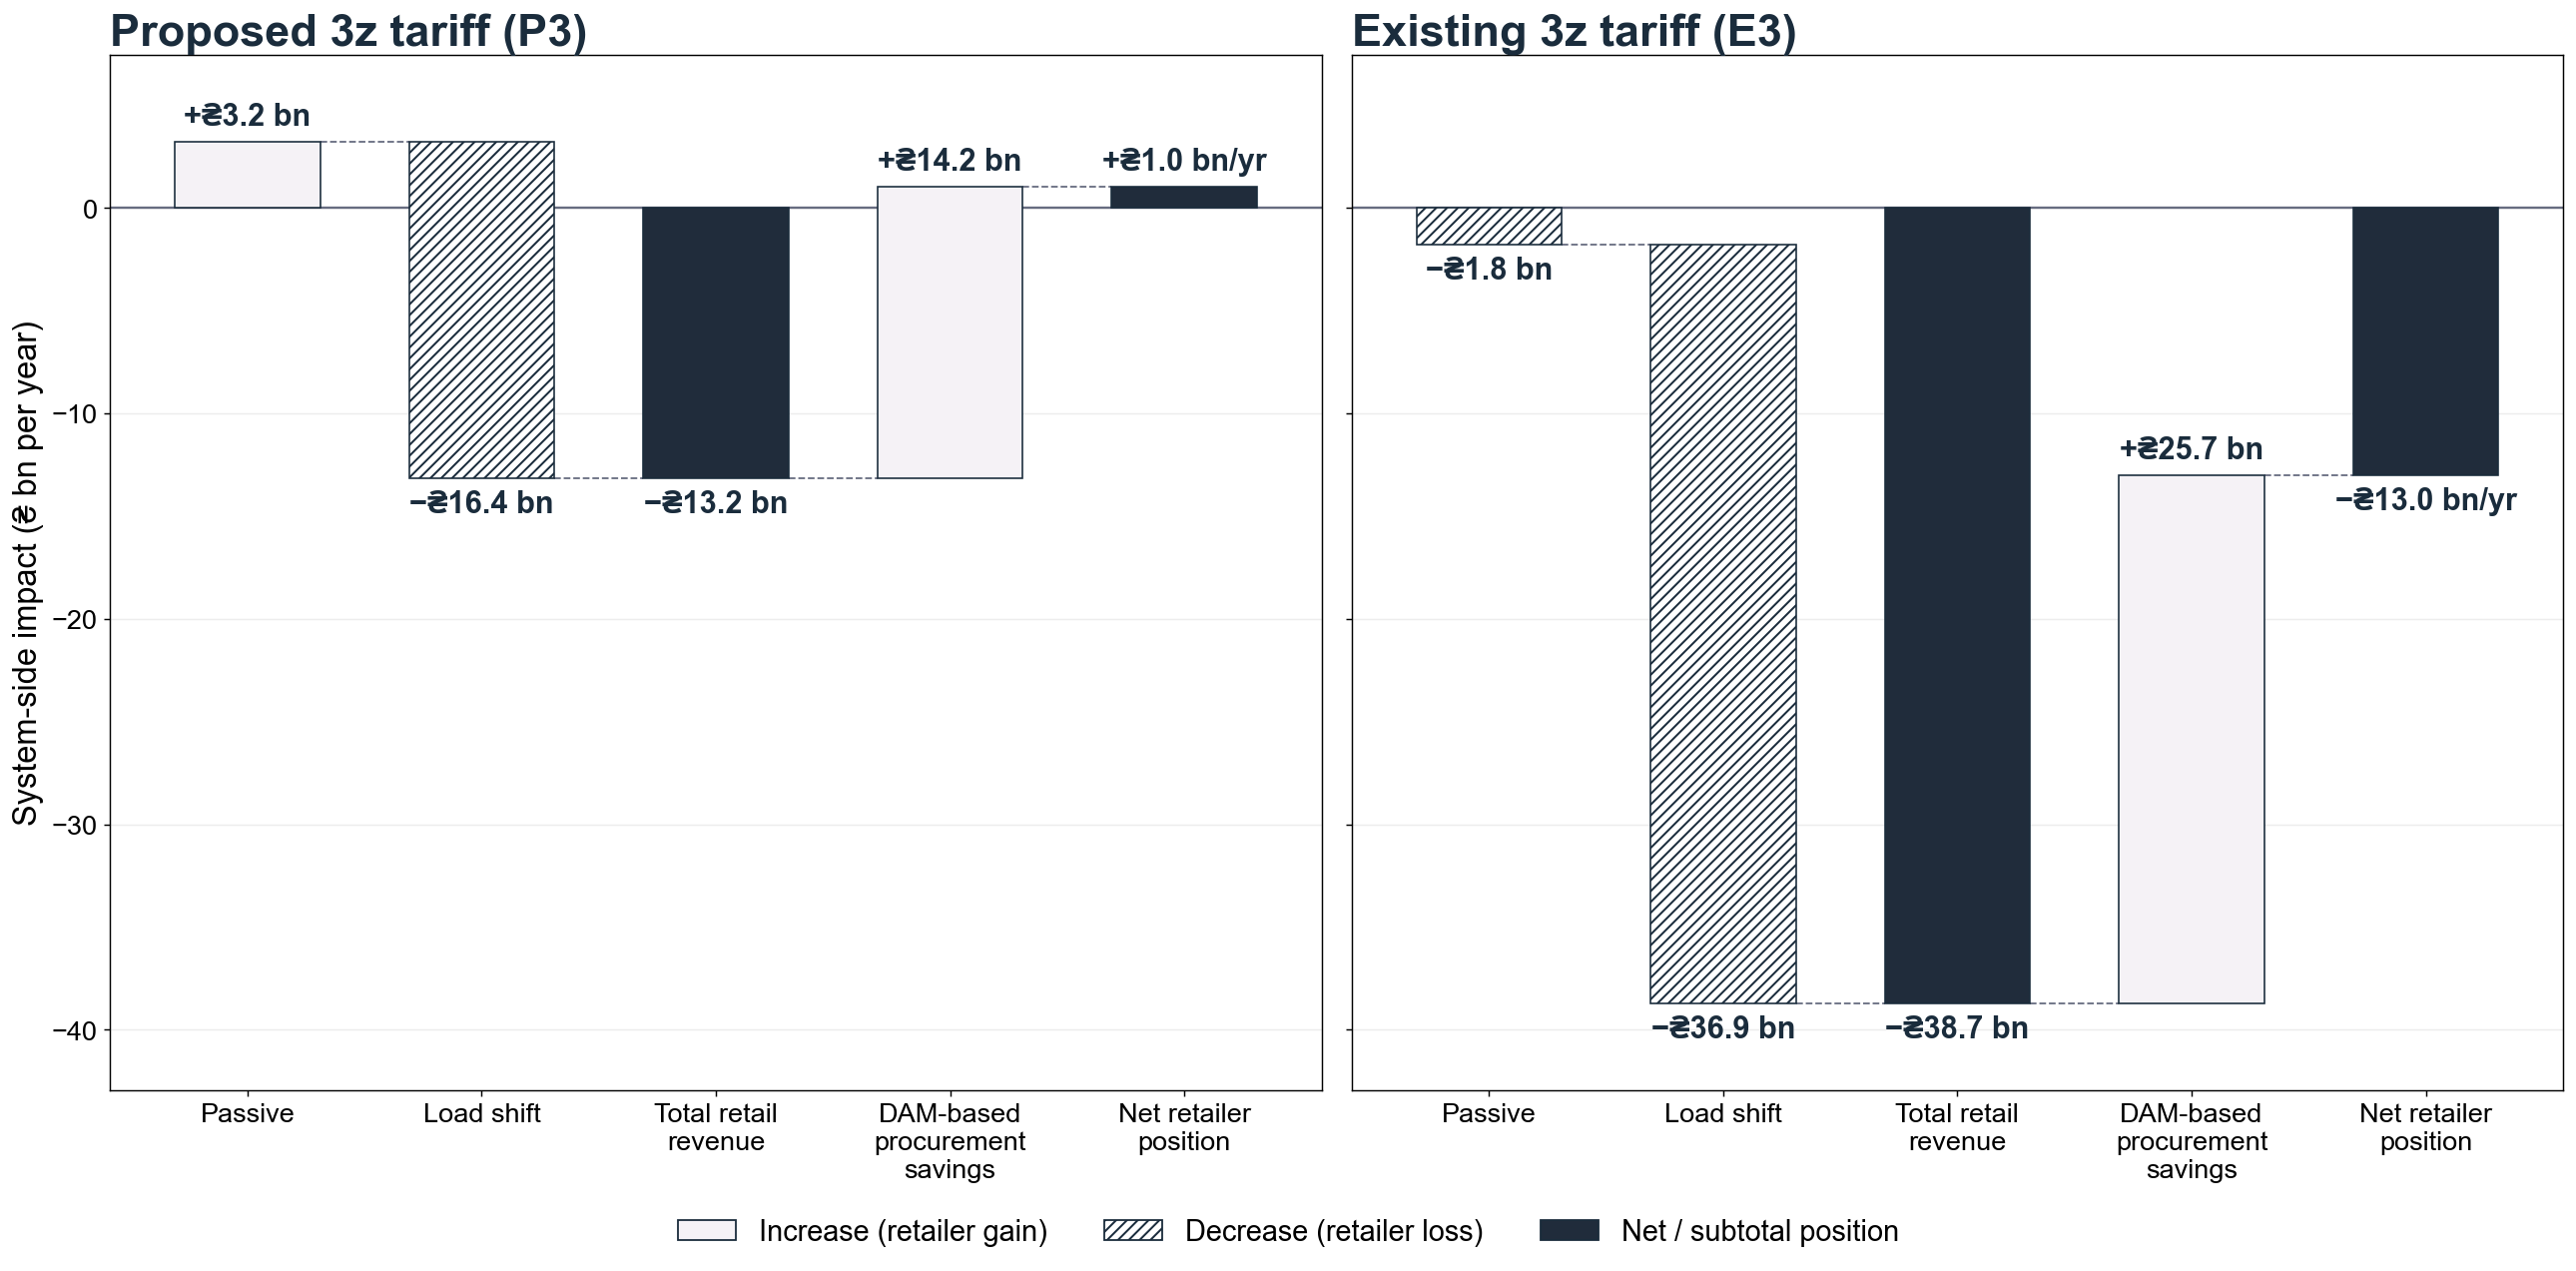

In [33]:
import make_retailer_waterfall as _m13; importlib.reload(_m13); _m13.main()
Image(str(OUT13/"retailer_waterfall_split.png"))

wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_source_retailer.png  (117 KB)
wrote outputs\ARLP_Clustering\notebook_only\layer13_peed_sensitivity\peed_retailer_lambda.png  (285 KB)


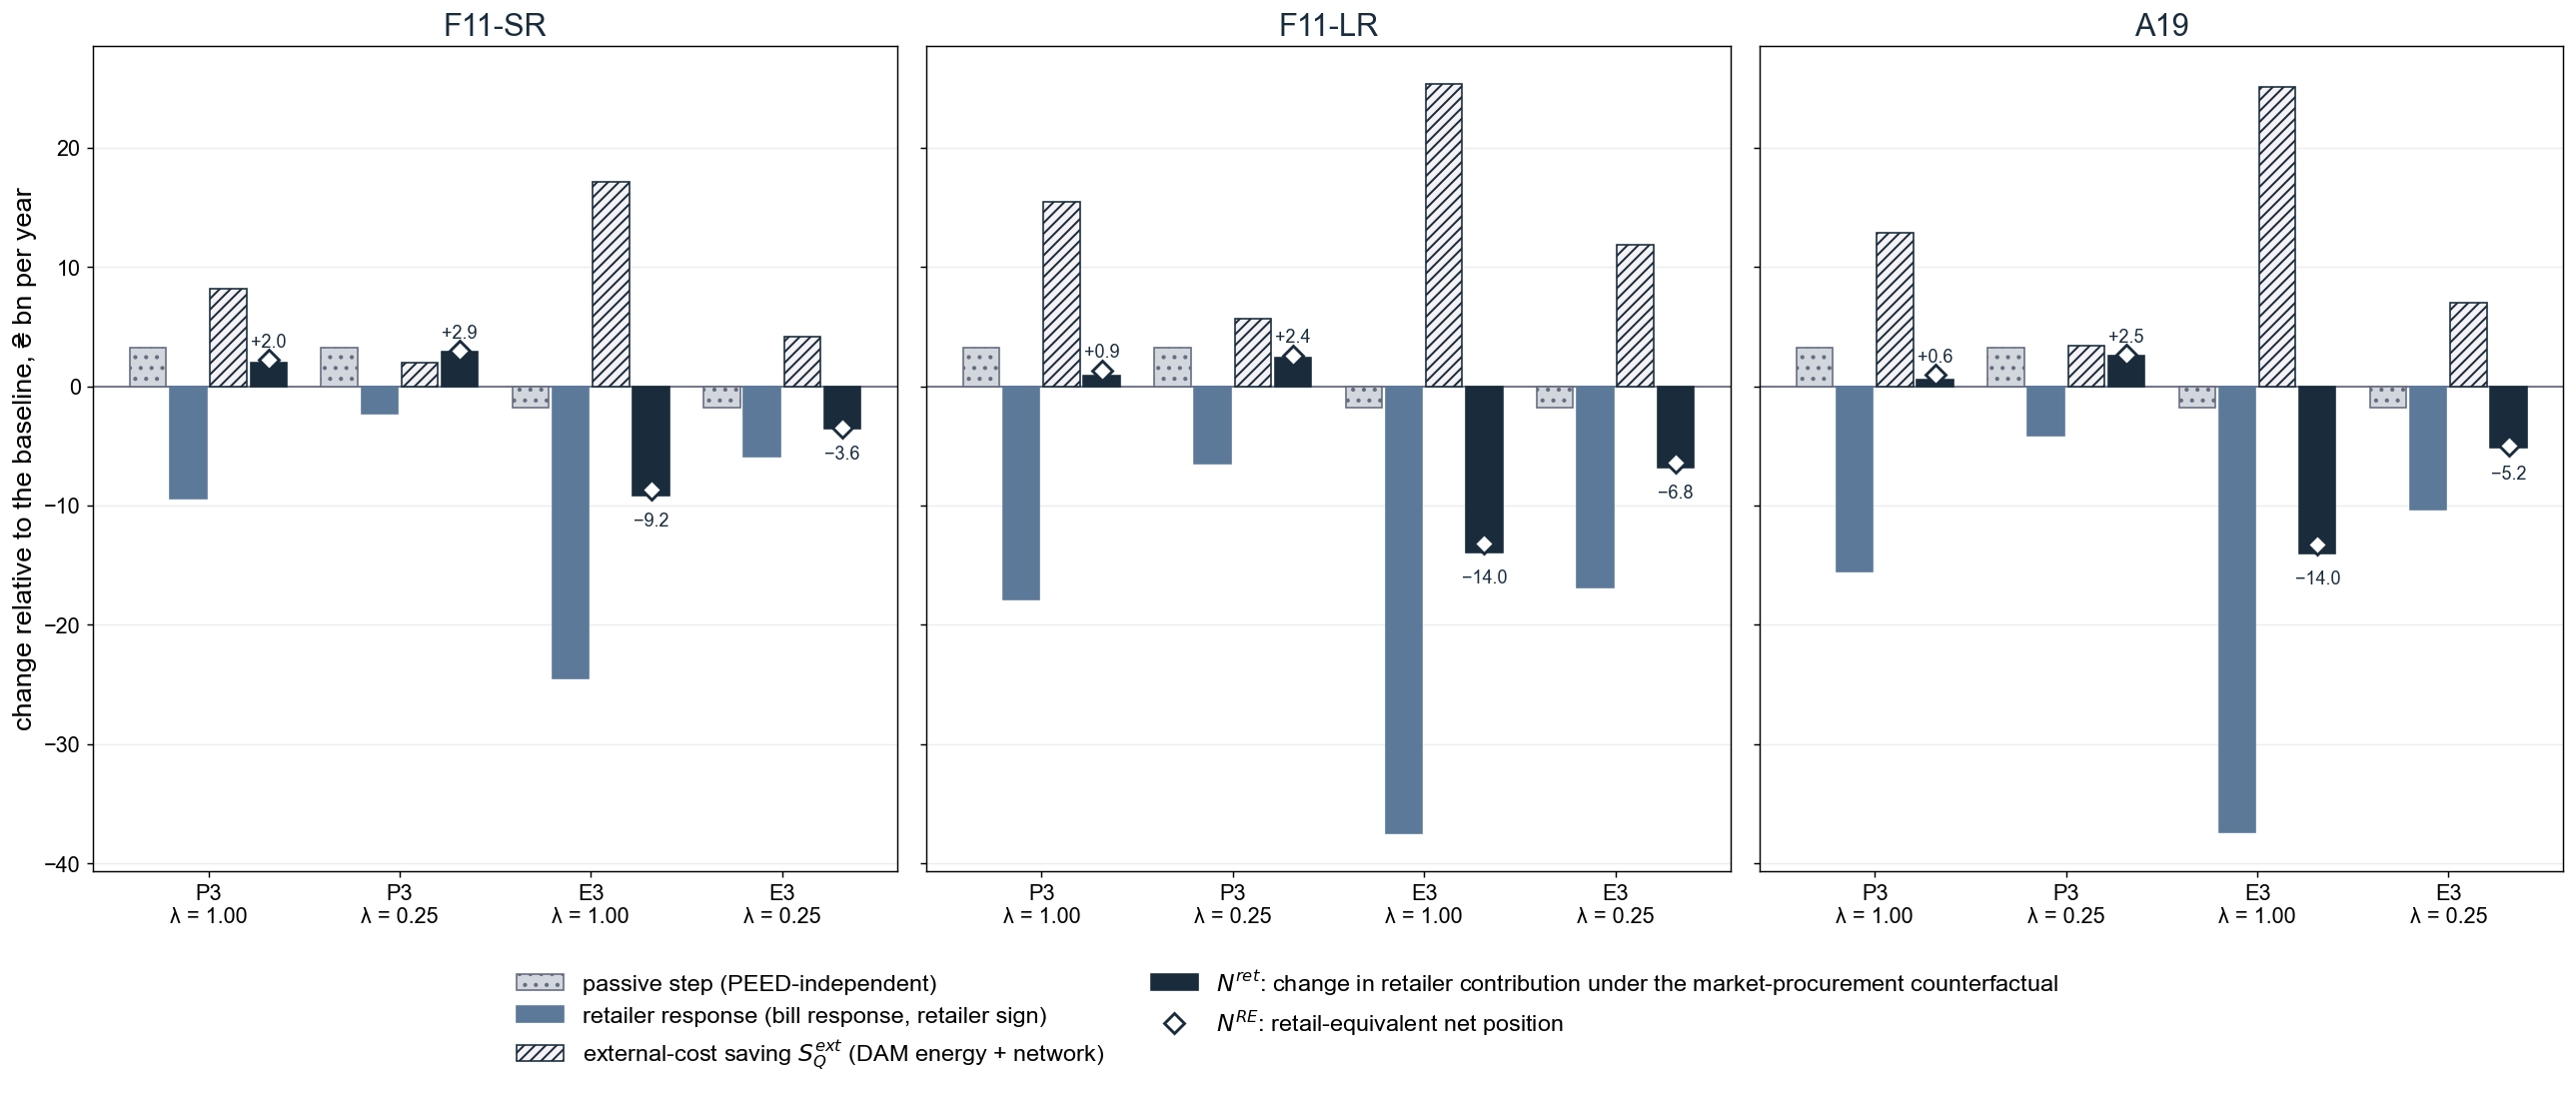

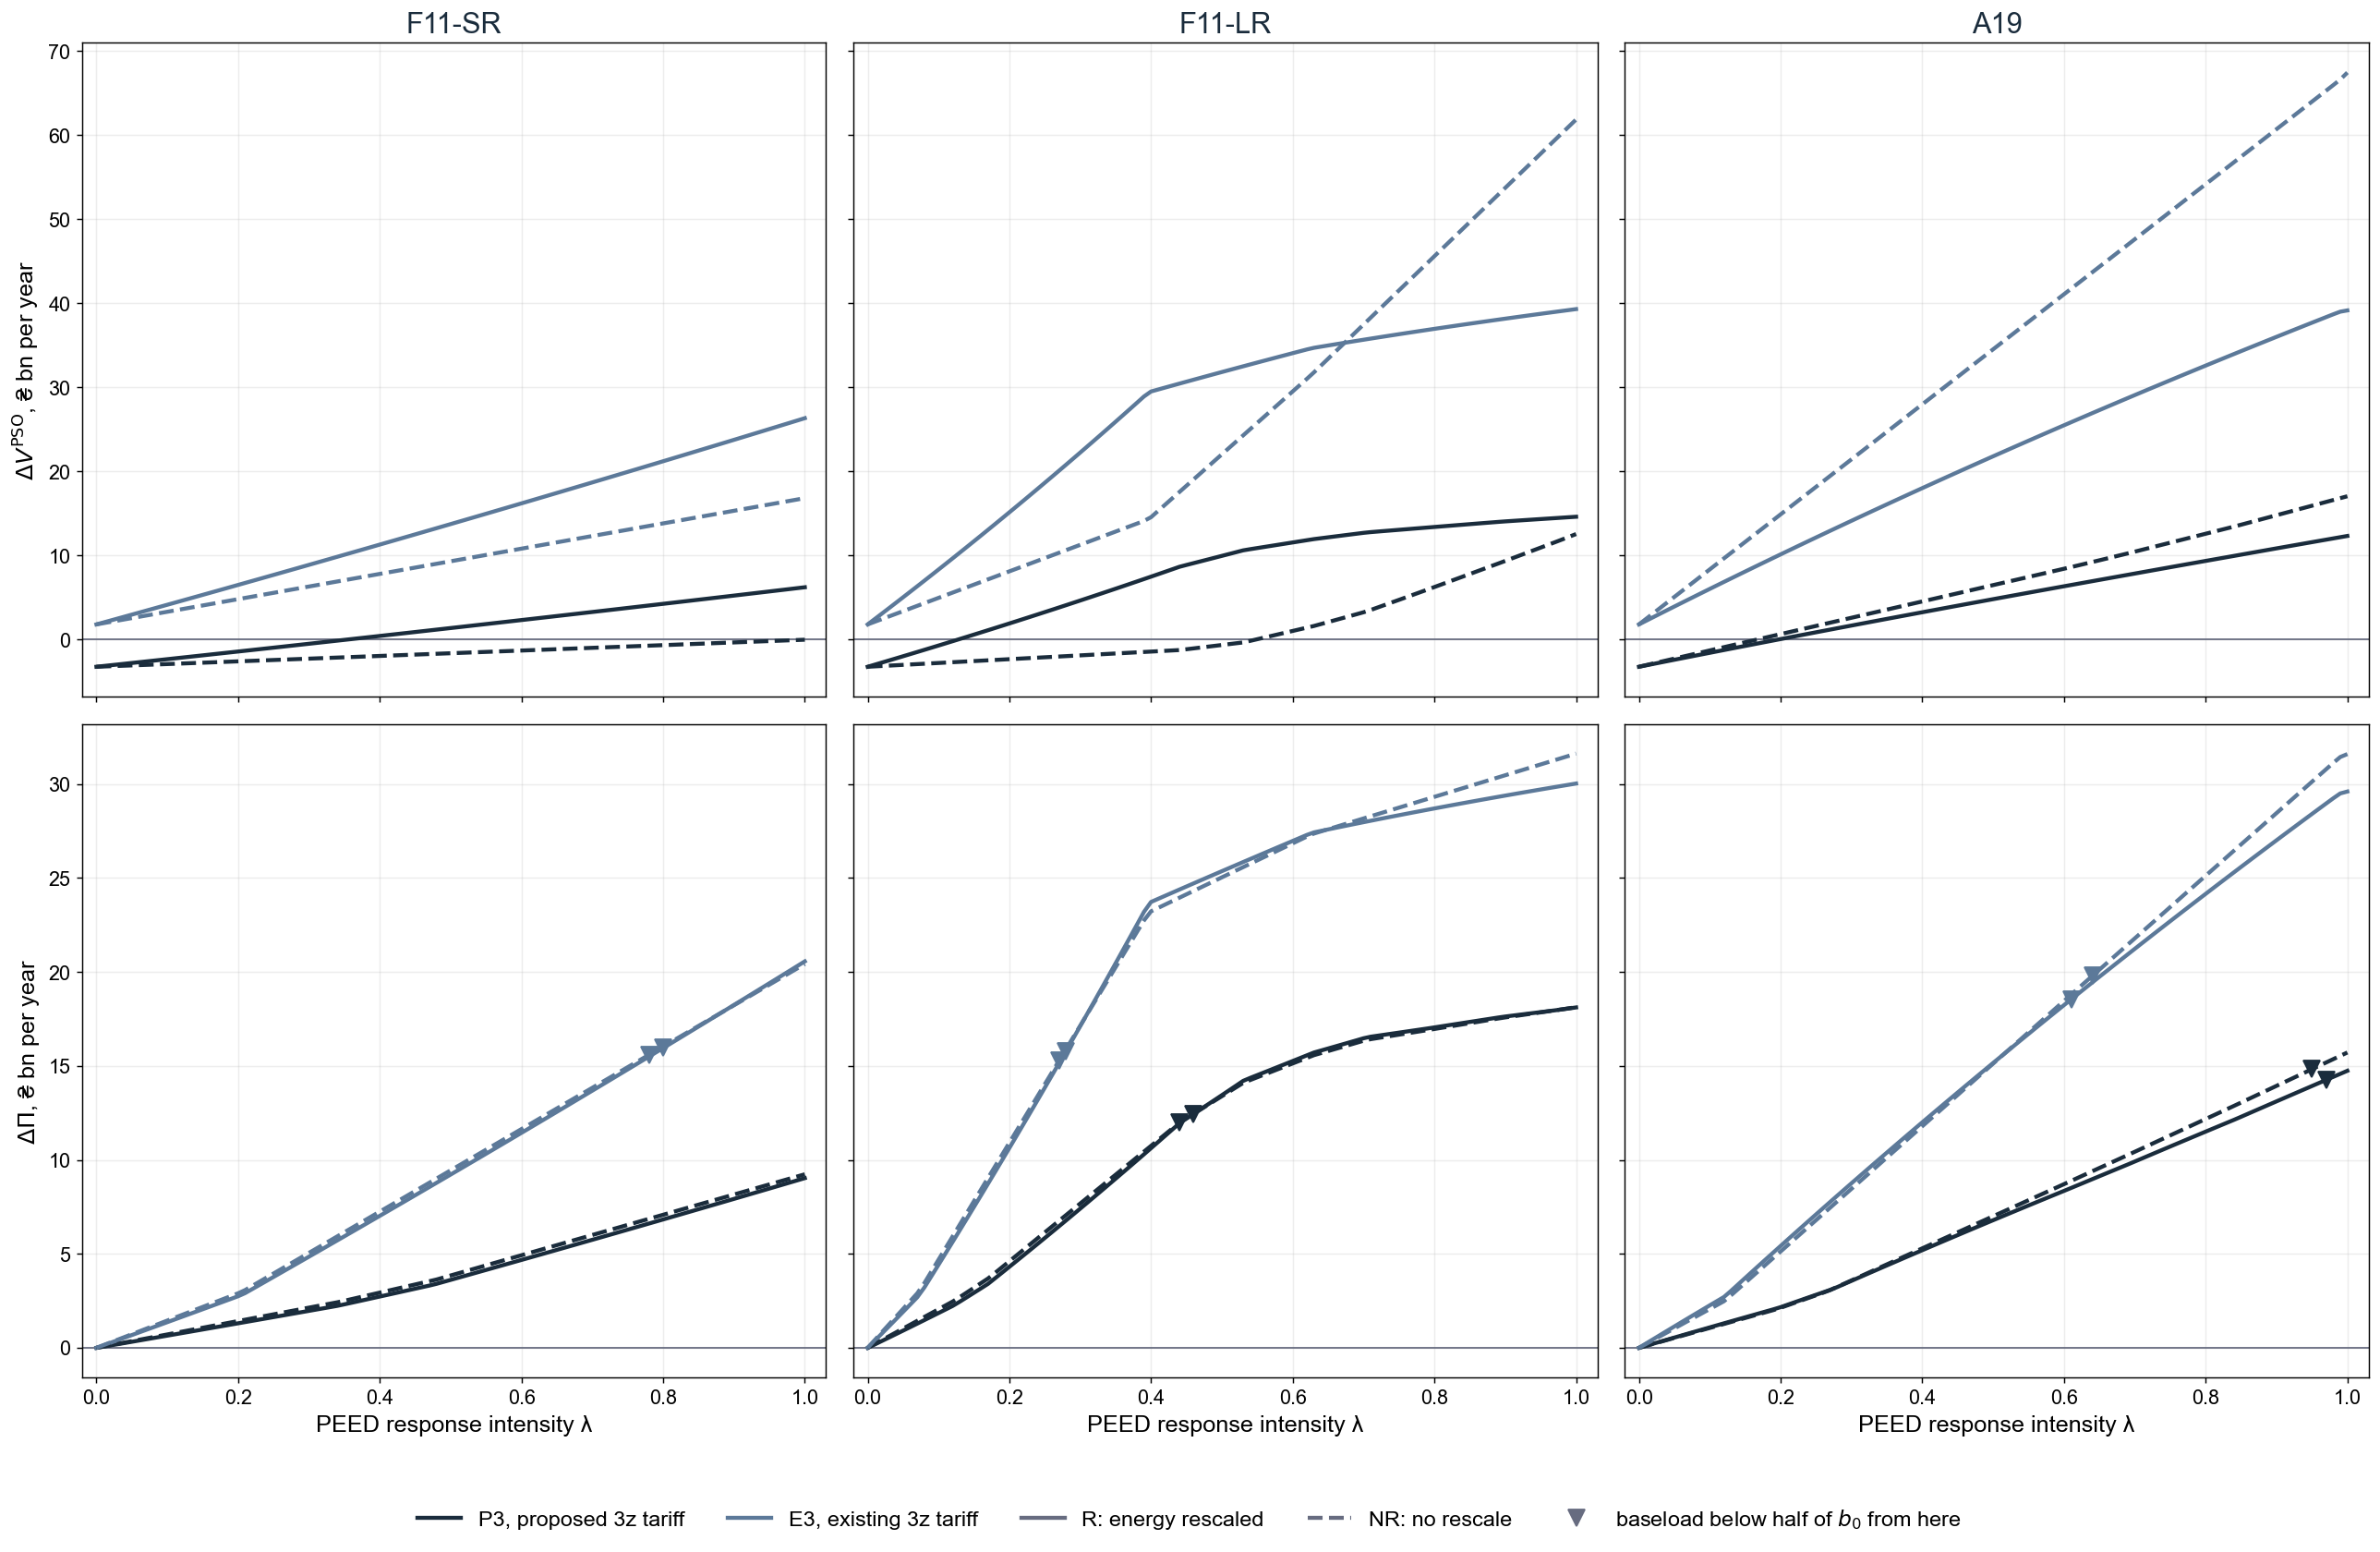

In [34]:
# --- Fig. 10: dV_PSO and dPi against lambda (make_peed_retailer_lambda); and the
# auxiliary bar figure of N^ret with N^RE beside it by PEED specification (not in the article) ---
import _peed_fig_common as _m38fc
import make_peed_retailer_lambda as _m38e
import make_peed_source_retailer as _m38d

importlib.reload(_m38fc)
importlib.reload(_m38d); _m38d.main()
importlib.reload(_m38e); _m38e.main()
display(Image(str(OUT38/"peed_source_retailer.png")), Image(str(OUT38/"peed_retailer_lambda.png")))

In [35]:
print(f"=== AUTONOMOUS NOTEBOOK COMPLETE — {len(OK)} manuscript 1:1 checks passed ===")

=== AUTONOMOUS NOTEBOOK COMPLETE — 94 manuscript 1:1 checks passed ===
